# CryptoRisk Lab: Bitcoin Downside Risk Simulation

**Research question:** To what extent does a two-state Markov regime-switching model improve 30-day Bitcoin downside-risk estimation compared with a constant-volatility geometric Brownian motion (GBM) baseline?

**Project overview.** CryptoRisk Lab will analyse historical BTC/USDT returns, estimate the probabilities of switching between calmer and more volatile market conditions, simulate alternative 30-day investment outcomes, and compare downside-risk estimates from two models. The intended measures are the probability of exceeding a loss threshold, 95% Value at Risk (VaR), and 95% Expected Shortfall (ES). A later evaluation will compare model outputs with historical observations excluded from calibration.

> **Development status: Day 2 — historical data analysis completed.** Daily BTC/USDT prices for 2022–2025 have been downloaded and validated. Daily returns, rolling volatility, descriptive visualisations, and the calibration/evaluation split are implemented. The GBM and two-state Markov simulators, risk metrics, and final model comparison are not yet implemented. Earlier fictional examples are retained as introductory exercises.
  

### Setup and reproducibility

Use Python and common scientific libraries available in free Google Colab. `SEED` is fixed for reproducibility. When external packages are needed later, install them in the first code cell.

In [1]:
# Day 1 setup: no extra package installation required in Google Colab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

print(f"NumPy {np.__version__}; Pandas {pd.__version__}")
print(f"Random seed: {SEED}")

NumPy 2.4.6; Pandas 2.2.3
Random seed: 42


## 1. Problem and question

Bitcoin returns sometimes exhibit relatively calm periods and sometimes much larger fluctuations. A constant-volatility GBM model treats daily log returns as draws from **one** fixed distribution; a two-state Markov model instead allows the distribution to depend on whether the market is currently in a low- or high-volatility state.

The goal is **not** to forecast a single future Bitcoin price or recommend trades. We will ask whether explicitly modelling changing market conditions materially changes, and potentially improves, estimates of **30-day downside risk**.

**Planned fair comparison**

| Design choice | Decision |
|---|---|
| Asset | Spot BTC/USDT, USDT-denominated (not automatically interchangeable with USD) |
| Calibration data | Daily prices from 2022–2024 |
| Held-out evaluation | Daily prices from 2025, not used for fitting |
| Investment example | 1,000 USDT; adjustable in the final demo |
| Main horizon | 30 days |
| Model A | Constant-volatility GBM |
| Model B | Two-state Markov regime switching |
| Main measures | Loss-threshold exceedance, 95% VaR, 95% ES |
| Numerical experiment | Monte Carlo with recorded seeds, replications and uncertainty intervals |

**Important scientific distinction:** Finding a different estimate is not proof that one model is more accurate. We need verification of our implementation and a clearly limited, separate evaluation against held-out observations.

### Day 1 exercise: simple returns and log returns

For strictly positive daily prices $P_t$ (USDT per BTC), a **simple return** is

$$R_t=\frac{P_t-P_{t-1}}{P_{t-1}},$$

and a **log return** is

$$r_t=\ln\!\left(\frac{P_t}{P_{t-1}}\right)=\ln(1+R_t).$$

Log returns are dimensionless and add over consecutive periods. The next cell uses small **fictional prices for learning only**, not market data.

In [2]:
def simple_returns(prices):
    """Calculate simple returns from a 1D series of positive daily prices."""
    prices = np.asarray(prices, dtype=float)
    if prices.ndim != 1 or prices.size < 2 or not np.all(np.isfinite(prices)) or np.any(prices <= 0):
        raise ValueError("Expected at least two finite, strictly positive prices")
    return prices[1:] / prices[:-1] - 1.0


def log_returns(prices):
    """Calculate natural-log returns from a 1D series of positive daily prices."""
    prices = np.asarray(prices, dtype=float)
    if prices.ndim != 1 or prices.size < 2 or not np.all(np.isfinite(prices)) or np.any(prices <= 0):
        raise ValueError("Expected at least two finite, strictly positive prices")
    return np.log(prices[1:] / prices[:-1])


# FICTIONAL example only: these are not actual BTC observations.
toy_prices = np.array([40_000.00, 40_800.00, 39_984.00, 41_183.52, 40_360.00, 41_167.20])
toy_simple = simple_returns(toy_prices)
toy_log = log_returns(toy_prices)

toy_results = pd.DataFrame({
    "Day": np.arange(2, toy_prices.size + 1),
    "Close (fictional USDT/BTC)": toy_prices[1:],
    "Simple return (%)": 100 * toy_simple,
    "Log return (%)": 100 * toy_log,
})
display(toy_results.round(4))

print(f"Day 1→2: simple return = {100 * toy_simple[0]:.4f}%; log return = {100 * toy_log[0]:.4f}%")

,Day,Close (fictional USDT/BTC),Simple return (%),Log return (%)
0,2,40800.00,2.0000,1.9803
1,3,39984.00,-2.0000,-2.0203
2,4,41183.52,3.0000,2.9559
3,5,40360.00,-1.9996,-2.0199
4,6,41167.20,2.0000,1.9803


Day 1→2: simple return = 2.0000%; log return = 1.9803%


## 2. Model, assumptions and equations

### Planned modelling assumptions

1. **Daily close data:** All model parameters will be calibrated from one consistently timestamped BTC/USDT daily-price series with documented source, timezone and missing-data checks.
2. **No future information in calibration:** Data from the held-out 2025 evaluation period will not determine 2022–2024 model parameters or regime thresholds.
3. **Two observable volatility regimes:** An initial approach will classify historical days using a trailing volatility estimate, such as a 14-day rolling standard deviation, and a threshold computed on calibration data alone. We will document sensitivity to the window and threshold. Regimes are a modelling convenience, not directly observed physical states.
4. **Conditional return distributions:** Each regime will initially have a separately estimated normal distribution for *daily log returns*. Bitcoin returns may have heavier tails, so normality is a limitation to test and disclose.
5. **First-order Markov transition:** Tomorrow's regime depends probabilistically on today's regime, according to a fitted $2\times2$ transition matrix.
6. **No trading costs or leverage:** Main experiments use buy-and-hold investment value. This is a downside-risk simulator, not a trading system.

### A. Constant-volatility GBM baseline

With daily log-return parameters $\mu$ (mean log return per day) and $\sigma$ (standard deviation of log return per square root of day under the diffusion interpretation), the discrete daily update is

$$V_{t+1}=V_t\exp(\mu+\sigma\varepsilon_t), \qquad \varepsilon_t\sim\mathcal{N}(0,1).$$

For the day-by-day implementation, $\mu$ and $\sigma$ are estimated directly from historical **daily log returns**. They remain fixed throughout a simulated path. $V_t$ is investment value in USDT.

### B. Two-state Markov regime-switching model

Let $Z_t=0$ represent a calm market and $Z_t=1$ a volatile market. The transition matrix is

$$\mathbf{P}=\begin{bmatrix}p_{00}&p_{01}\\p_{10}&p_{11}\end{bmatrix},\quad p_{ij}=\Pr(Z_{t+1}=j\mid Z_t=i),\quad \sum_j p_{ij}=1.$$

Once the next state is drawn, a regime-dependent log return is generated:

$$r_{t+1}\mid Z_{t+1}=j\sim\mathcal{N}(\mu_j,\sigma_j^2),\qquad V_{t+1}=V_t\exp(r_{t+1}).$$

The implementation will define precisely how historical volatility labels align with return observations, so that fitting and simulation use consistent state timing.

### C. Downside risk measures

For initial investment $V_0$, horizon $T=30$ trading/calendar days of daily BTC data, and loss fraction $\ell$, the threshold-exceedance probability is

$$q_\ell=\Pr\bigl(V_T<(1-\ell)V_0\bigr).$$

Define the simulated monetary loss as $L=V_0-V_T$ (USDT). Then

$$\operatorname{VaR}_{0.95}=\text{95th percentile of }L,\qquad
\operatorname{ES}_{0.95}=\mathbb{E}[L\mid L\geq \operatorname{VaR}_{0.95}]$$

for a continuous loss distribution. Monte Carlo estimates will report seeds, repetitions and uncertainty. For example, a 35% loss threshold on 1,000 USDT means a final value **below 650 USDT**.

### Links to the modelling concepts

| Concept | Role in the project |
|---|---|
| Input modelling and random variate generation | Fit return distributions and sample shocks |
| Discrete-time Markov chains | Estimate and simulate transitions between volatility states |
| Monte Carlo integration and the law of large numbers | Estimate loss probabilities and their uncertainty from simulated paths |

### Day 1 exercise: estimating a transition matrix from fictional market states

Suppose we have classified a short fictional sequence of days as `0` (calm) or `1` (volatile). For each consecutive pair, count a transition from current state to next state. Divide each row by its total to obtain transition probabilities.

This exercise is **not** a calibration result. We will replace the fictional sequence with state labels derived from real BTC data.

In [3]:
# FICTIONAL state sequence, for learning how a Markov matrix is estimated.
toy_states = np.array([0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1], dtype=int)

transition_counts = np.zeros((2, 2), dtype=int)
for current_state, next_state in zip(toy_states[:-1], toy_states[1:]):
    transition_counts[current_state, next_state] += 1

row_totals = transition_counts.sum(axis=1, keepdims=True)
assert np.all(row_totals > 0), "Every state must have an observed outgoing transition"
toy_transition_matrix = transition_counts / row_totals

print("Illustrative transition counts (rows=current, columns=next):")
print(transition_counts)
print("Illustrative transition matrix:")
print(np.round(toy_transition_matrix, 4))

Illustrative transition counts (rows=current, columns=next):
[[4 3]
 [2 3]]
Illustrative transition matrix:
[[0.5714 0.4286]
 [0.4    0.6   ]]


## 3. Implementation

**Implementation roadmap — not yet completed**

- **Data preparation:** Load daily BTC/USDT prices from a documented public dataset; inspect duplicates, missing days, timestamps, and outliers; calculate log returns.
- **GBM:** Fit one daily $\mu$ and $\sigma$ from the calibration sample, then simulate repeated 30-day paths.
- **Regime model:** Calculate trailing volatility, label calm and volatile observations using training-only thresholds, estimate the transition matrix and regime-specific return parameters, then simulate regime and price paths.
- **Risk function:** Estimate $\Pr(V_T<(1-\ell)V_0)$, VaR and ES from terminal outcomes.
- **Reproducibility:** Use explicit random seeds; preserve all assumptions and units; ensure the notebook runs top-to-bottom without manual file paths.


**Implementation status:** Historical data collection, dataset verification, return calculations, rolling-volatility analysis, visualisation, and chronological dataset splitting are complete. The remaining implementation work includes GBM simulation, Markov regime switching, downside-risk metrics, model verification, and experiments.
  


### 3.1 Historical BTC/USDT Data Collection

This section retrieves daily BTC/USDT spot-market candlestick data from Binance's public monthly archives for 2022–2025.

- Calibration period: 2022–2024
- Held-out evaluation period: 2025
- Sampling frequency: one day
- Timestamps: UTC
- Source: https://github.com/binance/binance-public-data

The data is downloaded programmatically to keep the notebook reproducible in Google Colab. The price series and timestamps are checked before model calibration.


In [4]:

import io
import zipfile
import requests
import pandas as pd
import numpy as np

SYMBOL = "BTCUSDT"
INTERVAL = "1d"
BASE_URL = "https://data.binance.vision/data/spot/monthly/klines"

KLINE_COLUMNS = [
    "open_time", "open", "high", "low", "close",
    "volume", "close_time", "quote_volume",
    "trade_count", "taker_buy_base",
    "taker_buy_quote", "ignore"
]

monthly_frames = []

for year in range(2022, 2026):
    for month in range(1, 13):
        filename = f"{SYMBOL}-{INTERVAL}-{year}-{month:02d}.zip"
        url = f"{BASE_URL}/{SYMBOL}/{INTERVAL}/{filename}"

        response = requests.get(url, timeout=45)
        response.raise_for_status()

        with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
            csv_file = next(
                name for name in archive.namelist()
                if name.endswith(".csv")
            )
            raw = pd.read_csv(archive.open(csv_file), header=None)

        assert raw.shape[1] == 12, f"Unexpected format: {filename}"

        # Some archives may include a header row.
        if pd.isna(pd.to_numeric(raw.iloc[0, 0], errors="coerce")):
            raw = raw.iloc[1:].copy()

        raw.columns = KLINE_COLUMNS

        # Binance changed spot timestamp units in 2025.
        unit = "us" if year >= 2025 else "ms"

        raw["date"] = pd.to_datetime(
            pd.to_numeric(raw["open_time"]),
            unit=unit,
            utc=True
        )
        raw["close"] = pd.to_numeric(raw["close"])

        monthly_frames.append(raw[["date", "close"]])

price_df = (
    pd.concat(monthly_frames, ignore_index=True)
    .sort_values("date")
    .reset_index(drop=True)
)

print("Downloaded daily observations:", len(price_df))
print("First date:", price_df["date"].min())
print("Last date:", price_df["date"].max())

display(price_df.head())
display(price_df.tail())


Downloaded daily observations: 1461
First date: 2022-01-01 00:00:00+00:00
Last date: 2025-12-31 00:00:00+00:00


,date,close
0,2022-01-01 00:00:00+00:00,47722.65
1,2022-01-02 00:00:00+00:00,47286.18
2,2022-01-03 00:00:00+00:00,46446.10
3,2022-01-04 00:00:00+00:00,45832.01
4,2022-01-05 00:00:00+00:00,43451.13


,date,close
1456,2025-12-27 00:00:00+00:00,87877.01
1457,2025-12-28 00:00:00+00:00,87952.71
1458,2025-12-29 00:00:00+00:00,87237.13
1459,2025-12-30 00:00:00+00:00,88485.49
1460,2025-12-31 00:00:00+00:00,87648.22



### 3.1.1 Dataset Integrity and Verification

Before performing statistical analysis or model calibration, the historical Bitcoin dataset must be checked for completeness, consistency, and validity.

The following checks are performed:

1. **Observation count:** Confirm that the dataset contains 1,461 daily observations between 1 January 2022 and 31 December 2025.
2. **Duplicate detection:** Verify that each trading date appears only once.
3. **Missing values:** Confirm that every daily observation contains a valid closing price.
4. **Price validity:** Ensure all closing prices are finite and strictly positive.
5. **Date continuity:** Verify that the dataset contains consecutive daily UTC timestamps without unexpected gaps.

These checks are important because missing observations, incorrect timestamps, or invalid prices could distort calculated returns, volatility estimates, and subsequent risk simulations.

Python assertions are used so that the notebook stops with an error if a required data-quality condition is not satisfied.

**Expected outcome:** All integrity checks pass before proceeding with return calculations.

**Note:** These checks verify the integrity of the input dataset, not the correctness of the final simulation models.


In [5]:

# Dataset integrity checks

assert len(price_df) == 1461, "Unexpected number of daily observations"

assert not price_df["date"].duplicated().any(), \
    "Duplicate dates detected"

assert price_df["close"].notna().all(), \
    "Missing closing prices detected"

assert np.isfinite(price_df["close"]).all(), \
    "Non-finite prices detected"

assert (price_df["close"] > 0).all(), \
    "Invalid non-positive prices detected"

expected_dates = pd.date_range(
    "2022-01-01",
    "2025-12-31",
    freq="D",
    tz="UTC"
)

pd.testing.assert_index_equal(
    pd.DatetimeIndex(price_df["date"]),
    expected_dates,
    check_names=False
)

print("PASS: Daily observations cover the expected dates")
print("PASS: No duplicate or missing dates")
print("PASS: All closing prices are positive and finite")


PASS: Daily observations cover the expected dates
PASS: No duplicate or missing dates
PASS: All closing prices are positive and finite



### 3.2 Daily Returns and Descriptive Statistics

Historical Bitcoin closing prices are converted into daily returns to analyse relative price movements.

Two return measures are calculated.

#### Simple Return

$$
R_t = \frac{P_t-P_{t-1}}{P_{t-1}}
$$

#### Logarithmic Return

$$
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
$$

where:

- $P_t$ = Bitcoin closing price on day $t$ (USDT per BTC).
- $P_{t-1}$ = closing price on the previous day.
- $R_t$ = simple daily return.
- $r_t$ = daily logarithmic return.

Log returns are used for model calibration because they are additive over consecutive periods and are convenient for multiplicative asset-price simulations.

The mean and sample standard deviation of log returns are calculated to summarise historical return behaviour.

The first observation has an undefined return because no preceding closing price is available within the dataset.

#### Numerical Verification

The following mathematical relationship is checked using NumPy:

$$
R_t = e^{r_t}-1
$$

The `assert_allclose()` function verifies that the calculated simple and log returns satisfy this relationship within a strict numerical tolerance.


In [6]:

price_df["simple_return"] = price_df["close"].pct_change()

price_df["log_return"] = np.log(
    price_df["close"] / price_df["close"].shift(1)
)

# Verify the relationship between both return definitions.
valid = price_df["log_return"].notna()

np.testing.assert_allclose(
    np.exp(price_df.loc[valid, "log_return"]) - 1,
    price_df.loc[valid, "simple_return"],
    rtol=1e-12,
    atol=1e-12
)

print("PASS: Simple and log returns are consistent")

display(price_df.head(10))

print("Mean daily log return:",
      price_df["log_return"].mean())

print("Daily log-return standard deviation:",
      price_df["log_return"].std())


PASS: Simple and log returns are consistent


,date,close,simple_return,log_return
0,2022-01-01 00:00:00+00:00,47722.65,NaN,NaN
1,2022-01-02 00:00:00+00:00,47286.18,-0.009146,-0.009188
2,2022-01-03 00:00:00+00:00,46446.10,-0.017766,-0.017926
3,2022-01-04 00:00:00+00:00,45832.01,-0.013222,-0.013310
4,2022-01-05 00:00:00+00:00,43451.13,-0.051948,-0.053346
5,2022-01-06 00:00:00+00:00,43082.31,-0.008488,-0.008524
6,2022-01-07 00:00:00+00:00,41566.48,-0.035185,-0.035818
7,2022-01-08 00:00:00+00:00,41679.74,0.002725,0.002721
8,2022-01-09 00:00:00+00:00,41864.62,0.004436,0.004426
9,2022-01-10 00:00:00+00:00,41822.49,-0.001006,-0.001007


Mean daily log return: 0.00041638710627276625
Daily log-return standard deviation: 0.026947362043599304



### 3.3 Rolling Volatility Analysis

Bitcoin's daily returns do not fluctuate with the same intensity throughout time. Some periods experience relatively small price movements, while others experience substantially larger fluctuations.

To examine this behaviour, a **14-day rolling standard deviation of daily log returns** is calculated.

#### Mathematical formulation

The rolling sample volatility is defined as:

$$
s_{t,w} =
\sqrt{
\frac{1}{w-1}
\sum_{i=t-w+1}^{t}
(r_i-\bar r_{t,w})^2
}
$$

where:

- $s_{t,w}$ = rolling sample standard deviation of daily log returns.
- $r_i$ = daily Bitcoin log return on day $i$.
- $\bar r_{t,w}$ = mean log return within the rolling window.
- $w$ = rolling-window length, set to 14 days.
- $t$ = current observation date.

The resulting volatility is dimensionless and represents the standard deviation of daily log returns, rather than annualised volatility.

#### Implementation approach

Pandas `rolling()` and `std(ddof=1)` are used to calculate the standard deviation of each consecutive 14-return window.

The calculation includes only the current and previous observations, avoiding the use of future returns.

The initial observations without 14 available daily returns will have undefined rolling-volatility values (`NaN`). These are expected and will be handled appropriately during regime classification.

#### Relevance to the research

Rolling volatility provides a historical measure of changing market variability. It will help define relatively calm and volatile market conditions for the two-state Markov regime-switching model.

The 14-day window is an initial modelling choice. Its suitability and the sensitivity of the results to alternative window lengths will be investigated later.

**Important:** Volatility measures the magnitude of return fluctuations, not whether Bitcoin prices are increasing or decreasing.

**Reference:** S.-H. Poon and C. W. J. Granger, "Forecasting Volatility in Financial Markets: A Review," *Journal of Economic Literature*, vol. 41, no. 2, pp. 478–539, 2003. DOI: https://doi.org/10.1257/jel.41.2.478


In [7]:

WINDOW = 14

price_df["rolling_vol_14d"] = (
    price_df["log_return"]
    .rolling(window=WINDOW, min_periods=WINDOW)
    .std(ddof=1)
)

print("Rolling volatility calculated.")
print("First available value:")
display(
    price_df.loc[
        price_df["rolling_vol_14d"].notna(),
        ["date", "rolling_vol_14d"]
    ].head()
)


Rolling volatility calculated.
First available value:


,date,rolling_vol_14d
14,2022-01-15 00:00:00+00:00,0.022120
15,2022-01-16 00:00:00+00:00,0.022189
16,2022-01-17 00:00:00+00:00,0.022296
17,2022-01-18 00:00:00+00:00,0.022375
18,2022-01-19 00:00:00+00:00,0.018087



### 3.4 Historical Bitcoin Data Visualisation

Three visualisations are generated to examine Bitcoin's historical market behaviour:

1. Daily closing prices show how Bitcoin's market value changes over time.
2. Daily log returns show the magnitude and direction of price changes.
3. The 14-day rolling volatility chart shows how return variability changes over time.

These visualisations help motivate the investigation of calm and volatile market conditions. They do not establish that the regime-switching model will produce better risk forecasts.



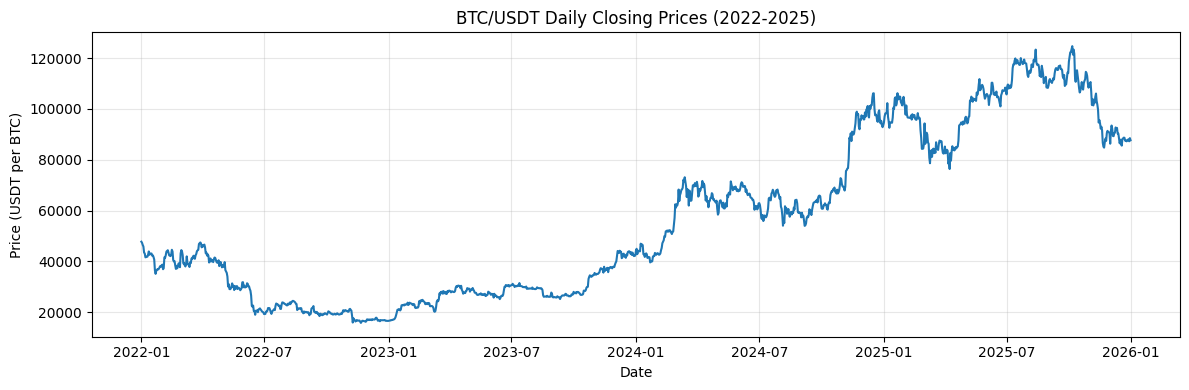

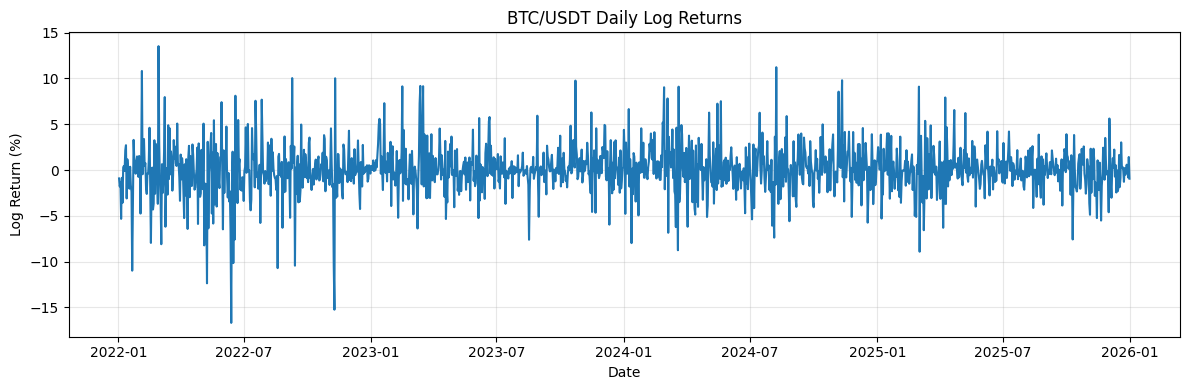

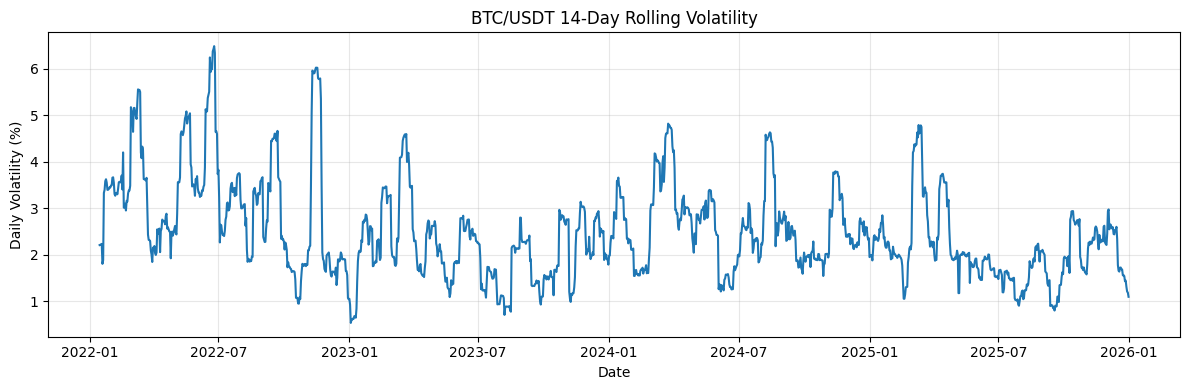

In [8]:

# Step 6: Historical data visualisation

import matplotlib.pyplot as plt

# Graph 1: Bitcoin closing prices
plt.figure(figsize=(12, 4))
plt.plot(price_df["date"], price_df["close"])
plt.title("BTC/USDT Daily Closing Prices (2022-2025)")
plt.xlabel("Date")
plt.ylabel("Price (USDT per BTC)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Daily log returns
plt.figure(figsize=(12, 4))
plt.plot(
    price_df["date"],
    price_df["log_return"] * 100
)
plt.title("BTC/USDT Daily Log Returns")
plt.xlabel("Date")
plt.ylabel("Log Return (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 3: Rolling volatility
plt.figure(figsize=(12, 4))
plt.plot(
    price_df["date"],
    price_df["rolling_vol_14d"] * 100
)
plt.title("BTC/USDT 14-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Daily Volatility (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 3.5 Calibration and Evaluation Dataset Split

The historical BTC/USDT dataset is divided chronologically into two periods:

- Calibration: 1 January 2022 to 31 December 2024.
- Evaluation: 1 January 2025 to 31 December 2025.

The calibration dataset is used to estimate the parameters of the GBM and Markov regime-switching models.

The evaluation dataset is reserved for assessing model performance on later observations.

This chronological split helps prevent future-information leakage. The evaluation data will not be used to estimate the model parameters or select the volatility-regime threshold.

In [9]:

# Step 7: Chronological dataset split

cutoff = pd.Timestamp("2025-01-01", tz="UTC")

calibration_df = price_df[
    price_df["date"] < cutoff
].copy()

evaluation_df = price_df[
    price_df["date"] >= cutoff
].copy()

# Verify the expected sizes
assert len(calibration_df) == 1096, \
    "Unexpected calibration period length"

assert len(evaluation_df) == 365, \
    "Unexpected evaluation period length"

# Estimate preliminary baseline parameters
cal_returns = calibration_df["log_return"].dropna()

mu_cal = cal_returns.mean()
sigma_cal = cal_returns.std(ddof=1)

assert np.isfinite(mu_cal)
assert np.isfinite(sigma_cal) and sigma_cal > 0

print("Calibration observations:", len(calibration_df))
print("Evaluation observations:", len(evaluation_df))

print(f"Mean daily log return: {mu_cal:.6f}")
print(f"Daily log-return volatility: {sigma_cal:.6f}")
print(f"Daily volatility (%): {sigma_cal * 100:.3f}%")

print("PASS: Chronological data split completed")


Calibration observations: 1096
Evaluation observations: 365
Mean daily log return: 0.000615
Daily log-return volatility: 0.028460
Daily volatility (%): 2.846%
PASS: Chronological data split completed



### 3.6 Geometric Brownian Motion (GBM) Baseline

Geometric Brownian Motion is used as the constant-volatility baseline for Bitcoin price simulation.

The model assumes daily log returns are independent and identically distributed according to a normal distribution:

$$
r_t \sim N(\mu_r,\sigma_r^2)
$$

The simulated daily price update is:

$$
P_{t+1}=P_t\exp(\mu_r+\sigma_r Z_t)
$$

where:

- $P_t$ is the simulated Bitcoin price on day $t$.
- $\mu_r$ is the estimated mean daily log return.
- $\sigma_r$ is the estimated daily log-return standard deviation.
- $Z_t$ is an independent standard-normal random variable.

The model parameters are estimated only from the 2022–2024 calibration dataset.

**Simulation settings**

- Investment horizon: 30 days.
- Number of simulated paths: 10,000.
- Random seed: 42.
- Initial BTC price: last calibration-period closing price.
- Investment value for subsequent risk calculations: 1,000 USDT.

The model generates alternative possible future price paths. These are scenarios, not guaranteed price forecasts.

GBM assumes constant volatility and independent normal log returns. These simplifications motivate the later comparison against a two-state Markov regime-switching model.

**Reference:** Columbia University lecture material, *Generating Random Variables and Stochastic Processes*:
https://www.columbia.edu/~mh2078/MonteCarlo/MCS_Generate_RVars.pdf


In [10]:

# Day 3: GBM Monte Carlo price simulation

HORIZON_DAYS = 30
N_PATHS = 10_000
GBM_SEED = 42

# Use the final price from the calibration period,
# not a price from the held-out evaluation dataset.
S0 = float(calibration_df["close"].iloc[-1])

def simulate_gbm_paths(
    initial_price,
    mean_log_return,
    daily_volatility,
    horizon_days,
    n_paths,
    seed=42
):
    """Simulate GBM price paths using daily log returns."""

    if initial_price <= 0:
        raise ValueError("Initial price must be positive")

    if daily_volatility < 0:
        raise ValueError("Volatility cannot be negative")

    if horizon_days < 1 or n_paths < 1:
        raise ValueError("Horizon and path count must be positive")

    # Create a reproducible random generator.
    rng = np.random.default_rng(seed)

    # Each row is one simulated 30-day scenario.
    shocks = rng.standard_normal(
        size=(n_paths, horizon_days)
    )

    # Generate normally distributed daily log returns.
    daily_log_returns = (
        mean_log_return + daily_volatility * shocks
    )

    # Add log returns across consecutive days.
    cumulative_log_returns = np.cumsum(
        daily_log_returns,
        axis=1
    )

    # Day 0 has a cumulative return of zero.
    cumulative_log_returns = np.column_stack([
        np.zeros(n_paths),
        cumulative_log_returns
    ])

    # Convert cumulative returns into price paths.
    paths = initial_price * np.exp(
        cumulative_log_returns
    )

    return paths


gbm_paths = simulate_gbm_paths(
    initial_price=S0,
    mean_log_return=mu_cal,
    daily_volatility=sigma_cal,
    horizon_days=HORIZON_DAYS,
    n_paths=N_PATHS,
    seed=GBM_SEED
)

# Basic structural verification
assert gbm_paths.shape == (10_000, 31)

np.testing.assert_allclose(
    gbm_paths[:, 0],
    S0
)

assert np.isfinite(gbm_paths).all()
assert (gbm_paths > 0).all()

print("Initial BTC price:", round(S0, 2), "USDT")
print("Simulation shape:", gbm_paths.shape)
print("Number of paths:", len(gbm_paths))
print("Days per path:", gbm_paths.shape[1] - 1)
print("PASS: GBM price paths have valid dimensions")
print("PASS: Initial prices and simulated prices are valid")


Initial BTC price: 93576.0 USDT
Simulation shape: (10000, 31)
Number of paths: 10000
Days per path: 30
PASS: GBM price paths have valid dimensions
PASS: Initial prices and simulated prices are valid


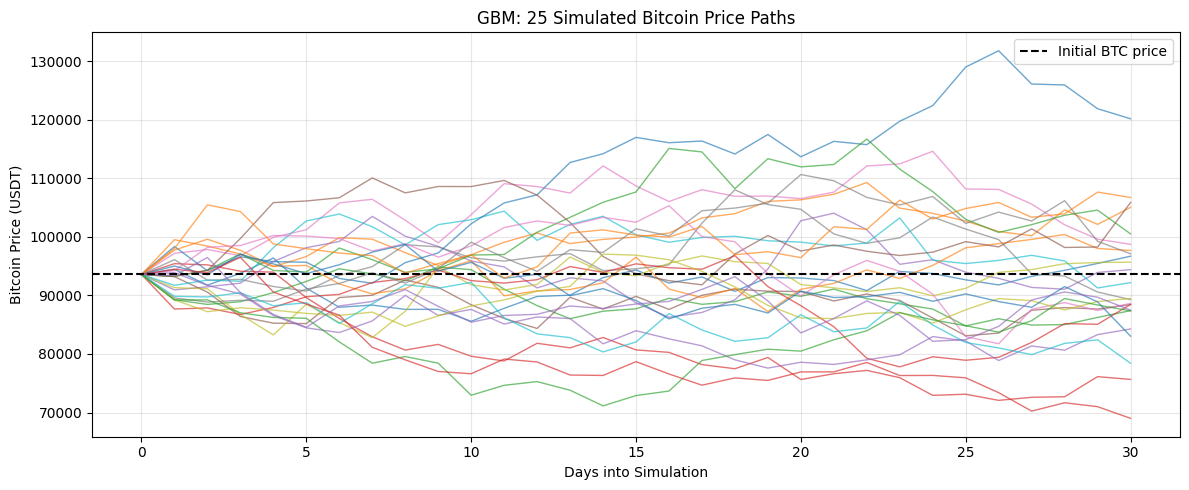

In [11]:

# Display the first 25 GBM scenarios.

plt.figure(figsize=(12, 5))

days = np.arange(HORIZON_DAYS + 1)

for i in range(25):
    plt.plot(
        days,
        gbm_paths[i],
        alpha=0.65,
        linewidth=1
    )

plt.axhline(
    S0,
    color="black",
    linestyle="--",
    label="Initial BTC price"
)

plt.title("GBM: 25 Simulated Bitcoin Price Paths")
plt.xlabel("Days into Simulation")
plt.ylabel("Bitcoin Price (USDT)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### 3.7 GBM Downside Risk Estimation

The simulated GBM price paths are used to estimate the downside risk of a hypothetical 1,000 USDT Bitcoin investment over 30 days.

The terminal investment value for simulated path $i$ is:

$$
V_T^{(i)} = V_0 \frac{P_T^{(i)}}{P_0}
$$

where:

- $V_0$ = initial investment (1,000 USDT).
- $P_0$ = initial Bitcoin price.
- $P_T^{(i)}$ = simulated terminal Bitcoin price.
- $V_T^{(i)}$ = terminal investment value.

The simulated monetary loss is:

$$
L^{(i)} = V_0 - V_T^{(i)}
$$

Positive values indicate losses, while negative values indicate gains.

#### Loss Probability

For a fractional loss threshold $\ell$:

$$
\hat p_\ell =
\frac{1}{N}
\sum_{i=1}^{N}
\mathbf{1}\left(L^{(i)} \geq \ell V_0\right)
$$

Loss thresholds of 10%, 20%, and 35% are evaluated.

#### Value at Risk (VaR)

The 95% Value at Risk is calculated as the empirical 95th percentile of simulated monetary losses:

$$
VaR_{0.95} = Q_{0.95}(L)
$$

#### Expected Shortfall (ES)

The 95% Expected Shortfall is estimated as the average loss in the worst 5% of simulation outcomes.

Both VaR and ES are reported in USDT.

These are model-based risk estimates, not guaranteed predictions of actual Bitcoin losses.


In [12]:

# Day 3: GBM downside-risk estimation

INITIAL_INVESTMENT = 1_000.0

# Final BTC price from each simulated 30-day scenario.
terminal_prices = gbm_paths[:, -1]

# Investment value after 30 days.
terminal_values = (
    INITIAL_INVESTMENT * terminal_prices / S0
)

# Positive = loss, negative = profit.
losses = INITIAL_INVESTMENT - terminal_values

# Loss probabilities
loss_thresholds = [0.10, 0.20, 0.35]

print("GBM - 30-Day Downside Risk")
print("-" * 40)

for threshold in loss_thresholds:
    event_count = np.count_nonzero(
        losses >= threshold * INITIAL_INVESTMENT
    )

    probability = event_count / N_PATHS

    print(
        f"Probability of losing at least "
        f"{threshold * 100:.0f}%: "
        f"{probability * 100:.3f}% "
        f"({event_count}/{N_PATHS} paths)"
    )

# Value at Risk: 95th percentile of losses
var_95 = np.quantile(losses, 0.95)

# Expected Shortfall: average loss beyond VaR
tail_losses = losses[losses >= var_95]
es_95 = tail_losses.mean()

print("-" * 40)
print(f"95% VaR: {var_95:.2f} USDT")
print(f"95% ES:  {es_95:.2f} USDT")

# Basic verification
assert np.isfinite(losses).all()
assert len(losses) == N_PATHS
assert es_95 >= var_95

print("PASS: Risk estimates are finite and ES >= VaR")


GBM - 30-Day Downside Risk
----------------------------------------
Probability of losing at least 10%: 21.290% (2129/10000 paths)
Probability of losing at least 20%: 5.860% (586/10000 paths)
Probability of losing at least 35%: 0.140% (14/10000 paths)
----------------------------------------
95% VaR: 209.63 USDT
95% ES:  256.15 USDT
PASS: Risk estimates are finite and ES >= VaR



### 3.8 Two-State Volatility Regime Classification

The constant-volatility GBM baseline assumes that daily log returns follow one distribution throughout the simulation.

To represent changing market conditions, a two-state observed-regime Markov model is introduced.

The states are:

- State 0: Calm (relatively low volatility).
- State 1: Volatile (relatively high volatility).

#### Regime Classification

Market states are identified using the trailing 14-day sample standard deviation of daily log returns, calculated in Section 3.3.

The classification threshold is the median rolling volatility of the 2022–2024 calibration observations.

$$
c = \operatorname{median}(v_t \mid t \in \text{calibration period})
$$

The state for a historical day is defined as:

$$
S_t =
\begin{cases}
0, & v_t < c\\
1, & v_t \geq c
\end{cases}
$$

where $v_t$ is the trailing 14-day volatility.

The first observations without a complete 14-day rolling window are excluded from regime estimation.

**Avoiding future-data leakage:**

- The threshold is estimated exclusively from the 2022–2024 calibration period.
- No 2025 observations are used to estimate the regime threshold.
- Rolling volatility at day $t$ uses returns observed through that day, not future returns.
- The state assigned at the end of day $t$ can be used to condition the following day's return.

This is a transparent, rule-based observed-regime classification rather than a fitted hidden Markov model.

The suitability of the median threshold and the assumption of first-order Markov transitions will be considered as model limitations.


In [13]:

# Day 4 - Step 1: Classify historical volatility regimes

# Use calibration observations only (2022-2024).
# The rolling_vol_14d column already exists from Day 2.

regime_calibration_df = calibration_df[
    ["date", "close", "log_return", "rolling_vol_14d"]
].dropna(subset=["rolling_vol_14d"]).copy()

regime_calibration_df = (
    regime_calibration_df.reset_index(drop=True)
)

# Fit the classification threshold ONLY on calibration data.
regime_threshold = float(
    regime_calibration_df["rolling_vol_14d"].median()
)

# State 0 = calm; State 1 = volatile
regime_calibration_df["regime"] = (
    regime_calibration_df["rolling_vol_14d"] >= regime_threshold
).astype(int)

regime_names = {
    0: "Calm",
    1: "Volatile"
}

regime_calibration_df["regime_name"] = (
    regime_calibration_df["regime"].map(regime_names)
)

# Count how many historical observations belong to each state.
regime_counts = (
    regime_calibration_df["regime"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

print("Two-State Volatility Classification")
print("-" * 45)
print(f"Rolling window: {WINDOW} days")
print(f"Threshold (decimal): {regime_threshold:.6f}")
print(f"Threshold (%): {regime_threshold * 100:.3f}%")
print()
print(f"Calm days: {regime_counts[0]}")
print(f"Volatile days: {regime_counts[1]}")
print(f"Total classified days: {len(regime_calibration_df)}")

# Verification checks
assert len(regime_calibration_df) == (
    len(calibration_df) - WINDOW
)

assert (
    regime_calibration_df["date"].max() < cutoff
)

assert np.isfinite(regime_threshold)
assert regime_threshold > 0

assert set(
    regime_calibration_df["regime"].unique()
) == {0, 1}

assert (
    regime_calibration_df["rolling_vol_14d"].notna().all()
)

print()
print("PASS: Regime threshold uses calibration data only")
print("PASS: All classified observations have valid volatility")
print("PASS: Both market regimes are represented")

display(
    regime_calibration_df[
        ["date", "close", "rolling_vol_14d",
         "regime", "regime_name"]
    ].head(10)
)


Two-State Volatility Classification
---------------------------------------------
Rolling window: 14 days
Threshold (decimal): 0.024455
Threshold (%): 2.446%

Calm days: 541
Volatile days: 541
Total classified days: 1082

PASS: Regime threshold uses calibration data only
PASS: All classified observations have valid volatility
PASS: Both market regimes are represented


,date,close,rolling_vol_14d,regime,regime_name
0,2022-01-15 00:00:00+00:00,43084.29,0.022120,0,Calm
1,2022-01-16 00:00:00+00:00,43071.66,0.022189,0,Calm
2,2022-01-17 00:00:00+00:00,42201.62,0.022296,0,Calm
3,2022-01-18 00:00:00+00:00,42352.12,0.022375,0,Calm
4,2022-01-19 00:00:00+00:00,41660.01,0.018087,0,Calm
5,2022-01-20 00:00:00+00:00,40680.91,0.018887,0,Calm
6,2022-01-21 00:00:00+00:00,36445.31,0.033332,1,Volatile
7,2022-01-22 00:00:00+00:00,35071.42,0.033989,1,Volatile
8,2022-01-23 00:00:00+00:00,36244.55,0.035869,1,Volatile
9,2022-01-24 00:00:00+00:00,36660.35,0.036267,1,Volatile



### 3.9 Markov Transition Matrix Estimation

The daily volatility regimes classified in Section 3.8 are used to estimate a first-order, two-state Markov transition matrix.

The states are:

- State 0: Calm market.
- State 1: Volatile market.

The transition probability from state $i$ to state $j$ is:

$$
P_{ij} = P(S_{t+1}=j \mid S_t=i)
$$

The empirical maximum-likelihood estimator is:

$$
\hat{P}_{ij} = \frac{N_{ij}}{\sum_{k=0}^{1}N_{ik}}
$$

where $N_{ij}$ is the number of observed transitions from state $i$ to state $j$.

The resulting transition matrix is:

$$
P =
\begin{bmatrix}
P_{00} & P_{01}\\
P_{10} & P_{11}
\end{bmatrix}
$$

Every transition probability must be between 0 and 1, and each row must sum to 1.

The diagonal probabilities $P_{00}$ and $P_{11}$ describe regime persistence.

Under the first-order Markov assumption, the expected duration of a regime is:

$$
E[D_i] = \frac{1}{1-P_{ii}}
$$

provided $P_{ii}<1$.

All transition probabilities are estimated exclusively from consecutive observations within the 2022–2024 calibration period.

The model assumes transitions depend only on the current regime. This is a simplifying assumption that will be discussed as a limitation.


In [14]:

# Day 4 - Step 2: Estimate the Markov transition matrix

# Extract historical regimes in chronological order.
states = regime_calibration_df["regime"].to_numpy()

# Verify consecutive daily observations.
date_gaps = regime_calibration_df["date"].diff().dropna()

assert (
    date_gaps == pd.Timedelta(days=1)
).all(), "Regime observations must be consecutive daily records"

# Set up a 2x2 transition-count matrix.
transition_counts = np.zeros((2, 2), dtype=int)

# Count transitions between consecutive observations.
# Each pair represents current state -> next state.
np.add.at(
    transition_counts,
    (states[:-1], states[1:]),
    1
)

# Total transitions starting from each state.
row_totals = transition_counts.sum(axis=1)

assert np.all(row_totals > 0)

# Convert transition counts to probabilities.
transition_matrix = (
    transition_counts / row_totals[:, np.newaxis]
)

# Display counts and probabilities.
labels = ["Calm (0)", "Volatile (1)"]

print("Markov Transition Counts")
display(
    pd.DataFrame(
        transition_counts,
        index=labels,
        columns=labels
    )
)

print("\nMarkov Transition Probability Matrix")
display(
    pd.DataFrame(
        transition_matrix,
        index=labels,
        columns=labels
    ).round(6)
)

# Calculate persistence probabilities.
p_calm_stay = transition_matrix[0, 0]
p_volatile_stay = transition_matrix[1, 1]

print("\nRegime Persistence")
print(f"Calm -> Calm: {p_calm_stay:.4%}")
print(f"Volatile -> Volatile: {p_volatile_stay:.4%}")

# Expected regime durations
if p_calm_stay < 1:
    print(
        f"Expected calm duration: "
        f"{1 / (1 - p_calm_stay):.2f} days"
    )

if p_volatile_stay < 1:
    print(
        f"Expected volatile duration: "
        f"{1 / (1 - p_volatile_stay):.2f} days"
    )

# Verification checks
assert transition_counts.sum() == len(states) - 1

assert transition_matrix.shape == (2, 2)

np.testing.assert_allclose(
    transition_matrix.sum(axis=1),
    np.ones(2),
    atol=1e-12
)

assert np.all(transition_matrix >= 0)
assert np.all(transition_matrix <= 1)

print("\nPASS: Transition counts match consecutive observations")
print("PASS: Transition probabilities are valid")
print("PASS: Each transition-matrix row sums to 1")


Markov Transition Counts


,Calm (0),Volatile (1)
Calm (0),499,41
Volatile (1),41,500



Markov Transition Probability Matrix


,Calm (0),Volatile (1)
Calm (0),0.924074,0.075926
Volatile (1),0.075786,0.924214



Regime Persistence
Calm -> Calm: 92.4074%
Volatile -> Volatile: 92.4214%
Expected calm duration: 13.17 days
Expected volatile duration: 13.20 days

PASS: Transition counts match consecutive observations
PASS: Transition probabilities are valid
PASS: Each transition-matrix row sums to 1



### 3.10 Estimation of Regime-Specific Return Parameters

The two-state Markov model allows the distribution of daily Bitcoin log returns to depend on the market regime observed at the previous day's close.

For a regime $S_t=i$:

$$
r_{t+1}\mid S_t=i \sim N(\mu_i,\sigma_i^2)
$$

where:

- $\mu_0$: Mean next-day log return following a calm day.
- $\sigma_0$: Standard deviation of next-day log returns following a calm day.
- $\mu_1$: Mean next-day log return following a volatile day.
- $\sigma_1$: Standard deviation of next-day log returns following a volatile day.

Historical returns are aligned with the preceding day's regime classification.

This timing is important because the 14-day rolling volatility used to classify day $t$ includes observations through day $t$.

Only the 2022–2024 calibration observations are used for parameter estimation.

The regime-specific means and sample standard deviations are estimated from the next-day returns associated with each observed regime.

Both regimes are modelled using normal conditional return distributions. This assumption may not fully capture heavy tails, skewness, or other features of Bitcoin returns and will be discussed as a limitation.


In [15]:

# Day 4 - Step 3: Estimate regime-specific return parameters

# Use the classified calibration dataset from Section 3.8.
regime_return_df = regime_calibration_df[
    ["date", "regime", "log_return"]
].copy()

# Align each current state with the NEXT day's return.
regime_return_df["next_log_return"] = (
    regime_return_df["log_return"].shift(-1)
)

regime_return_df["next_date"] = (
    regime_return_df["date"].shift(-1)
)

# The final calibration day has no next-day return
# within the calibration dataset, so remove it.
regime_return_df = (
    regime_return_df
    .dropna(subset=["next_log_return", "next_date"])
    .copy()
)

# Confirm that each return follows its conditioning state
# by exactly one calendar day.
assert (
    regime_return_df["next_date"]
    - regime_return_df["date"]
    == pd.Timedelta(days=1)
).all()

# Estimate the next-day return distribution
# conditional on the current regime.
regime_stats = (
    regime_return_df
    .groupby("regime")["next_log_return"]
    .agg(["count", "mean", "std"])
    .reindex([0, 1])
)

regime_stats.columns = ["n", "mu", "sigma"]

# Store the parameters in arrays indexed by state.
regime_mu = regime_stats["mu"].to_numpy()
regime_sigma = regime_stats["sigma"].to_numpy()

regime_sample_counts = (
    regime_stats["n"].to_numpy(dtype=int)
)

print("Regime-Specific Next-Day Return Parameters")
print("-" * 55)

for state in [0, 1]:
    print(f"\nState {state}: {regime_names[state]}")
    print(f"Sample size: {regime_sample_counts[state]}")
    print(f"Mean daily log return: {regime_mu[state]:.6f}")
    print(f"Daily volatility: {regime_sigma[state]:.6f}")
    print(f"Daily volatility (%): {regime_sigma[state]*100:.3f}%")

print("\nGBM baseline parameters for reference:")
print(f"GBM mean: {mu_cal:.6f}")
print(f"GBM volatility: {sigma_cal:.6f}")

# Verification checks
assert len(regime_return_df) == 1081

np.testing.assert_array_equal(
    regime_sample_counts,
    transition_counts.sum(axis=1)
)

assert np.isfinite(regime_mu).all()
assert np.isfinite(regime_sigma).all()

assert (regime_sigma > 0).all()

assert (
    regime_return_df["next_date"].max() < cutoff
)

print("\nPASS: Next-day returns aligned with current states")
print("PASS: Regime sample counts match transition row totals")
print("PASS: Parameters use calibration data only")
print("PASS: Regime means and volatilities are valid")

display(regime_stats.round(6))


Regime-Specific Next-Day Return Parameters
-------------------------------------------------------

State 0: Calm
Sample size: 540
Mean daily log return: 0.001171
Daily volatility: 0.024537
Daily volatility (%): 2.454%

State 1: Volatile
Sample size: 541
Mean daily log return: 0.000265
Daily volatility: 0.032033
Daily volatility (%): 3.203%

GBM baseline parameters for reference:
GBM mean: 0.000615
GBM volatility: 0.028460

PASS: Next-day returns aligned with current states
PASS: Regime sample counts match transition row totals
PASS: Parameters use calibration data only
PASS: Regime means and volatilities are valid


,n,mu,sigma
regime,,,
0,540,0.001171,0.024537
1,541,0.000265,0.032033



### 3.11 Two-State Markov Monte Carlo Simulation

A two-state observed-regime Markov model is implemented to simulate Bitcoin price movements over a 30-day horizon.

The model uses the transition matrix and regime-specific parameters estimated from the 2022–2024 calibration data.

The daily log return depends on the regime known at the beginning of the simulated day:

$$
r_{t+1}=\mu_{S_t}+\sigma_{S_t}Z_{t+1}
$$

where:

- $S_t$ is the current regime (0 = calm, 1 = volatile).
- $\mu_{S_t}$ is the conditional mean daily log return.
- $\sigma_{S_t}$ is the conditional daily return standard deviation.
- $Z_{t+1}$ is an independent standard-normal random variable.

The simulated Bitcoin price is updated using:

$$
P_{t+1}=P_t\exp(r_{t+1})
$$

The following day's regime is sampled from the transition matrix:

$$
P(S_{t+1}=j\mid S_t=i)=P_{ij}
$$

The model begins in the last observed calibration-period regime, corresponding to 31 December 2024.

**Simulation settings:**

- Horizon: 30 days.
- Paths: 10,000.
- Initial Bitcoin price: 93,576 USDT.
- Initial regime: Last classified calibration observation.
- Random seed: 42.

Each simulated day updates the price according to the current regime and then samples the next regime.

The model assumes that the return shock and subsequent state transition are conditionally independent given the current regime. This is an approximation because historical rolling-volatility classifications depend on overlapping return observations.

All fitted parameters come from the calibration period. No 2025 observations are used in estimation.


In [16]:

# Day 4 - Step 4: Markov regime-switching Monte Carlo simulation

MARKOV_SEED = 42

# Start from the final observed calibration regime.
initial_regime = int(
    regime_calibration_df["regime"].iloc[-1]
)

initial_regime_date = regime_calibration_df["date"].iloc[-1]

assert initial_regime_date == pd.Timestamp(
    "2024-12-31", tz="UTC"
)


def simulate_markov_paths(
    initial_price,
    initial_state,
    transition_probs,
    regime_means,
    regime_volatilities,
    horizon_days,
    n_paths,
    seed=42
):
    """Simulate price paths with two Markov volatility regimes."""

    if initial_price <= 0:
        raise ValueError("Initial price must be positive")

    if initial_state not in (0, 1):
        raise ValueError("Initial state must be 0 or 1")

    if horizon_days < 1 or n_paths < 1:
        raise ValueError("Horizon and path count must be positive")

    transition_probs = np.asarray(
        transition_probs, dtype=float
    )

    regime_means = np.asarray(
        regime_means, dtype=float
    )

    regime_volatilities = np.asarray(
        regime_volatilities, dtype=float
    )

    if transition_probs.shape != (2, 2):
        raise ValueError("Expected a 2x2 transition matrix")

    if regime_means.shape != (2,):
        raise ValueError("Expected two regime means")

    if regime_volatilities.shape != (2,):
        raise ValueError("Expected two regime volatilities")

    if not np.isfinite(transition_probs).all():
        raise ValueError("Transition probabilities must be finite")

    if np.any((transition_probs < 0) | (transition_probs > 1)):
        raise ValueError("Invalid transition probabilities")

    if not np.allclose(transition_probs.sum(axis=1), 1):
        raise ValueError("Each transition row must sum to 1")

    if not np.isfinite(regime_means).all():
        raise ValueError("Regime means must be finite")

    if not np.isfinite(regime_volatilities).all():
        raise ValueError("Regime volatilities must be finite")

    if np.any(regime_volatilities < 0):
        raise ValueError("Regime volatilities cannot be negative")

    # Independent random-number generator.
    rng = np.random.default_rng(seed)

    # Store Day 0 and all simulated future days.
    price_paths = np.empty(
        (n_paths, horizon_days + 1),
        dtype=float
    )

    state_paths = np.empty(
        (n_paths, horizon_days + 1),
        dtype=np.int8
    )

    price_paths[:, 0] = initial_price
    state_paths[:, 0] = initial_state

    for day in range(horizon_days):

        # Current state for every simulated path.
        current_states = state_paths[:, day]

        # Select parameters for the current regimes.
        daily_mu = regime_means[current_states]
        daily_sigma = regime_volatilities[current_states]

        # Independent random return shocks.
        shocks = rng.standard_normal(n_paths)

        daily_returns = daily_mu + daily_sigma * shocks

        # Generate tomorrow's Bitcoin prices.
        price_paths[:, day + 1] = (
            price_paths[:, day] * np.exp(daily_returns)
        )

        # Draw the next state using the transition matrix.
        random_uniforms = rng.random(n_paths)

        probability_next_calm = (
            transition_probs[current_states, 0]
        )

        # 0 if the uniform draw selects calm; otherwise 1.
        state_paths[:, day + 1] = (
            random_uniforms >= probability_next_calm
        ).astype(np.int8)

    return price_paths, state_paths


# Run the Markov simulation.
markov_paths, markov_states = simulate_markov_paths(
    initial_price=S0,
    initial_state=initial_regime,
    transition_probs=transition_matrix,
    regime_means=regime_mu,
    regime_volatilities=regime_sigma,
    horizon_days=HORIZON_DAYS,
    n_paths=N_PATHS,
    seed=MARKOV_SEED
)

print("Markov Monte Carlo Simulation")
print("-" * 50)

print("Initial BTC price:", round(S0, 2), "USDT")
print("Initial regime:", regime_names[initial_regime])
print("Initial regime date:", initial_regime_date)

print("Price-path shape:", markov_paths.shape)
print("State-path shape:", markov_states.shape)

print("Number of paths:", N_PATHS)
print("Simulation horizon:", HORIZON_DAYS, "days")

# Basic structural verification.
assert markov_paths.shape == (
    N_PATHS, HORIZON_DAYS + 1
)

assert markov_states.shape == (
    N_PATHS, HORIZON_DAYS + 1
)

np.testing.assert_allclose(
    markov_paths[:, 0],
    S0
)

assert np.all(
    markov_states[:, 0] == initial_regime
)

assert np.isfinite(markov_paths).all()
assert np.all(markov_paths > 0)

assert np.isin(markov_states, [0, 1]).all()

print("\nPASS: Markov price paths have valid dimensions")
print("PASS: Simulated prices are positive and finite")
print("PASS: All simulated states are valid")
print("PASS: Initial price and regime are consistent")

# Inspect how many paths finish in each regime.
terminal_state_counts = np.bincount(
    markov_states[:, -1],
    minlength=2
)

print("\nFinal simulated regime counts:")
print("Calm:", terminal_state_counts[0])
print("Volatile:", terminal_state_counts[1])


Markov Monte Carlo Simulation
--------------------------------------------------
Initial BTC price: 93576.0 USDT
Initial regime: Calm
Initial regime date: 2024-12-31 00:00:00+00:00
Price-path shape: (10000, 31)
State-path shape: (10000, 31)
Number of paths: 10000
Simulation horizon: 30 days

PASS: Markov price paths have valid dimensions
PASS: Simulated prices are positive and finite
PASS: All simulated states are valid
PASS: Initial price and regime are consistent

Final simulated regime counts:
Calm: 4988
Volatile: 5012



### 3.12 Markov Model Downside Risk Estimation

The simulated terminal prices from the two-state Markov model are converted into investment values and monetary losses.

For an initial investment $V_0 = 1000$ USDT:

$$
V_T^{(i)} = V_0\frac{P_T^{(i)}}{P_0}
$$

$$
L^{(i)} = V_0 - V_T^{(i)}
$$

Positive values indicate monetary losses, while negative values indicate gains.

The following risk measures are estimated from 10,000 simulated 30-day paths:

1. Probability of losing at least 10%.
2. Probability of losing at least 20%.
3. Probability of losing at least 35%.
4. 95% Value at Risk (VaR).
5. 95% Expected Shortfall (ES).

The calculations use the same investment amount, time horizon, loss thresholds, and quantile definitions as the GBM baseline.

Monte Carlo sampling uncertainty in the estimated loss probabilities is quantified using 95% Wilson confidence intervals.

These results describe downside risk under the fitted Markov model. They do not establish that the model predicts actual Bitcoin market losses accurately.

A formal comparison against GBM and out-of-sample evaluation will be performed in later experiments.


In [17]:

# Day 4 - Step 5: Markov downside-risk estimation

# Reuse the initial investment from our GBM model.
# INITIAL_INVESTMENT = 1000.0

# Final prices after 30 simulated days.
markov_terminal_prices = markov_paths[:, -1]

# Convert simulated BTC prices into investment values.
markov_terminal_values = (
    INITIAL_INVESTMENT
    * markov_terminal_prices
    / S0
)

# Positive values represent monetary losses.
markov_losses = (
    INITIAL_INVESTMENT - markov_terminal_values
)

print("Markov - 30-Day Downside Risk")
print("-" * 50)

# Loss probabilities
markov_loss_probabilities = {}

for threshold in [0.10, 0.20, 0.35]:

    event_count = int(np.count_nonzero(
        markov_losses >= threshold * INITIAL_INVESTMENT
    ))

    probability = event_count / N_PATHS

    markov_loss_probabilities[threshold] = probability

    print(
        f"Probability of losing at least "
        f"{threshold * 100:.0f}%: "
        f"{probability * 100:.3f}% "
        f"({event_count}/{N_PATHS} paths)"
    )

# 95% Value at Risk
markov_var_95 = np.quantile(
    markov_losses, 0.95
)

# 95% Expected Shortfall
markov_tail_losses = markov_losses[
    markov_losses >= markov_var_95
]

markov_es_95 = markov_tail_losses.mean()

print("-" * 50)
print(f"95% VaR: {markov_var_95:.2f} USDT")
print(f"95% ES:  {markov_es_95:.2f} USDT")

# Basic verification checks
assert len(markov_losses) == N_PATHS

assert np.isfinite(markov_losses).all()

assert markov_es_95 >= markov_var_95

assert all(
    0 <= p <= 1
    for p in markov_loss_probabilities.values()
)

print("\nPASS: Markov loss probabilities are valid")
print("PASS: Markov VaR and ES are finite")
print("PASS: Expected Shortfall is at least VaR")


Markov - 30-Day Downside Risk
--------------------------------------------------
Probability of losing at least 10%: 19.210% (1921/10000 paths)
Probability of losing at least 20%: 5.190% (519/10000 paths)
Probability of losing at least 35%: 0.090% (9/10000 paths)
--------------------------------------------------
95% VaR: 202.79 USDT
95% ES:  250.67 USDT

PASS: Markov loss probabilities are valid
PASS: Markov VaR and ES are finite
PASS: Expected Shortfall is at least VaR



### 3.13 Markov Regime-Switching Visualisation

Three visualisations are produced to examine the observed-regime classification and the behaviour of the Markov Monte Carlo simulation.

1. **Historical regime classification:** Displays the 14-day rolling volatility of Bitcoin and the corresponding calm and volatile states during the 2022–2024 calibration period.
2. **Simulated price paths:** Displays 25 of the 10,000 simulated 30-day Bitcoin price scenarios.
3. **Simulated regime paths:** Displays the daily calm and volatile states for 20 simulated scenarios.

The historical regime chart uses calibration observations only.

The simulated charts illustrate stochastic model behaviour rather than actual future Bitcoin prices.


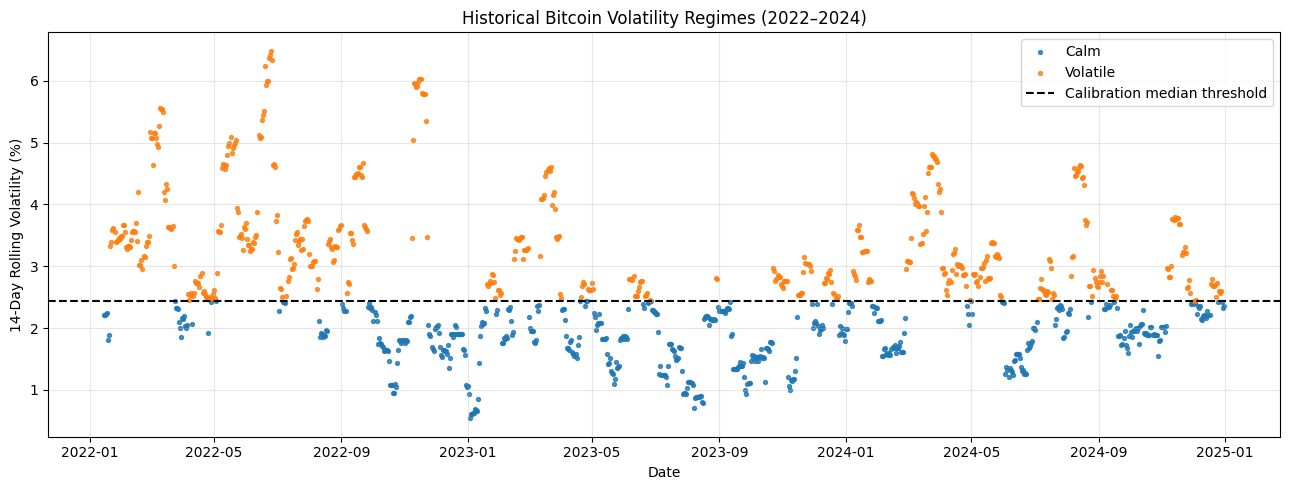

In [18]:

# Day 4 - Step 7A: Historical volatility regimes

plt.figure(figsize=(13, 5))

for state, color in [(0, "tab:blue"), (1, "tab:orange")]:

    subset = regime_calibration_df[
        regime_calibration_df["regime"] == state
    ]

    plt.scatter(
        subset["date"],
        subset["rolling_vol_14d"] * 100,
        s=8,
        color=color,
        label=regime_names[state],
        alpha=0.8
    )

plt.axhline(
    regime_threshold * 100,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Calibration median threshold"
)

plt.title(
    "Historical Bitcoin Volatility Regimes (2022–2024)"
)
plt.xlabel("Date")
plt.ylabel("14-Day Rolling Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


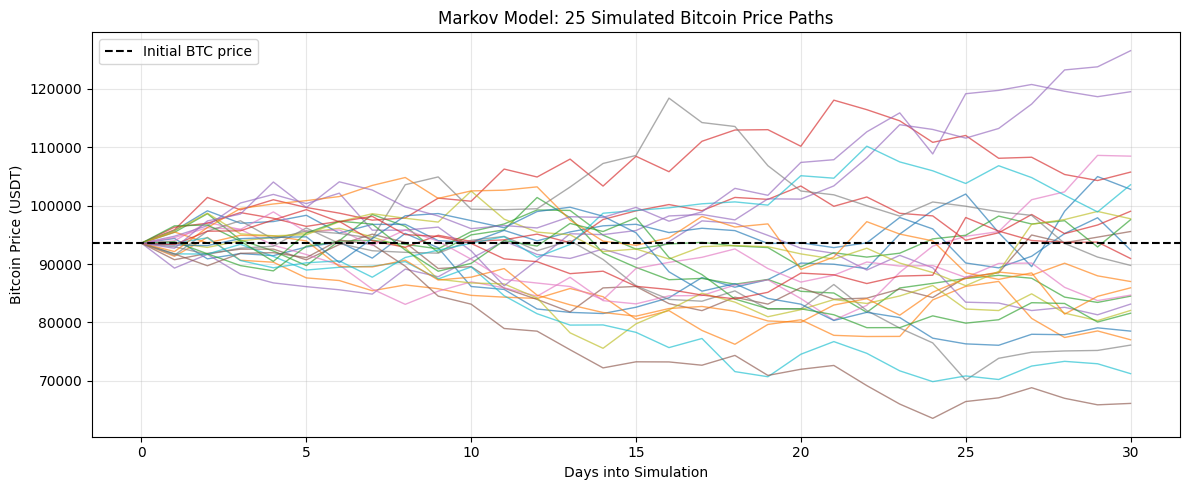

In [19]:

# Day 4 - Step 7B: Markov simulated BTC price paths

plt.figure(figsize=(12, 5))

days = np.arange(HORIZON_DAYS + 1)

for i in range(25):

    plt.plot(
        days,
        markov_paths[i],
        alpha=0.65,
        linewidth=1
    )

plt.axhline(
    S0,
    color="black",
    linestyle="--",
    label="Initial BTC price"
)

plt.title("Markov Model: 25 Simulated Bitcoin Price Paths")
plt.xlabel("Days into Simulation")
plt.ylabel("Bitcoin Price (USDT)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


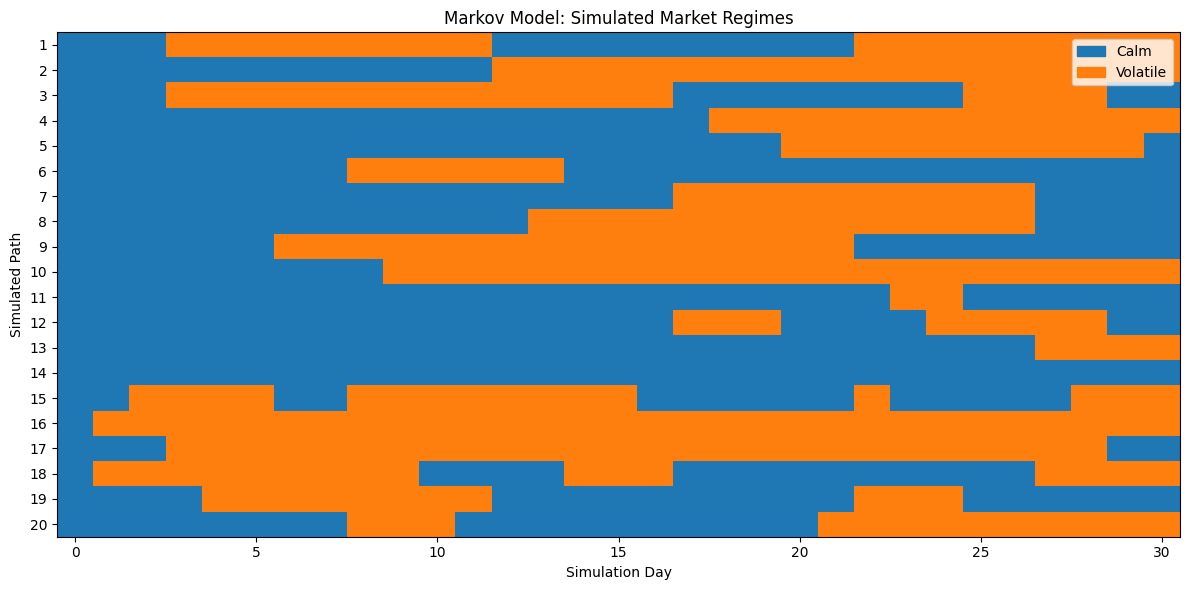

In [20]:

# Day 4 - Step 7C: Visualise simulated market regimes

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# First 20 simulated paths across Day 0 to Day 30.
sample_states = markov_states[:20]

regime_cmap = ListedColormap([
    "tab:blue",
    "tab:orange"
])

plt.figure(figsize=(12, 6))

plt.imshow(
    sample_states,
    cmap=regime_cmap,
    vmin=0,
    vmax=1,
    aspect="auto",
    interpolation="nearest"
)

plt.title("Markov Model: Simulated Market Regimes")
plt.xlabel("Simulation Day")
plt.ylabel("Simulated Path")

plt.xticks(np.arange(0, 31, 5))
plt.yticks(
    np.arange(20),
    np.arange(1, 21)
)

plt.legend(
    handles=[
        Patch(color="tab:blue", label="Calm"),
        Patch(color="tab:orange", label="Volatile")
    ],
    loc="upper right"
)

plt.tight_layout()
plt.show()


## 4. Verification

**Foundational checks below verify only the foundational computations.** They must not be presented as verification of the final Bitcoin simulation. Future independent checks will include:

1. GBM Monte Carlo loss probability versus its analytic lognormal formula.
2. A limiting case: identical return distributions in both regimes should match the single-distribution benchmark within Monte Carlo error.
3. Row-sum and range checks for the real transition matrix.
4. Error-scaling study: estimate how Monte Carlo error decreases as simulation count grows, with a log–log plot.
5. A browser-versus-notebook reference test with a stated tolerance.

In [21]:
# Verification of the *foundational* calculations (fictional data only).
np.testing.assert_allclose(np.exp(toy_log), 1.0 + toy_simple, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(toy_log.sum(), np.log(toy_prices[-1] / toy_prices[0]), rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(toy_transition_matrix.sum(axis=1), np.ones(2), atol=1e-12)
assert np.all((toy_transition_matrix >= 0) & (toy_transition_matrix <= 1))

print("PASS: log returns and simple returns are mathematically consistent")
print("PASS: log returns add across the complete price interval")
print("PASS: illustrative Markov transition probabilities are valid")
print("NOTE: full GBM and regime-simulation verification has not yet been performed")

PASS: log returns and simple returns are mathematically consistent
PASS: log returns add across the complete price interval
PASS: illustrative Markov transition probabilities are valid
NOTE: full GBM and regime-simulation verification has not yet been performed



### 4.1 Independent Analytical Verification of the GBM Model

The Monte Carlo implementation is checked against analytical results from the lognormal GBM model.

Under the assumption that daily log returns are independent and normally distributed, the cumulative log return after $T$ days is:

$$
Y_T = \ln(P_T/P_0) \sim N(m,s^2)
$$

where:

$$
m = T\mu_r, \qquad s = \sqrt{T}\sigma_r
$$

#### Analytical Loss Probability

For a fractional loss threshold $\ell$:

$$
p_\ell =
\Phi\left(
\frac{\ln(1-\ell)-m}{s}
\right)
$$

Here, $\Phi$ is the standard normal cumulative distribution function.

#### Analytical 95% Value at Risk

For an initial investment $V_0$:

$$
VaR_{0.95}
=
V_0\left[1-\exp(m+s\Phi^{-1}(0.05))\right]
$$

#### Analytical 95% Expected Shortfall

For the continuous GBM loss distribution:

$$
ES_{0.95}
=
V_0\left[
1-
\frac{\exp(m+s^2/2)\Phi(z_{0.05}-s)}{0.05}
\right]
$$

where $z_{0.05}=\Phi^{-1}(0.05)$.

The analytical probabilities are compared with Monte Carlo estimates using their binomial sampling standard errors.

Bootstrap resampling is also used to estimate the finite-simulation uncertainty of VaR and ES.

These tests verify agreement with the mathematical GBM model. They do not establish that GBM is an accurate representation of real Bitcoin market behaviour.


In [22]:

# Step 6: Independent GBM analytical verification

from scipy.stats import norm

T = HORIZON_DAYS
N = len(losses)
V0 = INITIAL_INVESTMENT

# Exact distribution parameters of the T-day log return
m = mu_cal * T
s = sigma_cal * np.sqrt(T)

assert s > 0

print("GBM: Monte Carlo vs Analytical Results")
print("-" * 65)

# 1. Analytical loss probabilities
for threshold in [0.10, 0.20, 0.35]:

    analytic_p = norm.cdf(
        (np.log1p(-threshold) - m) / s
    )

    simulated_p = np.mean(
        losses >= threshold * V0
    )

    # Sampling standard error under the analytical model
    se = np.sqrt(analytic_p * (1 - analytic_p) / N)

    difference = abs(simulated_p - analytic_p)

    print(f"\nLoss threshold: {threshold:.0%}")
    print(f"Monte Carlo: {simulated_p:.4%}")
    print(f"Analytical:  {analytic_p:.4%}")
    print(f"Difference:  {difference:.4%}")
    print(f"Standard errors apart: {difference/se:.2f}")

    # Three-standard-error consistency check
    assert difference <= 3 * se, (
        f"GBM probability check failed at {threshold:.0%}"
    )

# 2. Analytical VaR and ES
alpha = 0.95
tail_probability = 1 - alpha

z_tail = norm.ppf(tail_probability)

analytic_var = V0 * (
    1 - np.exp(m + s * z_tail)
)

analytic_es = V0 * (
    1
    - np.exp(m + 0.5 * s**2)
    * norm.cdf(z_tail - s)
    / tail_probability
)

print("\n" + "-" * 65)
print("95% VaR comparison")
print(f"Monte Carlo: {var_95:.2f} USDT")
print(f"Analytical:  {analytic_var:.2f} USDT")

print("\n95% ES comparison")
print(f"Monte Carlo: {es_95:.2f} USDT")
print(f"Analytical:  {analytic_es:.2f} USDT")

# 3. Bootstrap uncertainty for Monte Carlo VaR and ES
B = 600
bootstrap_rng = np.random.default_rng(2026)

bootstrap_var = np.empty(B)
bootstrap_es = np.empty(B)

for b in range(B):

    sample = bootstrap_rng.choice(
        losses,
        size=N,
        replace=True
    )

    q = np.quantile(sample, alpha)

    bootstrap_var[b] = q
    bootstrap_es[b] = sample[sample >= q].mean()

# Conservative 99% bootstrap intervals for consistency checks
var_interval = np.quantile(
    bootstrap_var, [0.005, 0.995]
)

es_interval = np.quantile(
    bootstrap_es, [0.005, 0.995]
)

print("\n99% bootstrap intervals:")
print(f"VaR: [{var_interval[0]:.2f}, "
      f"{var_interval[1]:.2f}] USDT")
print(f"ES:  [{es_interval[0]:.2f}, "
      f"{es_interval[1]:.2f}] USDT")

assert var_interval[0] <= analytic_var <= var_interval[1], (
    "Analytical VaR outside bootstrap interval"
)

assert es_interval[0] <= analytic_es <= es_interval[1], (
    "Analytical ES outside bootstrap interval"
)

print("\nPASS: Analytical loss probabilities agree "
      "within three standard errors")
print("PASS: Analytical VaR and ES fall within "
      "the Monte Carlo bootstrap intervals")


GBM: Monte Carlo vs Analytical Results
-----------------------------------------------------------------

Loss threshold: 10%
Monte Carlo: 21.2900%
Analytical:  21.3525%
Difference:  0.0625%
Standard errors apart: 0.15

Loss threshold: 20%
Monte Carlo: 5.8600%
Analytical:  6.0589%
Difference:  0.1989%
Standard errors apart: 0.83

Loss threshold: 35%
Monte Carlo: 0.1400%
Analytical:  0.1977%
Difference:  0.0577%
Standard errors apart: 1.30

-----------------------------------------------------------------
95% VaR comparison
Monte Carlo: 209.63 USDT
Analytical:  211.76 USDT

95% ES comparison
Monte Carlo: 256.15 USDT
Analytical:  260.26 USDT

99% bootstrap intervals:
VaR: [203.09, 216.20] USDT
ES:  [248.91, 262.84] USDT

PASS: Analytical loss probabilities agree within three standard errors
PASS: Analytical VaR and ES fall within the Monte Carlo bootstrap intervals



### 4.2 Reproducibility and Simulation Consistency

The GBM simulator uses a fixed random seed to enable reproducible Monte Carlo experiments.

The simulator is executed again using the same parameters and seed. The generated price paths must match the original output exactly.

A second simulation uses a different seed to confirm that the stochastic outcomes change.

Additionally, the mean of the simulated 30-day log returns is checked against the theoretical GBM mean:

$$
E[Y_T] = T\mu_r
$$

For $N$ independent paths, the standard error of the simulated mean is:

$$
SE(\bar Y_T) = \frac{\sigma_r\sqrt{T}}{\sqrt{N}}
$$

A four-standard-error tolerance is used for this additional statistical consistency check.

These tests assess reproducibility and consistency with the assumed GBM distribution.


In [23]:

# Step 7: GBM reproducibility and consistency checks

# 1. Repeat the simulation with identical settings.
repeated_paths = simulate_gbm_paths(
    initial_price=S0,
    mean_log_return=mu_cal,
    daily_volatility=sigma_cal,
    horizon_days=HORIZON_DAYS,
    n_paths=N_PATHS,
    seed=GBM_SEED
)

np.testing.assert_array_equal(
    repeated_paths,
    gbm_paths
)

print("PASS: Same seed reproduces identical GBM paths")

# 2. Use a different seed.
different_paths = simulate_gbm_paths(
    initial_price=S0,
    mean_log_return=mu_cal,
    daily_volatility=sigma_cal,
    horizon_days=HORIZON_DAYS,
    n_paths=N_PATHS,
    seed=123
)

assert not np.array_equal(
    different_paths,
    gbm_paths
)

print("PASS: Different seed produces different paths")

# 3. Compare the simulated mean terminal log return
#    against its theoretical expectation.

terminal_log_returns = np.log(
    gbm_paths[:, -1] / S0
)

theoretical_mean = HORIZON_DAYS * mu_cal

theoretical_se = (
    sigma_cal
    * np.sqrt(HORIZON_DAYS)
    / np.sqrt(N_PATHS)
)

observed_mean = terminal_log_returns.mean()

print("\nTerminal log-return consistency")
print(f"Simulated mean:   {observed_mean:.6f}")
print(f"Theoretical mean: {theoretical_mean:.6f}")
print(f"Standard error:   {theoretical_se:.6f}")

assert abs(observed_mean - theoretical_mean) <= (
    4 * theoretical_se
), "Simulated mean differs unexpectedly from theory"

print("PASS: Simulated mean is consistent with GBM theory")


PASS: Same seed reproduces identical GBM paths
PASS: Different seed produces different paths

Terminal log-return consistency
Simulated mean:   0.018485
Theoretical mean: 0.018448
Standard error:   0.001559
PASS: Simulated mean is consistent with GBM theory



### 4.3 Monte Carlo Confidence Intervals for Loss Probabilities

Monte Carlo loss probabilities are estimates calculated from a finite number of simulated paths.

For $k$ loss events in $N$ simulated paths, the estimated probability is:

$$
\hat p = \frac{k}{N}
$$

To quantify sampling uncertainty, a 95% Wilson score confidence interval is calculated for each loss threshold.

The Wilson method is preferred over a simple normal-approximation interval because it behaves better when estimated probabilities are small.

The intervals describe uncertainty caused by the finite number of Monte Carlo simulations, conditional on the fitted GBM model. They do not account for model misspecification or uncertainty in the estimated historical parameters.

**Reference:** NIST/SEMATECH, *e-Handbook of Statistical Methods*, Section 7.2.4.1, "Confidence intervals."
https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm


In [24]:

# Day 3: 95% confidence intervals for GBM loss probabilities

from scipy.stats import binomtest

N = len(losses)

print("GBM Monte Carlo Loss Probability Intervals")
print("-" * 65)

for threshold in [0.10, 0.20, 0.35]:

    k = int(np.count_nonzero(
        losses >= threshold * INITIAL_INVESTMENT
    ))

    probability = k / N

    # Wilson score confidence interval
    interval = binomtest(k, N).proportion_ci(
        confidence_level=0.95,
        method="wilson"
    )

    print(f"\nLoss threshold: {threshold:.0%}")
    print(f"Events: {k}/{N}")
    print(f"Estimated probability: {probability:.3%}")
    print(
        f"95% Wilson CI: "
        f"[{interval.low:.3%}, {interval.high:.3%}]"
    )

    assert 0 <= interval.low <= probability
    assert probability <= interval.high <= 1

print("\nPASS: All probability intervals are valid")


GBM Monte Carlo Loss Probability Intervals
-----------------------------------------------------------------

Loss threshold: 10%
Events: 2129/10000
Estimated probability: 21.290%
95% Wilson CI: [20.499%, 22.103%]

Loss threshold: 20%
Events: 586/10000
Estimated probability: 5.860%
95% Wilson CI: [5.416%, 6.338%]

Loss threshold: 35%
Events: 14/10000
Estimated probability: 0.140%
95% Wilson CI: [0.083%, 0.235%]

PASS: All probability intervals are valid



### 4.4 Markov Simulation Verification

The two-state Markov simulator is verified independently of its basic structural assertions.

#### Transition Probability Verification

Observed transitions across the simulated state paths are counted and compared with the fitted transition matrix.

For each current regime $i$, the sampling standard error of the estimated transition probability $P_{i0}$ is approximated by:

$$
SE(\hat P_{i0}) =
\sqrt{\frac{P_{i0}(1-P_{i0})}{N_i}}
$$

where $N_i$ is the number of simulated transitions originating in regime $i$.

A four-standard-error tolerance is used as a statistical consistency check.

#### Terminal-State Distribution

The theoretical state distribution after $T$ days is calculated using:

$$
\pi_T = \pi_0 P^T
$$

where $P$ is the fitted transition matrix and $\pi_0$ is the initial-state distribution.

The theoretical and simulated terminal-state proportions are compared.

#### Reproducibility

The simulation is repeated using identical parameters and the same random seed. Both the price paths and state paths must match exactly.

#### Monte Carlo Uncertainty

95% Wilson score confidence intervals are calculated for the Markov model's 10%, 20%, and 35% loss probabilities.

These tests evaluate mathematical and computational consistency with the fitted Markov model. They do not demonstrate out-of-sample predictive accuracy.


In [25]:

# Day 4 - Step 6A: Markov verification

# 1. Count transitions across simulated state paths.
sim_transition_counts = np.zeros((2, 2), dtype=int)

np.add.at(
    sim_transition_counts,
    (
        markov_states[:, :-1].ravel(),
        markov_states[:, 1:].ravel()
    ),
    1
)

sim_row_totals = sim_transition_counts.sum(axis=1)

sim_transition_matrix = (
    sim_transition_counts / sim_row_totals[:, None]
)

print("Simulated Markov Transition Matrix")
display(
    pd.DataFrame(
        sim_transition_matrix,
        index=["Calm", "Volatile"],
        columns=["Calm", "Volatile"]
    ).round(6)
)

print("\nFitted Transition Matrix")
display(
    pd.DataFrame(
        transition_matrix,
        index=["Calm", "Volatile"],
        columns=["Calm", "Volatile"]
    ).round(6)
)

# Verify the transition count.
assert sim_transition_counts.sum() == (
    N_PATHS * HORIZON_DAYS
)

# Statistical consistency of simulated transition rates.
for state in [0, 1]:

    expected_p = transition_matrix[state, 0]
    observed_p = sim_transition_matrix[state, 0]

    se = np.sqrt(
        expected_p * (1 - expected_p)
        / sim_row_totals[state]
    )

    difference = abs(observed_p - expected_p)

    print(
        f"\nState {state} -> Calm: "
        f"observed={observed_p:.5f}, "
        f"expected={expected_p:.5f}"
    )
    print(f"Standard errors apart: {difference/se:.2f}")

    assert difference <= 4 * se

print("\nPASS: Simulated transition frequencies agree "
      "with the fitted matrix")

# 2. Theoretical state distribution after 30 days.
transition_power = np.linalg.matrix_power(
    transition_matrix, HORIZON_DAYS
)

theoretical_calm = transition_power[initial_regime, 0]

observed_calm = np.mean(
    markov_states[:, -1] == 0
)

terminal_se = np.sqrt(
    theoretical_calm * (1 - theoretical_calm)
    / N_PATHS
)

print("\nTerminal-State Distribution")
print(f"Theoretical calm proportion: {theoretical_calm:.4%}")
print(f"Simulated calm proportion:   {observed_calm:.4%}")

assert abs(observed_calm - theoretical_calm) <= (
    4 * terminal_se
)

print("PASS: Terminal-state distribution agrees "
      "with Markov-chain theory")

# 3. Reproducibility verification.
repeat_prices, repeat_states = simulate_markov_paths(
    initial_price=S0,
    initial_state=initial_regime,
    transition_probs=transition_matrix,
    regime_means=regime_mu,
    regime_volatilities=regime_sigma,
    horizon_days=HORIZON_DAYS,
    n_paths=N_PATHS,
    seed=MARKOV_SEED
)

np.testing.assert_array_equal(
    repeat_prices, markov_paths
)

np.testing.assert_array_equal(
    repeat_states, markov_states
)

print("\nPASS: Same seed reproduces identical "
      "prices and states")

# 4. Confidence intervals for downside-risk probabilities.
from scipy.stats import binomtest

print("\nMarkov Loss Probability Confidence Intervals")
print("-" * 55)

for threshold in [0.10, 0.20, 0.35]:

    k = int(np.count_nonzero(
        markov_losses >= threshold * INITIAL_INVESTMENT
    ))

    p = k / N_PATHS

    interval = binomtest(
        k, N_PATHS
    ).proportion_ci(
        confidence_level=0.95,
        method="wilson"
    )

    print(f"\nLoss >= {threshold:.0%}")
    print(f"Estimate: {p:.3%}")
    print(
        f"95% Wilson CI: "
        f"[{interval.low:.3%}, {interval.high:.3%}]"
    )

    assert interval.low <= p <= interval.high

print("\nPASS: All Markov confidence intervals are valid")


Simulated Markov Transition Matrix


,Calm,Volatile
Calm,0.923974,0.076026
Volatile,0.075824,0.924176



Fitted Transition Matrix


,Calm,Volatile
Calm,0.924074,0.075926
Volatile,0.075786,0.924214



State 0 -> Calm: observed=0.92397, expected=0.92407
Standard errors apart: 0.16

State 1 -> Calm: observed=0.07582, expected=0.07579
Standard errors apart: 0.05

PASS: Simulated transition frequencies agree with the fitted matrix

Terminal-State Distribution
Theoretical calm proportion: 50.3132%
Simulated calm proportion:   49.8800%
PASS: Terminal-state distribution agrees with Markov-chain theory

PASS: Same seed reproduces identical prices and states

Markov Loss Probability Confidence Intervals
-------------------------------------------------------

Loss >= 10%
Estimate: 19.210%
95% Wilson CI: [18.450%, 19.994%]

Loss >= 20%
Estimate: 5.190%
95% Wilson CI: [4.772%, 5.642%]

Loss >= 35%
Estimate: 0.090%
95% Wilson CI: [0.047%, 0.171%]

PASS: All Markov confidence intervals are valid



### 4.5 Limiting-Case Verification

A limiting-case test is performed to independently verify the Markov price simulation.

If both regimes have identical return parameters,

$$
\mu_0=\mu_1=\mu_r
$$

$$
\sigma_0=\sigma_1=\sigma_r
$$

then regime changes cannot affect the return distribution.

The Markov simulator must therefore reproduce the statistical properties of the constant-volatility GBM model.

The test compares simulated terminal log returns and downside-loss probabilities against analytical GBM benchmarks.

A second deterministic test sets both regime volatilities to zero. Under this condition, the terminal price must satisfy:

$$
P_T=P_0e^{\mu T}
$$

These tests examine whether the simulator correctly applies regime-dependent returns and compounds them into prices.

They provide numerical verification of the implementation, not proof of predictive accuracy on historical out-of-sample observations.


In [26]:

# Day 4 - Step 6B: Markov limiting-case verification

# Both regimes deliberately use identical GBM parameters.
equal_means = np.array([mu_cal, mu_cal])
equal_sigmas = np.array([sigma_cal, sigma_cal])

N_LIMIT = 50_000

limit_prices, limit_states = simulate_markov_paths(
    initial_price=S0,
    initial_state=initial_regime,
    transition_probs=transition_matrix,
    regime_means=equal_means,
    regime_volatilities=equal_sigmas,
    horizon_days=HORIZON_DAYS,
    n_paths=N_LIMIT,
    seed=2026
)

# Compare terminal log-return statistics with GBM theory.
limit_log_returns = np.log(
    limit_prices[:, -1] / S0
)

theory_mean = mu_cal * HORIZON_DAYS
theory_std = sigma_cal * np.sqrt(HORIZON_DAYS)

sample_mean = limit_log_returns.mean()
sample_std = limit_log_returns.std(ddof=1)

mean_se = theory_std / np.sqrt(N_LIMIT)
std_se = theory_std / np.sqrt(2 * (N_LIMIT - 1))

print("Markov Limiting-Case Verification")
print("-" * 55)

print(f"Simulated mean:    {sample_mean:.6f}")
print(f"Theoretical mean:  {theory_mean:.6f}")
print(f"Simulated std:     {sample_std:.6f}")
print(f"Theoretical std:   {theory_std:.6f}")

assert abs(sample_mean - theory_mean) <= 4 * mean_se
assert abs(sample_std - theory_std) <= 4 * std_se

print("\nPASS: Terminal log-return moments agree with GBM")

# Compare loss probabilities with analytical GBM results.
limit_losses = INITIAL_INVESTMENT * (
    1 - limit_prices[:, -1] / S0
)

for threshold in [0.10, 0.20, 0.35]:

    observed_p = np.mean(
        limit_losses >= threshold * INITIAL_INVESTMENT
    )

    expected_p = norm.cdf(
        (np.log1p(-threshold) - theory_mean)
        / theory_std
    )

    se = np.sqrt(
        expected_p * (1 - expected_p) / N_LIMIT
    )

    print(f"\nLoss >= {threshold:.0%}")
    print(f"Simulated:  {observed_p:.4%}")
    print(f"Analytical: {expected_p:.4%}")

    assert abs(observed_p - expected_p) <= 4 * se

print("\nPASS: Equal-regime Markov risk agrees with GBM")

# Deterministic limiting case: zero volatility.
det_prices, det_states = simulate_markov_paths(
    initial_price=100.0,
    initial_state=0,
    transition_probs=transition_matrix,
    regime_means=np.array([0.01, 0.01]),
    regime_volatilities=np.array([0.0, 0.0]),
    horizon_days=30,
    n_paths=100,
    seed=42
)

expected_prices = 100.0 * np.exp(
    0.01 * np.arange(31)
)

np.testing.assert_allclose(
    det_prices,
    np.broadcast_to(expected_prices, det_prices.shape),
    rtol=1e-12,
    atol=1e-12
)

print("PASS: Zero-volatility prices match exact theory")
print("\nPASS: Markov limiting-case verification completed")


Markov Limiting-Case Verification
-------------------------------------------------------
Simulated mean:    0.018709
Theoretical mean:  0.018448
Simulated std:     0.156139
Theoretical std:   0.155881

PASS: Terminal log-return moments agree with GBM

Loss >= 10%
Simulated:  21.4820%
Analytical: 21.3525%

Loss >= 20%
Simulated:  6.1760%
Analytical: 6.0589%

Loss >= 35%
Simulated:  0.1680%
Analytical: 0.1977%

PASS: Equal-regime Markov risk agrees with GBM
PASS: Zero-volatility prices match exact theory

PASS: Markov limiting-case verification completed



## 5. Experiments and Results

The constant-volatility GBM baseline simulation, downside-risk estimation, and analytical verification have been completed.

The two-state Markov regime-switching model, comparative experiments, further sensitivity analysis, Monte Carlo convergence study, and out-of-sample evaluation remain pending.

### Experimental Plan and Progress

| Experiment | Comparison / Change | Main Output | Status |
|---|---|---|---|
| GBM baseline | 10,000 simulated 30-day Bitcoin price paths | Loss probabilities, 95% VaR and 95% ES | Completed |
| Loss-threshold analysis | 10%, 20% and 35% loss thresholds under GBM | Probabilities and 95% Wilson confidence intervals | Completed for GBM |
| Primary model comparison | GBM versus two-state Markov regime-switching model | Comparison of 30-day downside-risk estimates | Pending |
| Horizon sensitivity | Example: 7, 30 and 90 days | Effect of simulation horizon on risk estimates | Pending |
| Regime sensitivity | Transition probabilities and volatility assumptions | Effect of regime characteristics on downside risk | Pending |
| Monte Carlo convergence | Increasing simulation counts and independent random seeds | Numerical error and convergence towards analytical benchmarks | Pending |
| Held-out evaluation | 2025 observations excluded from model calibration | Out-of-sample risk assessment | Pending |

### Simulation Settings and Numerical Uncertainty

The completed GBM baseline uses:

- **Simulation horizon:** 30 days.
- **Monte Carlo paths:** 10,000.
- **Random seed:** 42.
- **Initial investment:** 1,000 USDT.
- **Calibration period:** 2022–2024.
- **Evaluation period:** 2025 (reserved for later assessment).

Monte Carlo sampling uncertainty has been examined using Wilson confidence intervals for loss probabilities and bootstrap intervals for VaR and Expected Shortfall.

Future experiments will use at least 10,000 paths per principal scenario where computationally feasible, together with recorded seeds and additional replications where appropriate.

Monte Carlo sampling uncertainty is different from model uncertainty. The confidence intervals do not account for errors arising from assumptions such as constant volatility, normally distributed log returns, or estimated calibration parameters.

A single evaluation year may also contain relatively few independent extreme-loss events, limiting the strength of conclusions from historical backtesting.



### 5.1 GBM Baseline Results

A constant-volatility GBM baseline was calibrated using historical BTC/USDT daily log returns from 2022–2024.

The model simulated 10,000 independent 30-day price paths using random seed 42 and an initial Bitcoin price of 93,576 USDT.

The following downside-risk measures were calculated for a hypothetical investment of 1,000 USDT.

| Loss threshold | Monte Carlo probability | 95% Wilson confidence interval | Analytical GBM probability |
|---|---:|---:|---:|
| 10% | 21.290% | [20.499%, 22.103%] | 21.3525% |
| 20% | 5.860% | [5.416%, 6.338%] | 6.0589% |
| 35% | 0.140% | [0.083%, 0.235%] | 0.1977% |

**Additional risk measures**

| Measure | Monte Carlo estimate | Analytical benchmark |
|---|---:|---:|
| 95% Value at Risk | 209.63 USDT | 211.76 USDT |
| 95% Expected Shortfall | 256.15 USDT | 260.26 USDT |

#### Verification Summary

- All three Monte Carlo loss probabilities agreed with analytical GBM values within three sampling standard errors.
- The analytical VaR and ES values fell within their respective 99% bootstrap intervals.
- Repeated execution with the same random seed generated identical simulated paths.
- The simulated terminal mean log return was consistent with its theoretical expectation.
- All 95% Wilson confidence intervals were valid.

#### Interpretation

The GBM baseline estimates a 21.29% probability of losing at least 10% of the investment over 30 days, under the fitted model assumptions.

The 95% VaR is approximately 209.63 USDT, while the average loss within the worst 5% of simulated outcomes is approximately 256.15 USDT.

The 35% loss event occurred only 14 times in 10,000 simulations, producing substantial relative uncertainty.

These results establish a mathematically verified baseline for comparison with the two-state Markov regime-switching model.

The results do not establish that GBM accurately predicts real Bitcoin losses. That question will be assessed separately using held-out observations.



### 5.2 Preliminary GBM versus Markov Risk Comparison

This experiment compares the 30-day downside-risk estimates produced by the constant-volatility GBM baseline and the two-state Markov regime-switching model.

Both simulations use:

- BTC starting price: 93,576 USDT
- Initial investment: 1,000 USDT
- Forecast horizon: 30 days
- Monte Carlo paths: 10,000 per model
- Calibration period: 2022–2024
- Loss thresholds: 10%, 20%, and 35%
- Risk measures: 95% Value at Risk and Expected Shortfall

The Markov model begins in the observed calm regime on December 31, 2024, while GBM uses its single unconditional return distribution fitted on the calibration period.

The difference between the model estimates is defined as:

$$
\Delta R = R_{\text{Markov}} - R_{\text{GBM}}
$$

Negative differences indicate that Markov produces a lower estimated risk measure; positive differences indicate higher estimated risk.

The comparison is descriptive. Lower estimated risk does not establish greater forecasting accuracy.

Monte Carlo uncertainty, sensitivity analysis, and evaluation using the held-out 2025 data are required before drawing conclusions about the relative performance of the two models.


In [27]:

# Day 5 - Step 1: Fair GBM versus Markov comparison

# Verify that both simulations use the same settings.
assert gbm_paths.shape == markov_paths.shape
assert gbm_paths.shape == (N_PATHS, HORIZON_DAYS + 1)

assert np.allclose(gbm_paths[:, 0], S0)
assert np.allclose(markov_paths[:, 0], S0)

assert np.isfinite(gbm_paths).all()
assert np.isfinite(markov_paths).all()

assert np.all(gbm_paths > 0)
assert np.all(markov_paths > 0)

print("PASS: Both models use the same initial price, "
      "path count and forecast horizon")

# Recalculate loss arrays from the simulated paths.
# This avoids depending on previously printed summaries.
comparison_gbm_losses = INITIAL_INVESTMENT * (
    1 - gbm_paths[:, -1] / S0
)

comparison_markov_losses = INITIAL_INVESTMENT * (
    1 - markov_paths[:, -1] / S0
)


def calculate_risk_measures(losses, investment):

    results = {}

    for threshold in [0.10, 0.20, 0.35]:
        results[f"Loss >= {threshold:.0%}"] = (
            100 * np.mean(losses >= threshold * investment)
        )

    var_95 = np.quantile(losses, 0.95)
    es_95 = losses[losses >= var_95].mean()

    results["VaR 95%"] = var_95
    results["ES 95%"] = es_95

    return results


gbm_risk = calculate_risk_measures(
    comparison_gbm_losses,
    INITIAL_INVESTMENT
)

markov_risk = calculate_risk_measures(
    comparison_markov_losses,
    INITIAL_INVESTMENT
)

# Build the numerical comparison table.
comparison_rows = []

for metric in gbm_risk:

    gbm_value = gbm_risk[metric]
    markov_value = markov_risk[metric]

    units = (
        "percentage points"
        if metric.startswith("Loss")
        else "USDT"
    )

    comparison_rows.append({
        "Risk measure": metric,
        "GBM": gbm_value,
        "Markov": markov_value,
        "Markov - GBM": markov_value - gbm_value,
        "Difference unit": units
    })

risk_comparison_df = pd.DataFrame(comparison_rows)

print("\nGBM versus Markov: 30-Day Downside Risk")
print("-" * 60)

display(risk_comparison_df.round(3))

# Verify agreement with the earlier Markov outputs.
np.testing.assert_allclose(
    comparison_markov_losses,
    markov_losses
)

assert np.isfinite(
    risk_comparison_df[
        ["GBM", "Markov", "Markov - GBM"]
    ].to_numpy()
).all()

print("PASS: Markov losses match previous calculations")
print("PASS: All comparison results are finite")
print("PASS: Preliminary comparison completed")


PASS: Both models use the same initial price, path count and forecast horizon

GBM versus Markov: 30-Day Downside Risk
------------------------------------------------------------


,Risk measure,GBM,Markov,Markov - GBM,Difference unit
0,Loss >= 10%,21.290,19.210,-2.080,percentage points
1,Loss >= 20%,5.860,5.190,-0.670,percentage points
2,Loss >= 35%,0.140,0.090,-0.050,percentage points
3,VaR 95%,209.634,202.785,-6.849,USDT
4,ES 95%,256.153,250.666,-5.487,USDT


PASS: Markov losses match previous calculations
PASS: All comparison results are finite
PASS: Preliminary comparison completed



### 5.3 Monte Carlo Convergence and Simulation Stability

This experiment investigates how the number of simulated paths affects the stability of downside-risk estimates from the GBM and Markov models.

Four Monte Carlo sample sizes are examined:

$$
N \in \{1000, 5000, 10000, 30000\}
$$

For each sample size, both models are independently simulated using five random seeds.

All experiments retain the same fitted calibration parameters, initial Bitcoin price, 30-day simulation horizon and 1,000 USDT investment.

The following measures are recorded:

- Probability of a loss of at least 10%
- Probability of a loss of at least 20%
- Probability of a loss of at least 35%
- 95% Value at Risk
- 95% Expected Shortfall

For each risk measure, the mean and sample standard deviation across the five independent runs are calculated.

Decreasing between-run variation as the number of paths increases provides empirical evidence of Monte Carlo convergence.

For GBM, the estimated 10% loss probability and 95% VaR can also be compared with analytical benchmarks.

The experiment evaluates numerical stability under the fitted models. It does not evaluate their out-of-sample forecasting accuracy.

Rare-event estimates may be unstable when the sample size is small, particularly for the 35% loss threshold.


In [28]:

# Day 5 - Step 2: Monte Carlo convergence experiment

PATH_COUNTS = [1000, 5000, 10000, 30000]
N_REPEATS = 5

convergence_records = []

for n_paths in PATH_COUNTS:

    for repeat in range(N_REPEATS):

        experiment_seed = 9000 + repeat

        # Run GBM with fixed calibration parameters.
        experiment_gbm_paths = simulate_gbm_paths(
            initial_price=S0,
            mean_log_return=mu_cal,
            daily_volatility=sigma_cal,
            horizon_days=HORIZON_DAYS,
            n_paths=n_paths,
            seed=experiment_seed
        )

        # Run Markov with the same model settings.
        experiment_markov_paths, _ = simulate_markov_paths(
            initial_price=S0,
            initial_state=initial_regime,
            transition_probs=transition_matrix,
            regime_means=regime_mu,
            regime_volatilities=regime_sigma,
            horizon_days=HORIZON_DAYS,
            n_paths=n_paths,
            seed=experiment_seed
        )

        # Calculate risk measures for each model.
        for model_name, paths in [
            ("GBM", experiment_gbm_paths),
            ("Markov", experiment_markov_paths)
        ]:

            losses = INITIAL_INVESTMENT * (
                1 - paths[:, -1] / S0
            )

            risk = calculate_risk_measures(
                losses,
                INITIAL_INVESTMENT
            )

            convergence_records.append({
                "Model": model_name,
                "Paths": n_paths,
                "Repeat": repeat + 1,
                "Loss >= 10%": risk["Loss >= 10%"],
                "Loss >= 20%": risk["Loss >= 20%"],
                "Loss >= 35%": risk["Loss >= 35%"],
                "VaR 95%": risk["VaR 95%"],
                "ES 95%": risk["ES 95%"]
            })

# Store individual results.
convergence_df = pd.DataFrame(convergence_records)

# Calculate mean and between-run standard deviation.
convergence_summary_df = (
    convergence_df
    .groupby(["Model", "Paths"], as_index=False)
    .agg(
        p10_mean=("Loss >= 10%", "mean"),
        p10_std=("Loss >= 10%", "std"),
        p20_mean=("Loss >= 20%", "mean"),
        p20_std=("Loss >= 20%", "std"),
        p35_mean=("Loss >= 35%", "mean"),
        p35_std=("Loss >= 35%", "std"),
        var_mean=("VaR 95%", "mean"),
        var_std=("VaR 95%", "std"),
        es_mean=("ES 95%", "mean"),
        es_std=("ES 95%", "std")
    )
)

print("Monte Carlo Convergence: 5 Independent Runs")
print("-" * 65)

display(convergence_summary_df.round(3))

# Validate experiment completeness.
expected_runs = (
    len(PATH_COUNTS) * N_REPEATS * 2
)

assert len(convergence_df) == expected_runs

assert convergence_df.groupby(
    ["Model", "Paths"]
).size().eq(N_REPEATS).all()

assert np.isfinite(
    convergence_df[
        ["Loss >= 10%", "Loss >= 20%",
         "Loss >= 35%", "VaR 95%", "ES 95%"]
    ].to_numpy()
).all()

print("\nPASS: All 40 simulation runs completed")
print("PASS: Each model/path-count combination has 5 runs")
print("PASS: All convergence results are finite")


Monte Carlo Convergence: 5 Independent Runs
-----------------------------------------------------------------


,Model,Paths,p10_mean,p10_std,p20_mean,p20_std,p35_mean,p35_std,var_mean,var_std,es_mean,es_std
0,GBM,1000,21.520,1.361,6.100,0.648,0.280,0.084,210.007,5.027,256.772,4.226
1,GBM,5000,21.548,0.902,5.968,0.505,0.208,0.066,211.471,5.118,260.476,2.401
2,GBM,10000,21.500,0.495,6.040,0.272,0.182,0.033,212.219,2.945,259.708,1.538
3,GBM,30000,21.422,0.183,6.029,0.156,0.187,0.010,211.388,1.442,259.438,1.565
4,Markov,1000,19.280,0.522,5.240,0.730,0.200,0.158,199.025,7.325,250.483,4.687
5,Markov,5000,19.436,0.112,5.344,0.227,0.120,0.037,204.117,2.038,251.305,0.724
6,Markov,10000,19.404,0.479,5.126,0.325,0.174,0.057,201.617,4.284,251.871,4.642
7,Markov,30000,19.521,0.409,5.161,0.124,0.158,0.022,201.864,1.421,251.494,1.332



PASS: All 40 simulation runs completed
PASS: Each model/path-count combination has 5 runs
PASS: All convergence results are finite



#### 5.3.1 Convergence Visualisation and Analytical Comparison

The Monte Carlo convergence results are visualised for the probability of a loss of at least 10% and the 95% Value at Risk.

For each model and simulation size, the plotted point represents the mean across five independent runs. Error bars show one sample standard deviation above and below this mean.

The GBM results are compared with independent analytical benchmarks derived from the fitted lognormal return distribution.

For a loss threshold $d$, the analytical GBM loss probability is:

$$
P(L \ge dV_0)=
\Phi\left(
\frac{\ln(1-d)-\mu T}{\sigma\sqrt{T}}
\right)
$$

The corresponding analytical 95% VaR is:

$$
VaR_{0.95}
=
V_0\left[
1-\exp\left(
\mu T+\sigma\sqrt{T}\Phi^{-1}(0.05)
\right)
\right]
$$

These benchmarks apply to GBM, not directly to the Markov model.

The experiment examines numerical stability, while recognising that five repeated runs provide only a limited estimate of between-run variation.


Independent Analytical GBM Benchmarks
---------------------------------------------
10% loss probability: 21.3525%
95% VaR: 211.76 USDT


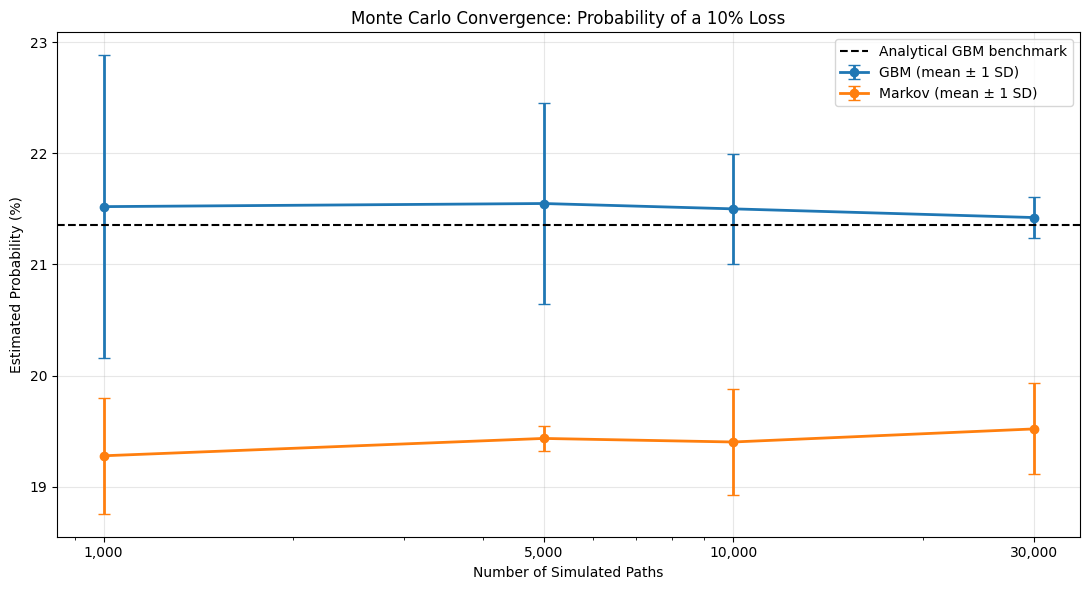

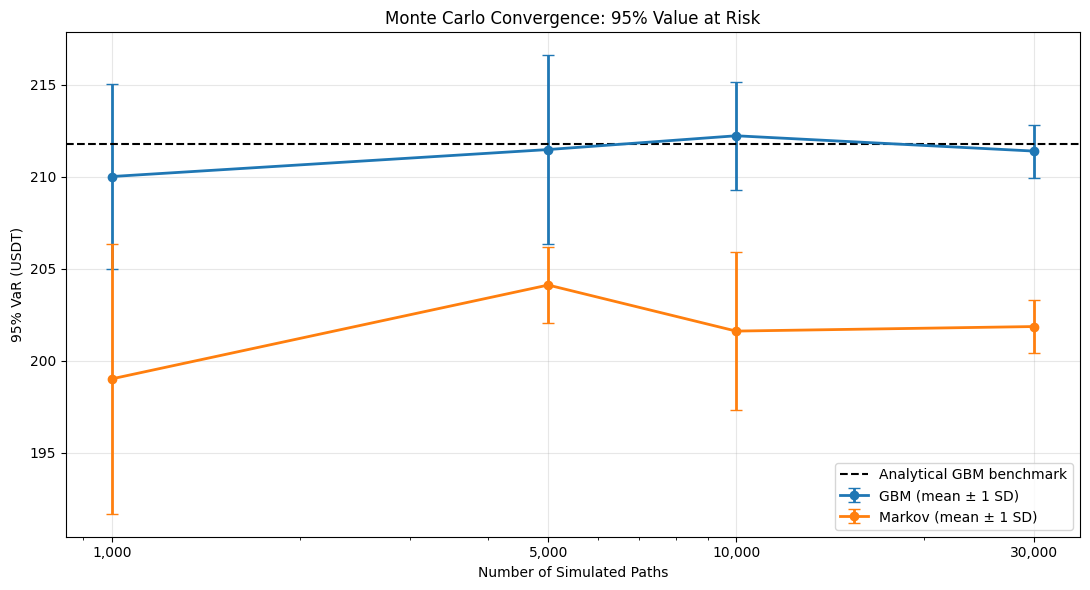


GBM 30,000-Path Verification
---------------------------------------------
Mean simulated probability: 21.4220%
Analytical probability:     21.3525%
Standard errors apart:     0.66

PASS: GBM convergence agrees with theory
PASS: Both convergence plots generated


In [29]:

# Day 5 - Step 3: Convergence visualisations

from scipy.stats import norm

# Independent analytical GBM benchmarks
gbm_theory_p10 = 100 * norm.cdf(
    (
        np.log1p(-0.10)
        - mu_cal * HORIZON_DAYS
    )
    / (sigma_cal * np.sqrt(HORIZON_DAYS))
)

gbm_theory_var95 = INITIAL_INVESTMENT * (
    1 - np.exp(
        mu_cal * HORIZON_DAYS
        + sigma_cal
        * np.sqrt(HORIZON_DAYS)
        * norm.ppf(0.05)
    )
)

print("Independent Analytical GBM Benchmarks")
print("-" * 45)
print(f"10% loss probability: {gbm_theory_p10:.4f}%")
print(f"95% VaR: {gbm_theory_var95:.2f} USDT")

# Graph 1: Probability convergence
plt.figure(figsize=(11, 6))

for model in ["GBM", "Markov"]:

    model_df = convergence_summary_df[
        convergence_summary_df["Model"] == model
    ].sort_values("Paths")

    plt.errorbar(
        model_df["Paths"],
        model_df["p10_mean"],
        yerr=model_df["p10_std"],
        marker="o",
        linewidth=2,
        capsize=4,
        label=f"{model} (mean ± 1 SD)"
    )

plt.axhline(
    gbm_theory_p10,
    color="black",
    linestyle="--",
    label="Analytical GBM benchmark"
)

plt.xscale("log")
plt.xticks(
    PATH_COUNTS,
    [f"{n:,}" for n in PATH_COUNTS]
)
plt.title(
    "Monte Carlo Convergence: Probability of a 10% Loss"
)
plt.xlabel("Number of Simulated Paths")
plt.ylabel("Estimated Probability (%)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: Value at Risk convergence
plt.figure(figsize=(11, 6))

for model in ["GBM", "Markov"]:

    model_df = convergence_summary_df[
        convergence_summary_df["Model"] == model
    ].sort_values("Paths")

    plt.errorbar(
        model_df["Paths"],
        model_df["var_mean"],
        yerr=model_df["var_std"],
        marker="o",
        linewidth=2,
        capsize=4,
        label=f"{model} (mean ± 1 SD)"
    )

plt.axhline(
    gbm_theory_var95,
    color="black",
    linestyle="--",
    label="Analytical GBM benchmark"
)

plt.xscale("log")
plt.xticks(
    PATH_COUNTS,
    [f"{n:,}" for n in PATH_COUNTS]
)
plt.title(
    "Monte Carlo Convergence: 95% Value at Risk"
)
plt.xlabel("Number of Simulated Paths")
plt.ylabel("95% VaR (USDT)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Independent numerical comparison at 30,000 paths
gbm_largest = convergence_summary_df[
    (convergence_summary_df["Model"] == "GBM")
    & (convergence_summary_df["Paths"] == max(PATH_COUNTS))
].iloc[0]

# Five runs at 30,000 paths = 150,000 Bernoulli outcomes.
p_theory = gbm_theory_p10 / 100

mean_probability_se = 100 * np.sqrt(
    p_theory * (1 - p_theory)
    / (max(PATH_COUNTS) * N_REPEATS)
)

difference = abs(
    gbm_largest["p10_mean"] - gbm_theory_p10
)

print("\nGBM 30,000-Path Verification")
print("-" * 45)
print(f"Mean simulated probability: "
      f"{gbm_largest['p10_mean']:.4f}%")
print(f"Analytical probability:     "
      f"{gbm_theory_p10:.4f}%")
print(f"Standard errors apart:     "
      f"{difference / mean_probability_se:.2f}")

assert difference <= 4 * mean_probability_se

print("\nPASS: GBM convergence agrees with theory")
print("PASS: Both convergence plots generated")



### 5.4 Sensitivity Analysis

Sensitivity analysis investigates how changes in model assumptions affect estimated Bitcoin downside risk.

The experiments alter one modelling dimension at a time while retaining the 2022–2024 calibration parameters for other dimensions.

Three dimensions are considered:

1. Volatility scaling for both GBM and Markov.
2. Markov regime-transition probabilities.
3. Initial Markov market regime.

These experiments assess the robustness of model-based risk estimates. They do not use the held-out 2025 observations for calibration.

#### 5.4.1 Volatility Sensitivity

Daily return volatility is multiplied by:

$$
k \in \{0.8,\ 1.0,\ 1.2\}
$$

For GBM:

$$
\sigma_{\text{GBM,new}} =
k\sigma_{\text{GBM}}
$$

For Markov:

$$
\sigma_{s,\text{new}} =
k\sigma_s,\qquad s\in\{0,1\}
$$

The mean-return parameters remain unchanged, and the Markov transition matrix is held fixed.

Each scenario is evaluated using 30,000 simulation paths and five independent seeds.

The comparison examines 30-day loss probabilities, 95% VaR and 95% Expected Shortfall.

The baseline scenario ($k=1$) is recalculated using the same experimental settings and seeds as the modified-volatility scenarios to improve comparability.

This is a conditional parameter sensitivity experiment, not a re-estimation of historical market regimes or future Bitcoin volatility.


In [30]:

# Day 5 - Step 4A: Volatility sensitivity analysis

VOLATILITY_MULTIPLIERS = [0.8, 1.0, 1.2]
SENSITIVITY_PATHS = 30_000
SENSITIVITY_SEEDS = [1201, 1202, 1203, 1204, 1205]

volatility_records = []

for multiplier in VOLATILITY_MULTIPLIERS:

    for seed in SENSITIVITY_SEEDS:

        # GBM: change volatility, preserve the fitted mean.
        gbm_sensitivity_paths = simulate_gbm_paths(
            initial_price=S0,
            mean_log_return=mu_cal,
            daily_volatility=sigma_cal * multiplier,
            horizon_days=HORIZON_DAYS,
            n_paths=SENSITIVITY_PATHS,
            seed=seed
        )

        # Markov: scale both regime volatilities equally.
        markov_sensitivity_paths, _ = simulate_markov_paths(
            initial_price=S0,
            initial_state=initial_regime,
            transition_probs=transition_matrix,
            regime_means=regime_mu,
            regime_volatilities=regime_sigma * multiplier,
            horizon_days=HORIZON_DAYS,
            n_paths=SENSITIVITY_PATHS,
            seed=seed
        )

        for model_name, paths in [
            ("GBM", gbm_sensitivity_paths),
            ("Markov", markov_sensitivity_paths)
        ]:

            losses = INITIAL_INVESTMENT * (
                1 - paths[:, -1] / S0
            )

            risk = calculate_risk_measures(
                losses,
                INITIAL_INVESTMENT
            )

            volatility_records.append({
                "Model": model_name,
                "Volatility scale": multiplier,
                "Seed": seed,
                "Loss >= 10%": risk["Loss >= 10%"],
                "Loss >= 20%": risk["Loss >= 20%"],
                "Loss >= 35%": risk["Loss >= 35%"],
                "VaR 95%": risk["VaR 95%"],
                "ES 95%": risk["ES 95%"]
            })

# Individual experimental runs
volatility_sensitivity_df = pd.DataFrame(
    volatility_records
)

# Aggregate the five independent runs per scenario.
volatility_summary_df = (
    volatility_sensitivity_df
    .groupby(["Model", "Volatility scale"], as_index=False)
    .agg(
        p10_mean=("Loss >= 10%", "mean"),
        p10_sd=("Loss >= 10%", "std"),
        p20_mean=("Loss >= 20%", "mean"),
        p35_mean=("Loss >= 35%", "mean"),
        var_mean=("VaR 95%", "mean"),
        var_sd=("VaR 95%", "std"),
        es_mean=("ES 95%", "mean")
    )
)

# Retrieve each model's own baseline for comparisons.
baseline_rows = volatility_summary_df[
    volatility_summary_df["Volatility scale"] == 1.0
][["Model", "p10_mean", "var_mean"]].rename(
    columns={
        "p10_mean": "baseline_p10",
        "var_mean": "baseline_var"
    }
)

volatility_summary_df = volatility_summary_df.merge(
    baseline_rows,
    on="Model",
    validate="many_to_one"
)

volatility_summary_df["Delta p10 (pp)"] = (
    volatility_summary_df["p10_mean"]
    - volatility_summary_df["baseline_p10"]
)

volatility_summary_df["Delta VaR (USDT)"] = (
    volatility_summary_df["var_mean"]
    - volatility_summary_df["baseline_var"]
)

print("Volatility Sensitivity Analysis")
print("-" * 65)
print("30,000 paths per run; 5 seeds per scenario\n")

display(
    volatility_summary_df[
        [
            "Model",
            "Volatility scale",
            "p10_mean",
            "p10_sd",
            "p20_mean",
            "p35_mean",
            "var_mean",
            "var_sd",
            "es_mean",
            "Delta p10 (pp)",
            "Delta VaR (USDT)"
        ]
    ].round(3)
)

# Verification
assert len(volatility_sensitivity_df) == (
    2
    * len(VOLATILITY_MULTIPLIERS)
    * len(SENSITIVITY_SEEDS)
)

assert volatility_sensitivity_df.groupby(
    ["Model", "Volatility scale"]
).size().eq(len(SENSITIVITY_SEEDS)).all()

assert np.isfinite(
    volatility_summary_df[
        ["p10_mean", "p20_mean", "p35_mean",
         "var_mean", "es_mean"]
    ].to_numpy()
).all()

assert (volatility_summary_df["var_mean"] > 0).all()
assert (
    volatility_summary_df["es_mean"]
    >= volatility_summary_df["var_mean"]
).all()

baseline_deltas = volatility_summary_df[
    volatility_summary_df["Volatility scale"] == 1.0
]

np.testing.assert_allclose(
    baseline_deltas["Delta p10 (pp)"],
    0,
    atol=1e-10
)

np.testing.assert_allclose(
    baseline_deltas["Delta VaR (USDT)"],
    0,
    atol=1e-10
)

print("\nPASS: All 30 sensitivity runs completed")
print("PASS: Five runs per model and scenario")
print("PASS: Sensitivity risk estimates are valid")
print("PASS: Baseline scenario differences equal zero")


Volatility Sensitivity Analysis
-----------------------------------------------------------------
30,000 paths per run; 5 seeds per scenario



,Model,Volatility scale,p10_mean,p10_sd,p20_mean,p35_mean,var_mean,var_sd,es_mean,Delta p10 (pp),Delta VaR (USDT)
0,GBM,0.8,15.985,0.141,2.610,0.020,170.029,0.545,211.436,-5.263,-41.427
1,GBM,1.0,21.247,0.156,6.026,0.199,211.456,0.647,260.078,0.000,0.000
2,GBM,1.2,25.223,0.137,9.731,0.832,250.816,0.738,305.631,3.976,39.360
3,Markov,0.8,14.075,0.173,2.209,0.017,162.246,0.935,205.051,-5.277,-40.864
4,Markov,1.0,19.352,0.155,5.277,0.195,203.110,1.067,253.247,0.000,0.000
5,Markov,1.2,23.584,0.127,8.663,0.745,242.105,1.406,298.448,4.232,38.995



PASS: All 30 sensitivity runs completed
PASS: Five runs per model and scenario
PASS: Sensitivity risk estimates are valid
PASS: Baseline scenario differences equal zero



#### 5.4.2 Markov Transition Probability Sensitivity

This experiment examines the sensitivity of the two-state Markov model to changes in the probabilities of switching between calm and volatile market regimes.

Switching probabilities are scaled by:

$$
k \in \{0.5,\ 1.0,\ 1.5\}
$$

The modified transition matrix is:

$$
P(k)=
\begin{bmatrix}
1-kp_{01} & kp_{01}\\
kp_{10} & 1-kp_{10}
\end{bmatrix}
$$

where $p_{01}$ and $p_{10}$ are the estimated probabilities of switching between regimes.

The diagonal probabilities are adjusted to preserve valid probability distributions.

Each scenario uses 30,000 paths and five independent random seeds. All other model parameters remain unchanged.

The experiment records:

- Regime-switching probabilities and expected regime durations
- Loss probabilities at the 10%, 20%, and 35% thresholds
- 95% Value at Risk and Expected Shortfall
- The simulated and theoretical terminal calm-regime proportions

The theoretical terminal-state distribution is calculated using the modified transition matrix:

$$
\pi_{30}=\pi_0P(k)^{30}
$$

Changing switching probabilities while holding conditional return distributions fixed is a controlled sensitivity experiment, not a new calibration from historical data.

An increase in switching frequency does not necessarily produce a monotonic change in downside risk because the effect depends on the initial regime, conditional return distributions and simulated regime histories.


In [31]:

# Day 5 - Step 4B: Markov transition sensitivity

TRANSITION_SCALES = [0.5, 1.0, 1.5]

transition_sensitivity_records = []
transition_theory_records = []

for scale in TRANSITION_SCALES:

    # Modify only the off-diagonal switching probabilities.
    modified_P = transition_matrix.copy()

    modified_P[0, 1] = transition_matrix[0, 1] * scale
    modified_P[1, 0] = transition_matrix[1, 0] * scale

    # Recalculate persistence probabilities.
    modified_P[0, 0] = 1 - modified_P[0, 1]
    modified_P[1, 1] = 1 - modified_P[1, 0]

    # Verify transition-matrix validity.
    assert np.all(modified_P >= 0)
    assert np.all(modified_P <= 1)

    np.testing.assert_allclose(
        modified_P.sum(axis=1),
        [1.0, 1.0]
    )

    # Expected number of consecutive days in each state.
    calm_duration = 1 / modified_P[0, 1]
    volatile_duration = 1 / modified_P[1, 0]

    # Independent theoretical terminal-state probability.
    P_power = np.linalg.matrix_power(
        modified_P,
        HORIZON_DAYS
    )

    theory_final_calm = P_power[initial_regime, 0]

    transition_theory_records.append({
        "Transition scale": scale,
        "Calm -> Volatile": modified_P[0, 1],
        "Volatile -> Calm": modified_P[1, 0],
        "Calm duration": calm_duration,
        "Volatile duration": volatile_duration,
        "Theory final calm": 100 * theory_final_calm
    })

    # Five independently seeded simulations.
    for seed in SENSITIVITY_SEEDS:

        paths, states = simulate_markov_paths(
            initial_price=S0,
            initial_state=initial_regime,
            transition_probs=modified_P,
            regime_means=regime_mu,
            regime_volatilities=regime_sigma,
            horizon_days=HORIZON_DAYS,
            n_paths=SENSITIVITY_PATHS,
            seed=seed
        )

        losses = INITIAL_INVESTMENT * (
            1 - paths[:, -1] / S0
        )

        risk = calculate_risk_measures(
            losses,
            INITIAL_INVESTMENT
        )

        final_calm_pct = 100 * np.mean(
            states[:, -1] == 0
        )

        transition_sensitivity_records.append({
            "Transition scale": scale,
            "Seed": seed,
            "Loss >= 10%": risk["Loss >= 10%"],
            "Loss >= 20%": risk["Loss >= 20%"],
            "Loss >= 35%": risk["Loss >= 35%"],
            "VaR 95%": risk["VaR 95%"],
            "ES 95%": risk["ES 95%"],
            "Final calm (%)": final_calm_pct
        })

# Individual run results
transition_sensitivity_df = pd.DataFrame(
    transition_sensitivity_records
)

# Aggregate across the five random seeds.
transition_summary_df = (
    transition_sensitivity_df
    .groupby("Transition scale", as_index=False)
    .agg(
        p10_mean=("Loss >= 10%", "mean"),
        p10_sd=("Loss >= 10%", "std"),
        p20_mean=("Loss >= 20%", "mean"),
        p35_mean=("Loss >= 35%", "mean"),
        var_mean=("VaR 95%", "mean"),
        var_sd=("VaR 95%", "std"),
        es_mean=("ES 95%", "mean"),
        simulated_final_calm=("Final calm (%)", "mean")
    )
)

# Attach the independent Markov-chain theoretical results.
transition_summary_df = transition_summary_df.merge(
    pd.DataFrame(transition_theory_records),
    on="Transition scale",
    validate="one_to_one"
)

# Compare each scenario against its own baseline.
baseline_row = transition_summary_df[
    transition_summary_df["Transition scale"] == 1.0
].iloc[0]

transition_summary_df["Delta p10 (pp)"] = (
    transition_summary_df["p10_mean"]
    - baseline_row["p10_mean"]
)

transition_summary_df["Delta VaR (USDT)"] = (
    transition_summary_df["var_mean"]
    - baseline_row["var_mean"]
)

print("Markov Transition Sensitivity Analysis")
print("-" * 65)
print("30,000 paths per run; 5 seeds per scenario\n")

display(
    transition_summary_df[
        [
            "Transition scale",
            "Calm -> Volatile",
            "Volatile -> Calm",
            "Calm duration",
            "Volatile duration",
            "p10_mean",
            "p10_sd",
            "p20_mean",
            "p35_mean",
            "var_mean",
            "var_sd",
            "es_mean",
            "simulated_final_calm",
            "Theory final calm",
            "Delta p10 (pp)",
            "Delta VaR (USDT)"
        ]
    ].round(3)
)

# Verification 1: All runs completed.
assert len(transition_sensitivity_df) == (
    len(TRANSITION_SCALES)
    * len(SENSITIVITY_SEEDS)
)

assert transition_sensitivity_df.groupby(
    "Transition scale"
).size().eq(len(SENSITIVITY_SEEDS)).all()

# Verification 2: Risk measures are valid.
assert np.isfinite(
    transition_summary_df[
        ["p10_mean", "p20_mean", "p35_mean",
         "var_mean", "es_mean"]
    ].to_numpy()
).all()

assert (
    transition_summary_df["es_mean"]
    >= transition_summary_df["var_mean"]
).all()

# Verification 3: Theoretical terminal-state probabilities.
for _, row in transition_summary_df.iterrows():

    p = row["Theory final calm"] / 100

    se_pct = 100 * np.sqrt(
        p * (1 - p)
        / (SENSITIVITY_PATHS * len(SENSITIVITY_SEEDS))
    )

    difference = abs(
        row["simulated_final_calm"]
        - row["Theory final calm"]
    )

    assert difference <= 4 * se_pct

# Verification 4: Baseline should reproduce the
# Markov baseline of our volatility sensitivity experiment,
# because we used the same seeds and model parameters.
volatility_markov_baseline = volatility_summary_df[
    (volatility_summary_df["Model"] == "Markov")
    & (volatility_summary_df["Volatility scale"] == 1.0)
].iloc[0]

np.testing.assert_allclose(
    [
        baseline_row["p10_mean"],
        baseline_row["var_mean"]
    ],
    [
        volatility_markov_baseline["p10_mean"],
        volatility_markov_baseline["var_mean"]
    ],
    rtol=0,
    atol=1e-10
)

print("\nPASS: All 15 transition sensitivity runs completed")
print("PASS: Modified transition matrices are valid")
print("PASS: Terminal-state proportions agree with theory")
print("PASS: Baseline matches the previous Markov experiment")
print("PASS: All transition sensitivity results are valid")


Markov Transition Sensitivity Analysis
-----------------------------------------------------------------
30,000 paths per run; 5 seeds per scenario



,Transition scale,Calm -> Volatile,Volatile -> Calm,Calm duration,Volatile duration,p10_mean,p10_sd,p20_mean,p35_mean,var_mean,var_sd,es_mean,simulated_final_calm,Theory final calm,Delta p10 (pp),Delta VaR (USDT)
0,0.5,0.038,0.038,26.341,26.390,18.284,0.124,4.705,0.166,196.116,1.636,246.506,54.559,54.648,-1.068,-6.994
1,1.0,0.076,0.076,13.171,13.195,19.352,0.155,5.277,0.195,203.110,1.067,253.247,50.265,50.313,0.000,0.000
2,1.5,0.114,0.114,8.780,8.797,19.781,0.154,5.481,0.201,205.501,1.122,255.496,50.033,49.975,0.429,2.391



PASS: All 15 transition sensitivity runs completed
PASS: Modified transition matrices are valid
PASS: Terminal-state proportions agree with theory
PASS: Baseline matches the previous Markov experiment
PASS: All transition sensitivity results are valid



#### 5.4.3 Initial Regime Sensitivity

This experiment investigates the effect of the initial market regime on 30-day downside-risk estimates produced by the Markov model.

Two initial conditions are compared:

- **Calm (state 0):** The observed regime on December 31, 2024.
- **Volatile (state 1):** A hypothetical alternative initial condition.

Both scenarios retain identical calibrated regime-specific return parameters, transition probabilities, initial Bitcoin price, investment amount and forecast horizon.

Each scenario is simulated using 30,000 paths and five independent random seeds.

The experiment measures:

1. Probability of losses of at least 10%, 20%, and 35%.
2. 95% Value at Risk and Expected Shortfall.
3. Average number of simulated days spent in the volatile regime.
4. Final-state proportions compared against Markov-chain theoretical probabilities.

The state used to generate each day's return is counted when calculating volatile-regime exposure. The terminal state sampled after the last return is excluded from this exposure measure.

The experiment evaluates sensitivity to the model's starting state. The volatile-start scenario is hypothetical and does not replace the observed calm initial regime used in the main comparison.


In [32]:

# Day 5 - Step 4C: Initial regime sensitivity

INITIAL_REGIME_SCENARIOS = {
    0: "Start Calm",
    1: "Start Volatile"
}

initial_regime_records = []

# Independent theoretical state distribution after 30 days.
P_30 = np.linalg.matrix_power(
    transition_matrix,
    HORIZON_DAYS
)

for starting_state, scenario_name in (
    INITIAL_REGIME_SCENARIOS.items()
):

    for seed in SENSITIVITY_SEEDS:

        paths, states = simulate_markov_paths(
            initial_price=S0,
            initial_state=starting_state,
            transition_probs=transition_matrix,
            regime_means=regime_mu,
            regime_volatilities=regime_sigma,
            horizon_days=HORIZON_DAYS,
            n_paths=SENSITIVITY_PATHS,
            seed=seed
        )

        losses = INITIAL_INVESTMENT * (
            1 - paths[:, -1] / S0
        )

        risk = calculate_risk_measures(
            losses,
            INITIAL_INVESTMENT
        )

        # States that actually generate returns:
        # Day 0 through Day 29, excluding terminal Day 30.
        active_states = states[:, :-1]

        average_volatile_days = (
            (active_states == 1)
            .sum(axis=1)
            .mean()
        )

        final_calm_pct = (
            100 * np.mean(states[:, -1] == 0)
        )

        initial_regime_records.append({
            "Scenario": scenario_name,
            "Starting state": starting_state,
            "Seed": seed,
            "Loss >= 10%": risk["Loss >= 10%"],
            "Loss >= 20%": risk["Loss >= 20%"],
            "Loss >= 35%": risk["Loss >= 35%"],
            "VaR 95%": risk["VaR 95%"],
            "ES 95%": risk["ES 95%"],
            "Average volatile days": average_volatile_days,
            "Final calm (%)": final_calm_pct
        })

# Store individual runs.
initial_regime_sensitivity_df = pd.DataFrame(
    initial_regime_records
)

# Aggregate five runs for each starting state.
initial_regime_summary_df = (
    initial_regime_sensitivity_df
    .groupby(
        ["Starting state", "Scenario"],
        as_index=False
    )
    .agg(
        p10_mean=("Loss >= 10%", "mean"),
        p10_sd=("Loss >= 10%", "std"),
        p20_mean=("Loss >= 20%", "mean"),
        p35_mean=("Loss >= 35%", "mean"),
        var_mean=("VaR 95%", "mean"),
        var_sd=("VaR 95%", "std"),
        es_mean=("ES 95%", "mean"),
        avg_volatile_days=("Average volatile days", "mean"),
        final_calm=("Final calm (%)", "mean")
    )
)

# Add the theoretical final calm-state probability.
initial_regime_summary_df["Theory final calm"] = (
    initial_regime_summary_df["Starting state"]
    .map(lambda s: 100 * P_30[int(s), 0])
)

# Calculate differences relative to starting calm.
calm_row = initial_regime_summary_df[
    initial_regime_summary_df["Starting state"] == 0
].iloc[0]

initial_regime_summary_df["Delta p10 (pp)"] = (
    initial_regime_summary_df["p10_mean"]
    - calm_row["p10_mean"]
)

initial_regime_summary_df["Delta VaR (USDT)"] = (
    initial_regime_summary_df["var_mean"]
    - calm_row["var_mean"]
)

print("Markov Initial Regime Sensitivity")
print("-" * 65)
print("30,000 paths per run; 5 seeds per scenario\n")

display(
    initial_regime_summary_df[
        [
            "Scenario",
            "p10_mean",
            "p10_sd",
            "p20_mean",
            "p35_mean",
            "var_mean",
            "var_sd",
            "es_mean",
            "avg_volatile_days",
            "final_calm",
            "Theory final calm",
            "Delta p10 (pp)",
            "Delta VaR (USDT)"
        ]
    ].round(3)
)

# -------------------------------------------------
# Verification 1: Experiment completeness
# -------------------------------------------------
assert len(initial_regime_sensitivity_df) == (
    len(INITIAL_REGIME_SCENARIOS)
    * len(SENSITIVITY_SEEDS)
)

assert initial_regime_sensitivity_df.groupby(
    "Starting state"
).size().eq(len(SENSITIVITY_SEEDS)).all()

# -------------------------------------------------
# Verification 2: Valid numerical results
# -------------------------------------------------
numeric_columns = [
    "p10_mean",
    "p20_mean",
    "p35_mean",
    "var_mean",
    "es_mean",
    "avg_volatile_days",
    "final_calm"
]

assert np.isfinite(
    initial_regime_summary_df[numeric_columns].to_numpy()
).all()

assert (
    initial_regime_summary_df["es_mean"]
    >= initial_regime_summary_df["var_mean"]
).all()

assert (
    initial_regime_summary_df["avg_volatile_days"]
    .between(0, HORIZON_DAYS)
).all()

# -------------------------------------------------
# Verification 3: Theoretical terminal probabilities
# -------------------------------------------------
for _, row in initial_regime_summary_df.iterrows():

    p = row["Theory final calm"] / 100

    standard_error_pct = 100 * np.sqrt(
        p * (1 - p)
        / (SENSITIVITY_PATHS * len(SENSITIVITY_SEEDS))
    )

    difference = abs(
        row["final_calm"] - row["Theory final calm"]
    )

    assert difference <= 4 * standard_error_pct

# -------------------------------------------------
# Verification 4: Reproduce existing calm baseline
# -------------------------------------------------
transition_baseline = transition_summary_df[
    transition_summary_df["Transition scale"] == 1.0
].iloc[0]

np.testing.assert_allclose(
    [
        calm_row["p10_mean"],
        calm_row["var_mean"],
        calm_row["es_mean"]
    ],
    [
        transition_baseline["p10_mean"],
        transition_baseline["var_mean"],
        transition_baseline["es_mean"]
    ],
    rtol=0,
    atol=1e-10
)

print("\nPASS: All 10 initial-regime runs completed")
print("PASS: Risk estimates and regime durations are valid")
print("PASS: Final-state proportions agree with theory")
print("PASS: Calm-start scenario reproduces previous baseline")
print("PASS: Initial regime sensitivity completed")


Markov Initial Regime Sensitivity
-----------------------------------------------------------------
30,000 paths per run; 5 seeds per scenario



,Scenario,p10_mean,p10_sd,p20_mean,p35_mean,var_mean,var_sd,es_mean,avg_volatile_days,final_calm,Theory final calm,Delta p10 (pp),Delta VaR (USDT)
0,Start Calm,19.352,0.155,5.277,0.195,203.11,1.067,253.247,11.735,50.265,50.313,0.000,0.00
1,Start Volatile,21.785,0.192,6.687,0.340,219.24,0.910,270.857,18.284,49.586,49.595,2.433,16.13



PASS: All 10 initial-regime runs completed
PASS: Risk estimates and regime durations are valid
PASS: Final-state proportions agree with theory
PASS: Calm-start scenario reproduces previous baseline
PASS: Initial regime sensitivity completed



### 5.5 Held-Out 2025 Out-of-Sample Evaluation

The GBM and two-state Markov models are evaluated against actual BTC/USDT price movements during 2025.

Model parameters, regime definitions, and transition probabilities were estimated using 2022–2024 calibration data only.

The evaluation uses rolling 30-day forecast windows beginning on eligible dates in 2025.

For a forecast origin $t$, the realised 30-day Bitcoin return is:

$$
R_{t,t+30}=\frac{P_{t+30}}{P_t}-1
$$

The corresponding investment loss fraction is:

$$
L_{t,t+30}=1-\frac{P_{t+30}}{P_t}
$$

A realised loss event at threshold $d$ is defined as:

$$
Y_t(d)=
\begin{cases}
1, & L_{t,t+30}\ge d\\
0, & L_{t,t+30}<d
\end{cases}
$$

Loss thresholds of 10%, 20%, and 35% are evaluated.

For Markov, the initial forecast regime is determined using the trailing 14-day rolling volatility available at each forecast origin. The regime threshold remains fixed at its 2022–2024 calibration value.

The first stage prepares the realised outcomes and checks chronological alignment. Predicted probabilities and Brier scores are calculated in subsequent stages.

The 30-day evaluation windows overlap substantially, so the resulting observations are not independent. This dependence must be considered when interpreting forecast-performance differences.


In [34]:

# Day 5 - Step 5A:
# Construct held-out 2025 rolling evaluation windows

EVALUATION_HORIZON = 30

# Select 2025 observations from the full historical dataset.
# The rolling volatility was already computed using past
# and current returns, including the necessary 2024 history.
eval_2025_df = (
    price_df[
        (price_df["date"] >= pd.Timestamp(
            "2025-01-01", tz="UTC"
        ))
        &
        (price_df["date"] <= pd.Timestamp(
            "2025-12-31", tz="UTC"
        ))
    ]
    .copy()
    .sort_values("date")
    .reset_index(drop=True)
)

# Historical integrity checks.
assert len(eval_2025_df) == 365

assert eval_2025_df["date"].is_unique

assert (
    eval_2025_df["date"]
    .diff()
    .dropna()
    .eq(pd.Timedelta(days=1))
    .all()
)

assert eval_2025_df["close"].gt(0).all()

assert eval_2025_df[
    "rolling_vol_14d"
].notna().all()

# Align each forecast origin with the price 30 days later.
eval_2025_df["future_date"] = (
    eval_2025_df["date"]
    .shift(-EVALUATION_HORIZON)
)

eval_2025_df["future_close"] = (
    eval_2025_df["close"]
    .shift(-EVALUATION_HORIZON)
)

# Retain origins for which the full 30-day outcome exists.
evaluation_windows_df = (
    eval_2025_df
    .dropna(subset=["future_date", "future_close"])
    .copy()
    .reset_index(drop=True)
)

# Calculate actual 30-day return and loss fraction.
evaluation_windows_df["realized_return_30d"] = (
    evaluation_windows_df["future_close"]
    / evaluation_windows_df["close"]
    - 1
)

evaluation_windows_df["realized_loss_30d"] = (
    -evaluation_windows_df["realized_return_30d"]
)

# Classify each forecast origin using information available
# on that date and the FIXED calibration-period threshold.
evaluation_windows_df["initial_regime"] = np.where(
    evaluation_windows_df["rolling_vol_14d"]
    < regime_threshold,
    0,
    1
).astype(int)

# Define actual loss events at the three thresholds.
for threshold in [0.10, 0.20, 0.35]:

    column_name = f"event_{int(threshold * 100)}"

    evaluation_windows_df[column_name] = (
        evaluation_windows_df["realized_loss_30d"]
        >= threshold
    ).astype(int)

print("2025 Out-of-Sample Evaluation Dataset")
print("-" * 60)

print(f"2025 daily observations: {len(eval_2025_df)}")
print(
    f"Eligible 30-day forecast origins: "
    f"{len(evaluation_windows_df)}"
)

print(
    f"First forecast origin: "
    f"{evaluation_windows_df['date'].iloc[0]}"
)

print(
    f"Last forecast origin:  "
    f"{evaluation_windows_df['date'].iloc[-1]}"
)

print(
    f"Final outcome date:   "
    f"{evaluation_windows_df['future_date'].iloc[-1]}"
)

# Summary of the actual 2025 loss outcomes.
outcome_summary_df = pd.DataFrame([
    {
        "Loss threshold": f"{threshold:.0%}",
        "Event count": int(
            evaluation_windows_df[
                f"event_{int(threshold * 100)}"
            ].sum()
        ),
        "Observed frequency (%)": (
            100 * evaluation_windows_df[
                f"event_{int(threshold * 100)}"
            ].mean()
        )
    }
    for threshold in [0.10, 0.20, 0.35]
])

print("\nObserved 2025 Loss Events")
display(outcome_summary_df.round(3))

print("\nInitial Regimes at Forecast Origins")
display(
    evaluation_windows_df[
        "initial_regime"
    ].map(regime_names).value_counts()
)

# -------------------------------------------------
# Verification
# -------------------------------------------------

assert len(evaluation_windows_df) == (
    365 - EVALUATION_HORIZON
)

assert evaluation_windows_df["date"].iloc[0] == (
    pd.Timestamp("2025-01-01", tz="UTC")
)

assert evaluation_windows_df["date"].iloc[-1] == (
    pd.Timestamp("2025-12-01", tz="UTC")
)

assert (
    evaluation_windows_df["future_date"]
    - evaluation_windows_df["date"]
).eq(
    pd.Timedelta(days=EVALUATION_HORIZON)
).all()

assert (
    evaluation_windows_df["future_close"] > 0
).all()

assert np.isfinite(
    evaluation_windows_df["realized_loss_30d"]
).all()

assert evaluation_windows_df[
    "initial_regime"
].isin([0, 1]).all()

# More severe losses must be subsets of milder losses.
assert (
    evaluation_windows_df["event_35"]
    <= evaluation_windows_df["event_20"]
).all()

assert (
    evaluation_windows_df["event_20"]
    <= evaluation_windows_df["event_10"]
).all()

# Confirm the stored rolling-volatility value for
# the first forecast origin uses only observations
# available up to and including that date.
first_origin_date = evaluation_windows_df[
    "date"
].iloc[0]

historical_returns_to_origin = (
    price_df.loc[
        price_df["date"] <= first_origin_date,
        "log_return"
    ]
    .dropna()
    .tail(14)
)

recalculated_volatility = (
    historical_returns_to_origin.std(ddof=1)
)

stored_volatility = evaluation_windows_df[
    "rolling_vol_14d"
].iloc[0]

np.testing.assert_allclose(
    recalculated_volatility,
    stored_volatility,
    rtol=1e-12,
    atol=1e-12
)

print("\nPASS: All 335 forecast windows are valid")
print("PASS: Every outcome is exactly 30 days ahead")
print("PASS: Loss events are correctly nested")
print("PASS: Initial regime uses past/current information")
print("PASS: 2025 evaluation dataset prepared")


2025 Out-of-Sample Evaluation Dataset
------------------------------------------------------------
2025 daily observations: 365
Eligible 30-day forecast origins: 335
First forecast origin: 2025-01-01 00:00:00+00:00
Last forecast origin:  2025-12-01 00:00:00+00:00
Final outcome date:   2025-12-31 00:00:00+00:00

Observed 2025 Loss Events


,Loss threshold,Event count,Observed frequency (%)
0,10%,62,18.507
1,20%,8,2.388
2,35%,0,0.000



Initial Regimes at Forecast Origins


,count
initial_regime,
Calm,269
Volatile,66



PASS: All 335 forecast windows are valid
PASS: Every outcome is exactly 30 days ahead
PASS: Loss events are correctly nested
PASS: Initial regime uses past/current information
PASS: 2025 evaluation dataset prepared



#### 5.5.1 Out-of-Sample Probability Forecasts and Brier Scores

This experiment compares 30-day downside-risk probability forecasts from GBM and the two-state Markov model with realised outcomes from 335 held-out forecast origins in 2025.

The GBM forecasts are calculated analytically using the fixed 2022–2024 calibration parameters.

For the Markov model, 200,000 Monte Carlo paths are simulated for each possible initial regime (calm and volatile), using the unchanged calibration-period transition matrix and conditional return parameters.

Each 2025 forecast receives the Markov probability corresponding to its observed initial regime. No model parameters are re-estimated using 2025 observations.

Forecast accuracy is evaluated using the Brier score:

$$
BS = \frac{1}{N}\sum_{t=1}^{N}(p_t-y_t)^2
$$

where:

- $p_t$ is the predicted probability of the specified loss event.
- $y_t$ is 1 if the event occurred and 0 otherwise.
- $N=335$ is the number of forecast origins.

A lower Brier score indicates lower mean squared probability-forecast error.

The difference is defined as:

$$
\Delta BS = BS_{\mathrm{Markov}} - BS_{\mathrm{GBM}}
$$

A negative difference favours Markov; a positive difference favours GBM.

Markov probability estimates also receive 95% Wilson confidence intervals to quantify finite Monte Carlo sampling uncertainty.

These intervals do not account for calibration-parameter uncertainty.

Because the 30-day forecast windows overlap, Brier score differences cannot be treated as statistically independent observations. Dependence-aware uncertainty analysis is required before making strong comparative claims.

The absence of observed 35% loss events in 2025 particularly limits conclusions about extreme-tail forecasting.


In [35]:

# Day 5 - Step 5B:
# Out-of-sample probability forecasts and Brier scores

from scipy.stats import norm, binomtest

OOS_MC_PATHS = 200_000
OOS_MC_SEED = 20251121

LOSS_THRESHOLDS_PCT = [10, 20, 35]

# --------------------------------------------------
# 1. Analytical GBM loss probabilities
# --------------------------------------------------

gbm_oos_probabilities = {}

for pct in LOSS_THRESHOLDS_PCT:

    threshold = pct / 100

    gbm_oos_probabilities[pct] = float(
        norm.cdf(
            (
                np.log1p(-threshold)
                - mu_cal * HORIZON_DAYS
            )
            / (
                sigma_cal * np.sqrt(HORIZON_DAYS)
            )
        )
    )

# --------------------------------------------------
# 2. Markov forecasts for both initial regimes
# --------------------------------------------------

markov_oos_probabilities = {}
markov_forecast_records = []

for state in [0, 1]:

    paths, _ = simulate_markov_paths(
        initial_price=S0,
        initial_state=state,
        transition_probs=transition_matrix,
        regime_means=regime_mu,
        regime_volatilities=regime_sigma,
        horizon_days=HORIZON_DAYS,
        n_paths=OOS_MC_PATHS,
        seed=OOS_MC_SEED + state
    )

    # Loss fraction, not USDT loss.
    # Using a price ratio allows the forecasts to be
    # applied to different BTC prices during 2025.
    loss_fractions = 1 - paths[:, -1] / S0

    state_probabilities = {}

    for pct in LOSS_THRESHOLDS_PCT:

        threshold = pct / 100

        event_count = int(
            np.count_nonzero(
                loss_fractions >= threshold
            )
        )

        probability = event_count / OOS_MC_PATHS

        interval = binomtest(
            event_count,
            OOS_MC_PATHS
        ).proportion_ci(
            confidence_level=0.95,
            method="wilson"
        )

        state_probabilities[pct] = probability

        markov_forecast_records.append({
            "Initial regime": regime_names[state],
            "Loss threshold": f"{pct}%",
            "Predicted probability (%)":
                100 * probability,
            "95% CI low (%)": 100 * interval.low,
            "95% CI high (%)": 100 * interval.high,
            "Simulated loss events": event_count
        })

    markov_oos_probabilities[state] = (
        state_probabilities
    )

# Display model forecasts before scoring.
print("Markov 30-Day Probability Forecasts")
print("-" * 65)
print(f"Simulation paths per initial regime: "
      f"{OOS_MC_PATHS:,}")

markov_forecast_df = pd.DataFrame(
    markov_forecast_records
)

display(markov_forecast_df.round(4))

# --------------------------------------------------
# 3. Attach forecasts to 2025 evaluation windows
# --------------------------------------------------

for pct in LOSS_THRESHOLDS_PCT:

    # GBM probability is constant across forecast origins.
    evaluation_windows_df[
        f"gbm_prob_{pct}"
    ] = gbm_oos_probabilities[pct]

    # Markov probability depends on the regime at origin.
    evaluation_windows_df[
        f"markov_prob_{pct}"
    ] = (
        evaluation_windows_df["initial_regime"]
        .map({
            0: markov_oos_probabilities[0][pct],
            1: markov_oos_probabilities[1][pct]
        })
    )

# --------------------------------------------------
# 4. Calculate Brier scores
# --------------------------------------------------

brier_records = []

for pct in LOSS_THRESHOLDS_PCT:

    observed = (
        evaluation_windows_df[f"event_{pct}"]
        .to_numpy(dtype=float)
    )

    gbm_forecasts = (
        evaluation_windows_df[f"gbm_prob_{pct}"]
        .to_numpy(dtype=float)
    )

    markov_forecasts = (
        evaluation_windows_df[f"markov_prob_{pct}"]
        .to_numpy(dtype=float)
    )

    # Per-origin squared probability errors.
    gbm_squared_errors = (
        gbm_forecasts - observed
    ) ** 2

    markov_squared_errors = (
        markov_forecasts - observed
    ) ** 2

    # Save individual errors for later dependent-data
    # uncertainty analysis.
    evaluation_windows_df[
        f"gbm_brier_{pct}"
    ] = gbm_squared_errors

    evaluation_windows_df[
        f"markov_brier_{pct}"
    ] = markov_squared_errors

    gbm_bs = float(gbm_squared_errors.mean())
    markov_bs = float(markov_squared_errors.mean())

    brier_records.append({
        "Loss threshold": f"{pct}%",
        "Observed events": int(observed.sum()),
        "Observed frequency (%)": 100 * observed.mean(),
        "GBM predicted (%)": 100 * gbm_forecasts.mean(),
        "Markov predicted (%)": 100 * markov_forecasts.mean(),
        "GBM Brier": gbm_bs,
        "Markov Brier": markov_bs,
        "Markov - GBM": markov_bs - gbm_bs,
        "Lower Brier": (
            "Markov" if markov_bs < gbm_bs
            else "GBM" if gbm_bs < markov_bs
            else "Tie"
        )
    })

oos_brier_df = pd.DataFrame(brier_records)

print("\nHeld-Out 2025 Brier Score Comparison")
print("-" * 65)

display(oos_brier_df.round(7))

# --------------------------------------------------
# 5. Conditional calibration diagnostic
# --------------------------------------------------

conditional_records = []

for state in [0, 1]:

    subset = evaluation_windows_df[
        evaluation_windows_df["initial_regime"] == state
    ]

    for pct in LOSS_THRESHOLDS_PCT:

        conditional_records.append({
            "Regime": regime_names[state],
            "Threshold": f"{pct}%",
            "Forecast origins": len(subset),
            "Observed events":
                int(subset[f"event_{pct}"].sum()),
            "Observed frequency (%)":
                100 * subset[f"event_{pct}"].mean(),
            "Markov forecast (%)":
                100 * markov_oos_probabilities[state][pct],
            "GBM forecast (%)":
                100 * gbm_oos_probabilities[pct]
        })

conditional_oos_df = pd.DataFrame(
    conditional_records
)

print("\n2025 Results by Initial Market Regime")
display(conditional_oos_df.round(4))

# --------------------------------------------------
# 6. Verification
# --------------------------------------------------

assert len(evaluation_windows_df) == 335

assert len(oos_brier_df) == 3

assert len(markov_forecast_df) == 6

# All forecast probabilities must be valid.
for pct in LOSS_THRESHOLDS_PCT:

    for model in ["gbm", "markov"]:

        probabilities = (
            evaluation_windows_df[
                f"{model}_prob_{pct}"
            ]
        )

        assert probabilities.between(0, 1).all()

        squared_errors = (
            evaluation_windows_df[
                f"{model}_brier_{pct}"
            ]
        )

        assert squared_errors.between(0, 1).all()

# Risk probabilities must decrease or remain equal
# as the loss threshold becomes more severe.
for model in ["gbm", "markov"]:

    assert (
        evaluation_windows_df[f"{model}_prob_10"]
        >= evaluation_windows_df[f"{model}_prob_20"]
    ).all()

    assert (
        evaluation_windows_df[f"{model}_prob_20"]
        >= evaluation_windows_df[f"{model}_prob_35"]
    ).all()

assert np.isfinite(
    oos_brier_df[
        ["GBM Brier", "Markov Brier", "Markov - GBM"]
    ].to_numpy()
).all()

# The GBM analytical probability does not vary
# with the forecast-origin date.
for pct in LOSS_THRESHOLDS_PCT:

    assert (
        evaluation_windows_df[
            f"gbm_prob_{pct}"
        ].nunique() == 1
    )

# The Markov forecast must match the initial state.
for state in [0, 1]:

    subset = evaluation_windows_df[
        evaluation_windows_df["initial_regime"] == state
    ]

    for pct in LOSS_THRESHOLDS_PCT:

        np.testing.assert_allclose(
            subset[f"markov_prob_{pct}"],
            markov_oos_probabilities[state][pct],
            rtol=0,
            atol=1e-12
        )

print("\nPASS: GBM analytical forecasts are valid")
print("PASS: Markov forecasts use the correct initial regime")
print("PASS: Loss probabilities follow threshold ordering")
print("PASS: All Brier scores are finite and valid")
print("PASS: Held-out 2025 probability scoring completed")


Markov 30-Day Probability Forecasts
-----------------------------------------------------------------
Simulation paths per initial regime: 200,000


,Initial regime,Loss threshold,Predicted probability (%),95% CI low (%),95% CI high (%),Simulated loss events
0,Calm,10%,19.5840,19.4107,19.7585,39168
1,Calm,20%,5.1630,5.0669,5.2608,10326
2,Calm,35%,0.1610,0.1444,0.1796,322
3,Volatile,10%,21.9320,21.7512,22.1139,43864
4,Volatile,20%,6.6355,6.5272,6.7454,13271
5,Volatile,35%,0.2910,0.2683,0.3156,582



Held-Out 2025 Brier Score Comparison
-----------------------------------------------------------------


,Loss threshold,Observed events,Observed frequency (%),GBM predicted (%),Markov predicted (%),GBM Brier,Markov Brier,Markov - GBM,Lower Brier
0,10%,62,18.507463,21.352469,20.046591,0.151631,0.151176,-4.552000e-04,Markov
1,20%,8,2.388060,6.058939,5.453105,0.024658,0.024159,-4.990000e-04,Markov
2,35%,0,0.000000,0.197656,0.186612,0.000004,0.000004,-2.000000e-07,Markov



2025 Results by Initial Market Regime


,Regime,Threshold,Forecast origins,Observed events,Observed frequency (%),Markov forecast (%),GBM forecast (%)
0,Calm,10%,269,50,18.5874,19.5840,21.3525
1,Calm,20%,269,5,1.8587,5.1630,6.0589
2,Calm,35%,269,0,0.0000,0.1610,0.1977
3,Volatile,10%,66,12,18.1818,21.9320,21.3525
4,Volatile,20%,66,3,4.5455,6.6355,6.0589
5,Volatile,35%,66,0,0.0000,0.2910,0.1977



PASS: GBM analytical forecasts are valid
PASS: Markov forecasts use the correct initial regime
PASS: Loss probabilities follow threshold ordering
PASS: All Brier scores are finite and valid
PASS: Held-out 2025 probability scoring completed



#### 5.5.2 Dependence-Aware Uncertainty in Model Comparison

The 335 rolling 30-day forecast outcomes overlap, creating temporal dependence between neighbouring prediction errors.

To evaluate the uncertainty in the difference between GBM and Markov Brier scores, a circular moving-block bootstrap is applied to the paired per-origin score differences.

For each forecast origin:

$$
d_t=(p_{\mathrm{Markov},t}-y_t)^2
-(p_{\mathrm{GBM},t}-y_t)^2
$$

The average score difference is:

$$
\overline d=\frac{1}{N}\sum_{t=1}^{N}d_t
$$

Negative values favour Markov, while positive values favour GBM.

The bootstrap uses:

- 5,000 resamples
- Block length of 30 consecutive forecast origins
- Circular indexing to permit blocks crossing the sample boundary
- Identical resampled indices for both models
- A fixed random seed for reproducibility

The 2.5th and 97.5th percentiles of the bootstrap mean differences form an approximate 95% confidence interval.

The block bootstrap accounts for some dependence caused by overlapping forecast horizons, but its reliability remains limited by the single-year evaluation period, possible market nonstationarity and the selected block length.

These intervals quantify uncertainty in relative historical forecast performance; they do not eliminate model or calibration uncertainty.

The 35% loss threshold has no realised events in this evaluation sample, so its Brier-score comparison cannot establish extreme-event detection skill.


In [36]:

# Day 5 - Step 5C:
# Paired moving-block bootstrap of Brier-score differences

BOOTSTRAP_REPS = 5000
BLOCK_LENGTH = 30
BOOTSTRAP_SEED = 20261121

rng = np.random.default_rng(BOOTSTRAP_SEED)

# Build a matrix containing paired score differences.
# Negative difference = Markov has lower Brier loss.
score_differences = np.column_stack([
    (
        evaluation_windows_df[f"markov_brier_{pct}"]
        - evaluation_windows_df[f"gbm_brier_{pct}"]
    ).to_numpy(dtype=float)
    for pct in LOSS_THRESHOLDS_PCT
])

n_origins = len(evaluation_windows_df)
n_blocks = int(np.ceil(n_origins / BLOCK_LENGTH))

assert score_differences.shape == (
    n_origins, len(LOSS_THRESHOLDS_PCT)
)

assert np.isfinite(score_differences).all()

# Original paired mean differences.
observed_differences = score_differences.mean(axis=0)

# Must agree exactly with the previous Brier comparison.
np.testing.assert_allclose(
    observed_differences,
    oos_brier_df["Markov - GBM"].to_numpy(dtype=float),
    rtol=0,
    atol=1e-12
)

# Store bootstrap averages, one column per loss threshold.
bootstrap_means = np.empty(
    (BOOTSTRAP_REPS, len(LOSS_THRESHOLDS_PCT)),
    dtype=float
)

block_offsets = np.arange(BLOCK_LENGTH)

for b in range(BOOTSTRAP_REPS):

    # Select block starting dates at random.
    block_starts = rng.integers(
        low=0,
        high=n_origins,
        size=n_blocks
    )

    # Circular blocks of consecutive forecast origins.
    sampled_indices = (
        block_starts[:, None]
        + block_offsets[None, :]
    ) % n_origins

    # Flatten blocks and retain exactly 335 observations.
    sampled_indices = (
        sampled_indices.ravel()[:n_origins]
    )

    # Resample paired differences, not model scores separately.
    bootstrap_means[b, :] = (
        score_differences[sampled_indices].mean(axis=0)
    )

# Compute percentile intervals.
bootstrap_lower = np.quantile(
    bootstrap_means, 0.025, axis=0
)

bootstrap_upper = np.quantile(
    bootstrap_means, 0.975, axis=0
)

bootstrap_results = []

for i, pct in enumerate(LOSS_THRESHOLDS_PCT):

    point_difference = observed_differences[i]
    ci_low = bootstrap_lower[i]
    ci_high = bootstrap_upper[i]

    if ci_high < 0:
        interpretation = "Favors Markov"
    elif ci_low > 0:
        interpretation = "Favors GBM"
    else:
        interpretation = "Inconclusive"

    bootstrap_results.append({
        "Threshold": f"{pct}%",
        "Brier difference": point_difference,
        "95% CI lower": ci_low,
        "95% CI upper": ci_high,
        "Interpretation": interpretation
    })

block_bootstrap_df = pd.DataFrame(bootstrap_results)

print("2025 Paired Moving-Block Bootstrap")
print("-" * 65)
print(f"Forecast origins: {n_origins}")
print(f"Block length: {BLOCK_LENGTH} days")
print(f"Bootstrap repetitions: {BOOTSTRAP_REPS:,}")
print("\nMarkov Brier - GBM Brier\n")

display(block_bootstrap_df)

# Show precise values, including the tiny 35% differences.
for row in bootstrap_results:

    print(
        f"{row['Threshold']:>4} loss: "
        f"difference={row['Brier difference']:+.9f}, "
        f"95% CI=[{row['95% CI lower']:+.9f}, "
        f"{row['95% CI upper']:+.9f}] "
        f"({row['Interpretation']})"
    )

# --------------------------------------------------
# Verification
# --------------------------------------------------

assert bootstrap_means.shape == (
    BOOTSTRAP_REPS,
    len(LOSS_THRESHOLDS_PCT)
)

assert np.isfinite(bootstrap_means).all()

assert np.all(bootstrap_lower <= bootstrap_upper)

# A reproducible seed should generate identical
# bootstrap output if this cell is rerun with
# unchanged input data.

print("\nPASS: 5,000 paired bootstrap samples completed")
print("PASS: Original Brier differences match previous results")
print("PASS: Bootstrap intervals are finite and ordered")
print("PASS: Dependence-aware uncertainty analysis completed")


2025 Paired Moving-Block Bootstrap
-----------------------------------------------------------------
Forecast origins: 335
Block length: 30 days
Bootstrap repetitions: 5,000

Markov Brier - GBM Brier



,Threshold,Brier difference,95% CI lower,95% CI upper,Interpretation
0,10%,-4.551694e-04,-4.831007e-03,4.556885e-03,Inconclusive
1,20%,-4.989579e-04,-8.498715e-04,-3.216208e-05,Favors Markov
2,35%,-1.570223e-07,-8.761745e-07,6.849120e-07,Inconclusive


 10% loss: difference=-0.000455169, 95% CI=[-0.004831007, +0.004556885] (Inconclusive)
 20% loss: difference=-0.000498958, 95% CI=[-0.000849872, -0.000032162] (Favors Markov)
 35% loss: difference=-0.000000157, 95% CI=[-0.000000876, +0.000000685] (Inconclusive)

PASS: 5,000 paired bootstrap samples completed
PASS: Original Brier differences match previous results
PASS: Bootstrap intervals are finite and ordered
PASS: Dependence-aware uncertainty analysis completed



#### 5.5.3 Bootstrap Block-Length Robustness

The paired moving-block bootstrap results are examined under alternative block lengths to assess sensitivity to the assumed dependence structure.

Five block lengths are evaluated:

$$
L \in \{14,\ 21,\ 30,\ 45,\ 60\}
$$

For each block length, 5,000 circular moving-block bootstrap samples are generated from the paired Brier-score differences.

The bootstrap preserves consecutive observations within sampled blocks and uses identical resampled indices for both models.

For each loss threshold, the experiment reports:

- The observed Markov-minus-GBM Brier-score difference.
- The 95% bootstrap percentile interval.
- Whether the interval contains zero.
- Which model is favoured by the interval, if either.

The 30-day block-length result is checked against the previous bootstrap experiment for reproducibility.

A conclusion that changes under plausible block lengths is considered sensitive to the bootstrap design and should be reported cautiously.

This analysis does not remove uncertainty due to estimated model parameters, nonstationary market conditions, limited evaluation history, overlapping forecast outcomes or the testing of multiple thresholds.


In [37]:

# Day 5 - Step 5D:
# Robustness to moving-block bootstrap length

ROBUSTNESS_BLOCK_LENGTHS = [14, 21, 30, 45, 60]

robustness_records = []

for block_length in ROBUSTNESS_BLOCK_LENGTHS:

    # Reproduce the original bootstrap exactly when L=30.
    # Use a distinct, fixed seed for other block lengths.
    local_seed = (
        BOOTSTRAP_SEED
        if block_length == BLOCK_LENGTH
        else BOOTSTRAP_SEED + block_length
    )

    local_rng = np.random.default_rng(local_seed)

    local_n_blocks = int(
        np.ceil(n_origins / block_length)
    )

    offsets = np.arange(block_length)

    local_bootstrap_means = np.empty(
        (BOOTSTRAP_REPS, len(LOSS_THRESHOLDS_PCT)),
        dtype=float
    )

    for b in range(BOOTSTRAP_REPS):

        starts = local_rng.integers(
            low=0,
            high=n_origins,
            size=local_n_blocks
        )

        sampled_indices = (
            starts[:, None] + offsets[None, :]
        ) % n_origins

        sampled_indices = (
            sampled_indices.ravel()[:n_origins]
        )

        local_bootstrap_means[b] = (
            score_differences[sampled_indices]
            .mean(axis=0)
        )

    lower = np.quantile(
        local_bootstrap_means,
        0.025,
        axis=0
    )

    upper = np.quantile(
        local_bootstrap_means,
        0.975,
        axis=0
    )

    for i, pct in enumerate(LOSS_THRESHOLDS_PCT):

        if upper[i] < 0:
            conclusion = "Favors Markov"
        elif lower[i] > 0:
            conclusion = "Favors GBM"
        else:
            conclusion = "Inconclusive"

        robustness_records.append({
            "Threshold": f"{pct}%",
            "Block length": block_length,
            "Brier difference": observed_differences[i],
            "CI lower": lower[i],
            "CI upper": upper[i],
            "Conclusion": conclusion
        })

    # Independently reproduce the previous 30-day result.
    if block_length == BLOCK_LENGTH:

        np.testing.assert_array_equal(
            local_bootstrap_means,
            bootstrap_means
        )

        print(
            "PASS: 30-day bootstrap exactly "
            "reproduces previous results"
        )

bootstrap_robustness_df = pd.DataFrame(
    robustness_records
)

print("\nBootstrap Block-Length Robustness")
print("-" * 70)

display(
    bootstrap_robustness_df[
        [
            "Threshold",
            "Block length",
            "Brier difference",
            "CI lower",
            "CI upper",
            "Conclusion"
        ]
    ].round(9)
)

# Compact interpretation table
conclusion_pivot = bootstrap_robustness_df.pivot(
    index="Block length",
    columns="Threshold",
    values="Conclusion"
)

print("\nConclusion by Bootstrap Block Length")
display(conclusion_pivot)

# Count the number of block lengths favouring Markov.
markov_support = (
    bootstrap_robustness_df
    .assign(
        favors_markov=lambda df:
            df["Conclusion"].eq("Favors Markov")
    )
    .groupby("Threshold")["favors_markov"]
    .sum()
)

print("\nBlock lengths with intervals entirely below zero:")
for threshold, count in markov_support.items():
    print(
        f"{threshold} loss: "
        f"{count}/{len(ROBUSTNESS_BLOCK_LENGTHS)}"
    )

# Verification
assert len(bootstrap_robustness_df) == (
    len(ROBUSTNESS_BLOCK_LENGTHS)
    * len(LOSS_THRESHOLDS_PCT)
)

assert np.isfinite(
    bootstrap_robustness_df[
        ["Brier difference", "CI lower", "CI upper"]
    ].to_numpy()
).all()

assert (
    bootstrap_robustness_df["CI lower"]
    <= bootstrap_robustness_df["CI upper"]
).all()

print("\nPASS: All block-length robustness runs completed")
print("PASS: All bootstrap intervals are finite and ordered")
print("PASS: Block-length robustness analysis completed")


PASS: 30-day bootstrap exactly reproduces previous results

Bootstrap Block-Length Robustness
----------------------------------------------------------------------


,Threshold,Block length,Brier difference,CI lower,CI upper,Conclusion
0,10%,14,-4.551690e-04,-3.986373e-03,3.761999e-03,Inconclusive
1,20%,14,-4.989580e-04,-8.187200e-04,-5.338800e-05,Favors Markov
2,35%,14,-1.570000e-07,-8.060000e-07,6.150000e-07,Inconclusive
3,10%,21,-4.551690e-04,-4.483599e-03,4.420746e-03,Inconclusive
4,20%,21,-4.989580e-04,-8.378650e-04,-2.538500e-05,Favors Markov
5,35%,21,-1.570000e-07,-8.410000e-07,6.500000e-07,Inconclusive
6,10%,30,-4.551690e-04,-4.831007e-03,4.556885e-03,Inconclusive
7,20%,30,-4.989580e-04,-8.498720e-04,-3.216200e-05,Favors Markov
8,35%,30,-1.570000e-07,-8.760000e-07,6.850000e-07,Inconclusive
9,10%,45,-4.551690e-04,-5.245856e-03,5.069351e-03,Inconclusive



Conclusion by Bootstrap Block Length


Threshold,10%,20%,35%
Block length,,,
14,Inconclusive,Favors Markov,Inconclusive
21,Inconclusive,Favors Markov,Inconclusive
30,Inconclusive,Favors Markov,Inconclusive
45,Inconclusive,Favors Markov,Inconclusive
60,Inconclusive,Favors Markov,Inconclusive



Block lengths with intervals entirely below zero:
10% loss: 0/5
20% loss: 5/5
35% loss: 0/5

PASS: All block-length robustness runs completed
PASS: All bootstrap intervals are finite and ordered
PASS: Block-length robustness analysis completed



#### 5.5.4 Historical Benchmark and Multiple-Comparison Robustness

Two additional checks assess the strength of the out-of-sample findings.

**Historical-frequency benchmark**

A constant-probability benchmark is estimated from realised 30-day BTC/USDT loss events using the 2022–2024 calibration period only.

For each threshold, the calibration-period event frequency becomes the benchmark probability applied to all 335 forecast origins in 2025.

This provides a simple alternative to the GBM and Markov models without using evaluation-period outcomes to fit the benchmark.

Forecast accuracy is compared using Brier scores and Brier skill scores:

$$
BSS = 1 - \frac{BS_{\mathrm{model}}}{BS_{\mathrm{benchmark}}}
$$

A positive skill score means the model improves on the historical-frequency benchmark. A negative score indicates worse performance.

**Multiple-comparison adjustment**

Because three loss thresholds are evaluated, a conservative Bonferroni adjustment is applied to the paired moving-block bootstrap intervals.

For three comparisons and an overall 5% significance level:

$$
\alpha_{\mathrm{individual}} = \frac{0.05}{3}
$$

This produces approximately 98.33% two-sided bootstrap intervals for each Brier-score difference.

The adjusted intervals are calculated using the existing 5,000 paired bootstrap samples with 30-day blocks.

These checks remain exploratory because the evaluation contains one calendar year, overlapping outcomes, and a limited number of severe loss events.


In [38]:

# Day 5 - Step 5E:
# Historical baseline and multiple-comparison checks

# --------------------------------------------------
# 1. Build calibration-only 30-day historical outcomes
# --------------------------------------------------

calibration_30day_df = (
    calibration_df[["date", "close"]]
    .copy()
    .sort_values("date")
    .reset_index(drop=True)
)

calibration_30day_df["future_close"] = (
    calibration_30day_df["close"]
    .shift(-HORIZON_DAYS)
)

calibration_30day_df = (
    calibration_30day_df
    .dropna(subset=["future_close"])
    .copy()
)

calibration_30day_df["loss_fraction"] = (
    1 - calibration_30day_df["future_close"]
    / calibration_30day_df["close"]
)

assert len(calibration_30day_df) == (
    len(calibration_df) - HORIZON_DAYS
)

assert (
    calibration_30day_df["date"].max()
    < pd.Timestamp("2025-01-01", tz="UTC")
)

# --------------------------------------------------
# 2. Historical-frequency benchmark
# --------------------------------------------------

benchmark_records = []

for pct in LOSS_THRESHOLDS_PCT:

    threshold = pct / 100

    # Calculate probability using calibration data only.
    training_events = (
        calibration_30day_df["loss_fraction"]
        >= threshold
    )

    historical_probability = float(
        training_events.mean()
    )

    # Actual held-out 2025 outcomes.
    observed = evaluation_windows_df[
        f"event_{pct}"
    ].to_numpy(dtype=float)

    # Constant historical-frequency forecast.
    benchmark_brier = float(
        np.mean(
            (historical_probability - observed) ** 2
        )
    )

    previous = oos_brier_df[
        oos_brier_df["Loss threshold"] == f"{pct}%"
    ].iloc[0]

    gbm_brier = float(previous["GBM Brier"])
    markov_brier = float(previous["Markov Brier"])

    # Skill scores undefined if benchmark Brier is zero.
    if benchmark_brier > 0:
        gbm_skill = 1 - gbm_brier / benchmark_brier
        markov_skill = 1 - markov_brier / benchmark_brier
    else:
        gbm_skill = np.nan
        markov_skill = np.nan

    benchmark_records.append({
        "Threshold": f"{pct}%",
        "Training events": int(training_events.sum()),
        "Training forecast (%)": 100 * historical_probability,
        "Observed 2025 (%)": 100 * observed.mean(),
        "Historical Brier": benchmark_brier,
        "GBM Brier": gbm_brier,
        "Markov Brier": markov_brier,
        "GBM skill": gbm_skill,
        "Markov skill": markov_skill
    })

historical_benchmark_df = pd.DataFrame(
    benchmark_records
)

print("Calibration-Only Historical Benchmark")
print("-" * 65)
print(
    f"Training 30-day windows: "
    f"{len(calibration_30day_df)}"
)

display(historical_benchmark_df.round(7))

# --------------------------------------------------
# 3. Bonferroni-adjusted block-bootstrap intervals
# --------------------------------------------------

n_tests = len(LOSS_THRESHOLDS_PCT)

adjusted_alpha = 0.05 / n_tests

adjusted_lower = np.quantile(
    bootstrap_means,
    adjusted_alpha / 2,
    axis=0
)

adjusted_upper = np.quantile(
    bootstrap_means,
    1 - adjusted_alpha / 2,
    axis=0
)

adjusted_records = []

for i, pct in enumerate(LOSS_THRESHOLDS_PCT):

    if adjusted_upper[i] < 0:
        conclusion = "Favors Markov"
    elif adjusted_lower[i] > 0:
        conclusion = "Favors GBM"
    else:
        conclusion = "Inconclusive"

    adjusted_records.append({
        "Threshold": f"{pct}%",
        "Brier difference": observed_differences[i],
        "98.33% CI lower": adjusted_lower[i],
        "98.33% CI upper": adjusted_upper[i],
        "Conclusion": conclusion
    })

adjusted_bootstrap_df = pd.DataFrame(
    adjusted_records
)

print("\nBonferroni-Adjusted Bootstrap Intervals")
print("-" * 65)

for row in adjusted_records:
    print(
        f"{row['Threshold']} loss: "
        f"Difference={row['Brier difference']:+.9f}, "
        f"CI=[{row['98.33% CI lower']:+.9f}, "
        f"{row['98.33% CI upper']:+.9f}], "
        f"{row['Conclusion']}"
    )

# --------------------------------------------------
# 4. Verification
# --------------------------------------------------

assert len(historical_benchmark_df) == 3
assert len(adjusted_bootstrap_df) == 3

assert np.isfinite(
    historical_benchmark_df[
        ["Historical Brier", "GBM Brier", "Markov Brier"]
    ].to_numpy()
).all()

# Wider adjusted intervals must contain the original
# 95% intervals.
assert np.all(adjusted_lower <= bootstrap_lower)
assert np.all(adjusted_upper >= bootstrap_upper)

np.testing.assert_allclose(
    adjusted_bootstrap_df["Brier difference"],
    oos_brier_df["Markov - GBM"],
    rtol=0,
    atol=1e-12
)

print("\nPASS: Historical benchmark uses calibration data only")
print("PASS: Brier benchmark comparisons are valid")
print("PASS: Adjusted intervals contain original 95% intervals")
print("PASS: Scientific robustness checks completed")


Calibration-Only Historical Benchmark
-----------------------------------------------------------------
Training 30-day windows: 1066


,Threshold,Training events,Training forecast (%),Observed 2025 (%),Historical Brier,GBM Brier,Markov Brier,GBM skill,Markov skill
0,10%,205,19.230769,18.507463,0.150874,0.151631,0.151176,-0.005018,-0.002001
1,20%,60,5.628518,2.388060,0.024360,0.024658,0.024159,-0.012212,0.008271
2,35%,5,0.469043,0.000000,0.000022,0.000004,0.000004,0.822420,0.829557



Bonferroni-Adjusted Bootstrap Intervals
-----------------------------------------------------------------
10% loss: Difference=-0.000455169, CI=[-0.005573244, +0.005864018], Inconclusive
20% loss: Difference=-0.000498958, CI=[-0.000908654, +0.000078269], Inconclusive
35% loss: Difference=-0.000000157, CI=[-0.000000999, +0.000000860], Inconclusive

PASS: Historical benchmark uses calibration data only
PASS: Brier benchmark comparisons are valid
PASS: Adjusted intervals contain original 95% intervals
PASS: Scientific robustness checks completed



### 5.6 Summary of Experimental Findings and Scientific Interpretation

#### Main Research Question

To what extent does a two-state Markov regime-switching model improve 30-day Bitcoin downside-risk estimation compared with a constant-volatility GBM baseline?

#### Model Implementation and Verification

Both models were calibrated using BTC/USDT daily observations from 2022–2024.

The GBM baseline uses a single daily log-return mean and standard deviation. The two-state Markov model uses calm and volatile states defined by trailing 14-day realised volatility, a fitted transition matrix and state-conditional next-day return distributions.

Both Monte Carlo implementations passed numerical consistency, reproducibility and limiting-case verification tests. The simulations also demonstrated reasonable numerical convergence as the number of paths increased.

#### Initial 30-Day Simulation Comparison

For 10,000 paths, a 30-day horizon and a hypothetical 1,000 USDT investment:

| Risk measure | GBM | Markov |
|---|---:|---:|
| Probability of loss ≥10% | 21.290% | 19.210% |
| Probability of loss ≥20% | 5.860% | 5.190% |
| Probability of loss ≥35% | 0.140% | 0.090% |
| 95% VaR | 209.63 USDT | 202.79 USDT |
| 95% ES | 256.15 USDT | 250.67 USDT |

The Markov model estimated lower downside risk under the observed calm initial regime. Lower model-estimated risk is not, by itself, evidence of greater predictive accuracy.

#### Sensitivity Analysis

Both models were sensitive to changes in daily return volatility.

The Markov model was additionally sensitive to regime-transition probabilities and the initial market regime. Increasing switching frequency from half to 1.5 times the fitted rates increased the estimated 10% loss probability from 18.284% to 19.781%.

Changing the initial state from calm to volatile increased the estimated probability of a 10% loss from 19.352% to 21.785% and increased 95% VaR from 203.11 to 219.24 USDT.

These findings demonstrate that model-based risk estimates depend on assumptions about market conditions and regime behaviour.

#### Held-Out 2025 Evaluation

The models were evaluated on 335 rolling 30-day forecast origins during 2025. All parameters were estimated using data from 2022–2024 only.

The observed 2025 evaluation outcomes included:

- 62 events with losses of at least 10%.
- 8 events with losses of at least 20%.
- No events with losses of at least 35%.

The Markov model achieved slightly lower Brier scores than GBM for all three thresholds.

However, a constant historical-frequency benchmark calibrated using 2022–2024 data performed better than both models at the 10% threshold.

At the 20% threshold, Markov achieved the lowest Brier score:

- Historical-frequency benchmark: 0.024360
- GBM: 0.024658
- Markov: 0.024159

The improvement relative to the historical benchmark was small, with a Brier skill score of approximately 0.83%.

#### Dependence-Aware Uncertainty

Because the 30-day evaluation windows overlap, a paired moving-block bootstrap was used to evaluate uncertainty in Brier-score differences.

At the 20% loss threshold, the unadjusted 95% confidence interval favoured Markov across all five examined block lengths (14, 21, 30, 45 and 60 days).

However, after applying a conservative Bonferroni adjustment for the three evaluated loss thresholds, all 98.33% bootstrap intervals included zero.

Therefore, the results do not establish statistically conclusive superiority for either model at the familywise 5% level under this procedure.

#### Limitations

1. The evaluation covers only one held-out calendar year, with highly overlapping 30-day outcomes.
2. Only eight 20% loss events and no 35% loss events occurred in the 2025 evaluation windows.
3. Model parameters were held fixed throughout 2025, so the study does not investigate frequent recalibration.
4. The observed Markov states are based on overlapping trailing-volatility windows, which may mechanically increase estimated regime persistence.
5. The Markov simulator treats the next regime transition and conditional return shock as independently sampled given the current regime. Its simulated states are not constrained to reproduce the historical rolling-volatility classification exactly.
6. The bootstrap does not fully address parameter uncertainty, structural changes in market conditions or uncertainty associated with model selection.

#### Overall Conclusion

The two-state Markov regime-switching model produced slightly better 30-day downside-risk probability scores than the constant-volatility GBM baseline on the held-out 2025 observations.

Its clearest descriptive improvement occurred for losses of at least 20%. That improvement was consistent across the examined unadjusted block-bootstrap settings, but was not conclusive after adjustment for multiple threshold comparisons.

The additional Markov structure therefore demonstrated conditional risk sensitivity and a modest potential forecasting benefit, but the available evidence does not establish a general or statistically robust improvement over GBM.

Further evaluation across additional market periods, including more extreme-loss events, would be required to determine whether this benefit generalises.


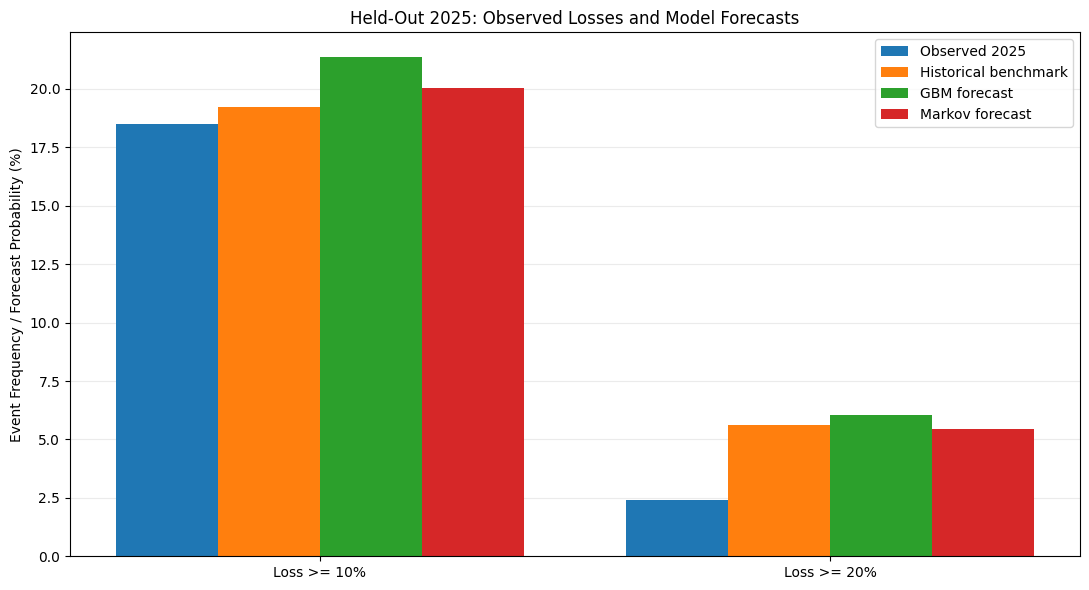

PASS: Final out-of-sample figure generated
PASS: Observed 2025 events match previous results
PASS: Adjusted intervals support cautious conclusions
PASS: Day 5 scientific results are internally consistent


In [40]:

# Day 5 - Step 6: Final out-of-sample comparison figure

# Focus on 10% and 20% losses.
# The 35% event is excluded from this figure because
# no such losses occurred during the 2025 evaluation.

plot_thresholds = [10, 20]

observed_rates = []
historical_rates = []
gbm_rates = []
markov_rates = []

for pct in plot_thresholds:

    outcome_row = oos_brier_df[
        oos_brier_df["Loss threshold"] == f"{pct}%"
    ].iloc[0]

    benchmark_row = historical_benchmark_df[
        historical_benchmark_df["Threshold"] == f"{pct}%"
    ].iloc[0]

    observed_rates.append(
        outcome_row["Observed frequency (%)"]
    )

    historical_rates.append(
        benchmark_row["Training forecast (%)"]
    )

    gbm_rates.append(
        outcome_row["GBM predicted (%)"]
    )

    markov_rates.append(
        outcome_row["Markov predicted (%)"]
    )

x = np.arange(len(plot_thresholds))
bar_width = 0.2

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - 1.5 * bar_width,
    observed_rates,
    width=bar_width,
    label="Observed 2025"
)

ax.bar(
    x - 0.5 * bar_width,
    historical_rates,
    width=bar_width,
    label="Historical benchmark"
)

ax.bar(
    x + 0.5 * bar_width,
    gbm_rates,
    width=bar_width,
    label="GBM forecast"
)

ax.bar(
    x + 1.5 * bar_width,
    markov_rates,
    width=bar_width,
    label="Markov forecast"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"Loss >= {pct}%" for pct in plot_thresholds]
)

ax.set_ylabel("Event Frequency / Forecast Probability (%)")
ax.set_title(
    "Held-Out 2025: Observed Losses and Model Forecasts"
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
plt.show()

# Independent final result consistency checks.
assert len(evaluation_windows_df) == 335

assert (
    int(evaluation_windows_df["event_10"].sum()) == 62
)

assert (
    int(evaluation_windows_df["event_20"].sum()) == 8
)

assert (
    int(evaluation_windows_df["event_35"].sum()) == 0
)

assert (
    len(historical_benchmark_df) == 3
)

assert (
    len(adjusted_bootstrap_df) == 3
)

# Verify every adjusted comparison interval
# includes zero, based on the observed results.
assert (
    (
        adjusted_bootstrap_df["98.33% CI lower"] <= 0
    )
    &
    (
        adjusted_bootstrap_df["98.33% CI upper"] >= 0
    )
).all()

print("PASS: Final out-of-sample figure generated")
print("PASS: Observed 2025 events match previous results")
print("PASS: Adjusted intervals support cautious conclusions")
print("PASS: Day 5 scientific results are internally consistent")


## 6. Discussion and limitations

The eventual conclusion must be based on verified experiments. We must not assume beforehand that regime switching performs better merely because volatility changes over time.

**Current limitations (Day 2):** Historical BTC/USDT data has been collected and analysed, but the full GBM and Markov regime-switching simulations have not yet been implemented. No final model-comparison results or downside-risk estimates are available.

**Expected final limitations:** Simplified two-state dynamics, normal conditional returns despite potential heavy tails, sensitivity to regime definitions, crypto market structural changes, USDT-denominated price data, and sparse independent extreme-loss observations in the held-out period.

**Web demo reference result:** To be populated from a verified notebook calculation after both models are implemented. Do **not** invent a reference number or tolerance.

**Next development step:** Implement and independently verify the constant-volatility GBM baseline using parameters estimated from the 2022–2024 calibration period. Preserve the 2025 evaluation observations for out-of-sample assessment.


## 6A. Focused research improvements: robustness, Markov theory and retrospective risk checks

These additional experiments **do not overwrite the verified Day-5 baseline**. They use a training-only model-selection exercise (2022–2023 fitting; 2024 validation). The 2025 period is used only for the final descriptive evaluation. Since some 2025 results were already inspected during the initial project, any expanded comparison made after that inspection must be described as **exploratory retrospective analysis**, not as a previously untouched confirmatory test.

The 7-, 14-, 21- and 30-day volatility windows are competing choices for the observed-state definition. Overlapping rolling windows can make inferred regimes mechanically persistent. Selection depends on **probability forecast validation**, not on how impressive transition probabilities look.

### 6A.1 Model-selection protocol (2022–2023 fit; 2024 validation)

Each candidate uses its own training-period volatility median, transition counts and next-day conditional returns. The main score is the mean of the 10% and 20% loss-event Brier scores on rolling 30-day windows whose outcomes are entirely in 2024. Validation windows overlap, so rankings should be interpreted cautiously.

In [ ]:
# M2: Model-selection experiment with 2022-2023 fitting and 2024 validation
# Keeps the original 2022-2024/2025 GBM and Markov baseline untouched.
ROBUSTNESS_WINDOWS = (7, 14, 21, 30)
EARLY_CUTOFF = pd.Timestamp("2024-01-01", tz="UTC")
FIT_SAMPLE = calibration_df[calibration_df["date"] < EARLY_CUTOFF].copy()
N_WINDOW_PATHS = 25_000
assert len(FIT_SAMPLE) == 730

def fit_observed_regime_window(returns_table, window):
    frame = returns_table[["date", "log_return"]].copy()
    frame["rv"] = frame["log_return"].rolling(window, min_periods=window).std(ddof=1)
    frame = frame.dropna(subset=["rv"]).reset_index(drop=True)
    threshold = float(frame["rv"].median())
    frame["state"] = (frame["rv"] >= threshold).astype(np.int8)
    s = frame["state"].to_numpy()
    counts = np.zeros((2, 2), dtype=np.int64)
    np.add.at(counts, (s[:-1], s[1:]), 1)
    assert (counts.sum(axis=1) > 0).all()
    matrix = counts / counts.sum(axis=1, keepdims=True)
    frame["next_return"] = frame["log_return"].shift(-1)
    conditioned = frame.dropna(subset=["next_return"])
    grouped = conditioned.groupby("state")["next_return"].agg(["mean", "std"]).reindex([0, 1])
    mus = grouped["mean"].to_numpy(dtype=float)
    sigmas = grouped["std"].to_numpy(dtype=float)
    assert np.isfinite(mus).all() and np.isfinite(sigmas).all() and (sigmas > 0).all()
    np.testing.assert_allclose(matrix.sum(axis=1), [1, 1], atol=1e-12)
    return {"window": window, "threshold": threshold, "P": matrix, "mu": mus, "sigma": sigmas}

# Reproduce the original 14-day fit using all 2022-2024 calibration data.
baseline_refit = fit_observed_regime_window(calibration_df, 14)
np.testing.assert_allclose(baseline_refit["P"], transition_matrix, atol=1e-12)
np.testing.assert_allclose(baseline_refit["mu"], regime_mu, atol=1e-12)
np.testing.assert_allclose(baseline_refit["sigma"], regime_sigma, atol=1e-12)
print("PASS: Original 14-day calibration reproduced")

# Build 2024 validation origins; all outcomes must exist within 2024.
v = calibration_df[["date", "close", "log_return"]].copy()
v["future_close"] = v["close"].shift(-HORIZON_DAYS)
v["future_date"] = v["date"].shift(-HORIZON_DAYS)
validation_origins = v[
    (v["date"] >= EARLY_CUTOFF) &
    (v["future_date"] < pd.Timestamp("2025-01-01", tz="UTC"))
].dropna(subset=["future_close"]).copy()
validation_origins["loss_fraction"] = (
    1 - validation_origins["future_close"] / validation_origins["close"]
)
assert len(validation_origins) == 336
validation_rows = []

for window in ROBUSTNESS_WINDOWS:
    fit = fit_observed_regime_window(FIT_SAMPLE, window)
    # Each historical state at date t uses only returns dated <= t.
    rolling = calibration_df["log_return"].rolling(window, min_periods=window).std(ddof=1)
    state_series = pd.Series(
        (rolling >= fit["threshold"]).astype(int).to_numpy(),
        index=calibration_df["date"]
    )
    origin_states = state_series.reindex(validation_origins["date"]).to_numpy(dtype=int)
    assert set(origin_states).issubset({0, 1})
    risk_by_state = {}
    for state in (0, 1):
        simulated, _ = simulate_markov_paths(
            initial_price=1.0, initial_state=state,
            transition_probs=fit["P"], regime_means=fit["mu"],
            regime_volatilities=fit["sigma"],
            horizon_days=HORIZON_DAYS, n_paths=N_WINDOW_PATHS,
            seed=26000 + window * 10 + state
        )
        simulated_losses = 1 - simulated[:, -1]
        risk_by_state[state] = {
            pct: float(np.mean(simulated_losses >= pct / 100))
            for pct in (10, 20)
        }
    score_parts = []
    for pct in (10, 20):
        predictions = np.array([risk_by_state[s][pct] for s in origin_states])
        actual = (validation_origins["loss_fraction"].to_numpy() >= pct / 100).astype(float)
        score_parts.append(float(np.mean((predictions - actual)**2)))
    validation_rows.append({
        "Window": window,
        "Validation Brier >=10%": score_parts[0],
        "Validation Brier >=20%": score_parts[1],
        "Mean validation Brier": np.mean(score_parts),
        "Calm duration": 1 / (1 - fit["P"][0, 0]),
        "Volatile duration": 1 / (1 - fit["P"][1, 1]),
        "Next-day vol ratio": fit["sigma"][1] / fit["sigma"][0]
    })

window_validation_df = pd.DataFrame(validation_rows).sort_values(
    ["Mean validation Brier", "Window"]
).reset_index(drop=True)
SELECTED_WINDOW_2024 = int(window_validation_df.loc[0, "Window"])
print("2024 validation ranking (lower Brier is better)")
display(window_validation_df.round(6))
print("Validation-selected window:", SELECTED_WINDOW_2024, "days")
print("Note: this is an exploratory comparison, not proof of model superiority.")
assert set(window_validation_df["Window"]) == set(ROBUSTNESS_WINDOWS)
assert np.isfinite(window_validation_df.select_dtypes(include="number")).all().all()

### 6A.2 Independent Markov occupancy mathematics

For day \(d\), starting from the calibration-period initial regime \(s\), the theoretical state probabilities are row \(s\) of \(P^d\). Comparing these probabilities with Monte Carlo simulated state frequencies checks the **state-transition mechanism** independently of Bitcoin forecasting accuracy. The expected duration in state \(i\) is \(1/(1-P_{ii})\), provided the state is not absorbing.

In [ ]:
# M3: Verify the entire 30-day Markov regime-occupancy curve
theory_occupancy = np.vstack([
    np.linalg.matrix_power(transition_matrix, d)[initial_regime]
    for d in range(HORIZON_DAYS + 1)
])
simulation_occupancy = np.column_stack([
    (markov_states == 0).mean(axis=0),
    (markov_states == 1).mean(axis=0)
])
np.testing.assert_allclose(theory_occupancy.sum(axis=1), 1.0, atol=1e-12)
np.testing.assert_allclose(simulation_occupancy.sum(axis=1), 1.0, atol=1e-12)
se = np.sqrt(theory_occupancy * (1 - theory_occupancy) / N_PATHS)
assert np.all(np.abs(theory_occupancy - simulation_occupancy) <= 4 * se + 0.002)
print("PASS: Day-by-day occupancy matches Markov P^d (4-SE tolerance + 0.2pp)")
print(f"Expected Calm duration: {1/(1-transition_matrix[0,0]):.3f} days")
print(f"Expected Volatile duration: {1/(1-transition_matrix[1,1]):.3f} days")
days_axis = np.arange(HORIZON_DAYS + 1)
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(days_axis, theory_occupancy[:,1]*100, label="Theory: P(Volatile)", lw=2)
ax.scatter(days_axis[::3], simulation_occupancy[::3,1]*100,
           label="Simulated: P(Volatile)", marker="o", s=18)
ax.set(xlabel="Forecast day", ylabel="Probability (%)",
       title="Markov regime occupancy: theoretical vs simulation")
ax.set_ylim(0,100); ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()

### 6A.3 Retrospective 2025 validation and risk diagnostics

The 2025 rolling forecasts from the existing notebook are reused. The additional checks below evaluate **forecast calibration**, **95% VaR exceptions** and **training-return tail behaviour**. A 30-day moving-block bootstrap is used to illustrate dependence-aware uncertainty in the VaR exception rate. The 335 overlapping 30-day outcomes are not treated as 335 independent experiments. No observed \(\ge35\%\) losses occurred in this sample, so there is insufficient test-period information to validate extreme-tail forecasts.

In [ ]:
# M4: Retrospective risk diagnostics for the already fitted 14-day baseline
# This does NOT refit a model to 2025 or overwrite previous Day-5 predictions.
from scipy.stats import kurtosis, skew

cal_array = np.asarray(cal_returns, dtype=float)
training_excess_kurtosis = float(kurtosis(cal_array, fisher=True, bias=False))
training_skew = float(skew(cal_array, bias=False))
empirical_abs_99 = float(np.quantile(np.abs(cal_array - mu_cal), .99))
normal_abs_99 = float(norm.ppf(.995) * sigma_cal)
print("TRAINING-ONLY DAILY RETURN DIAGNOSTICS")
print(f"Excess kurtosis: {training_excess_kurtosis:.3f}")
print(f"Skewness: {training_skew:.3f}")
print(f"99th percentile absolute centred return: empirical {100*empirical_abs_99:.2f}%, normal {100*normal_abs_99:.2f}%")
print("These are diagnostics, not evidence that any new return distribution was fitted.")

# Re-use 2025 observed event counts and risk forecasts.
rows = []
for pct in (10,20,35):
    actual = evaluation_windows_df[f"event_{pct}"].to_numpy(dtype=float)
    p_gbm = np.repeat(gbm_oos_probabilities[pct], len(actual))
    p_markov = np.array([
        markov_oos_probabilities[int(s)][pct]
        for s in evaluation_windows_df["initial_regime"]
    ])
    rows.append({
        "Threshold": f">={pct}%",
        "Observed frequency (%)": 100 * actual.mean(),
        "GBM mean forecast (%)": 100 * p_gbm.mean(),
        "Markov mean forecast (%)": 100 * p_markov.mean(),
        "GBM bias (pp)": 100 * (p_gbm-actual).mean(),
        "Markov bias (pp)": 100 * (p_markov-actual).mean(),
        "Observed events": int(actual.sum()
    )})
calibration_comparison_df = pd.DataFrame(rows)
display(calibration_comparison_df.round(3))
assert calibration_comparison_df["Observed events"].tolist() == [62,8,0]

# GBM 95% VaR follows directly from the lognormal 30-day return distribution.
z05 = norm.ppf(.05)
gbm_var95_fraction = float(
    1 - np.exp(mu_cal*HORIZON_DAYS +
               sigma_cal*np.sqrt(HORIZON_DAYS)*z05)
)
# Markov VaR depends on initial regime: independent Monte Carlo runs.
markov_var95_fraction = {}
for state in (0,1):
    path_check, _ = simulate_markov_paths(
        initial_price=1.0, initial_state=state,
        transition_probs=transition_matrix,
        regime_means=regime_mu, regime_volatilities=regime_sigma,
        horizon_days=HORIZON_DAYS, n_paths=120_000,
        seed=47000+state
    )
    markov_var95_fraction[state] = float(
        np.quantile(1 - path_check[:,-1], .95)
    )

actual_loss_fractions = evaluation_windows_df["realized_loss_30d"].to_numpy(dtype=float)
initial_states_2025 = evaluation_windows_df["initial_regime"].to_numpy(dtype=int)
exceptions_gbm = (actual_loss_fractions > gbm_var95_fraction).astype(float)
exceptions_markov = (
    actual_loss_fractions > np.array([markov_var95_fraction[s] for s in initial_states_2025])
).astype(float)

# Circular moving-block bootstrap of exception frequencies.
def block_bootstrap_rate_interval(events, length=30, reps=3000, seed=20261123):
    events = np.asarray(events, dtype=float)
    n = len(events); chunks = int(np.ceil(n/length))
    rng_local = np.random.default_rng(seed)
    offsets = np.arange(length)
    sample = np.empty(reps)
    for j in range(reps):
        starts = rng_local.integers(0,n,size=chunks)
        indices = ((starts[:,None]+offsets[None,:])%n).ravel()[:n]
        sample[j] = events[indices].mean()
    return 100*np.quantile(sample,[.025,.975])

var_backtest_rows = []
for name, exceptions in (("GBM",exceptions_gbm),("Markov",exceptions_markov)):
    ci = block_bootstrap_rate_interval(exceptions)
    var_backtest_rows.append({
        "Model": name, "VaR 95% exceptions": int(exceptions.sum()),
        "Observed exception rate (%)": 100*exceptions.mean(),
        "Block-bootstrap low (%)": float(ci[0]),
        "Block-bootstrap high (%)": float(ci[1]),
        "Nominal rate (%)": 5.0
    })
var_backtest_df = pd.DataFrame(var_backtest_rows)
display(var_backtest_df.round(3))
print("PASS: Retrospective diagnostics computed; overlapping windows acknowledged")
assert len(exceptions_gbm) == len(exceptions_markov) == 335
assert 0 <= gbm_var95_fraction <= 1
assert all(np.isfinite(v) for v in markov_var95_fraction.values())

### 6A.4 Interpretation and model freeze

The validation-ranked volatility window above is a **candidate for further analysis**, not an automatic replacement for the original 14-day model. The 2025 results had already been examined before this extension was proposed; any newly reported 2025 improvement must be labelled post-hoc/exploratory. The final website should continue to use the verified 14-day model unless a distinct model-version decision is documented and its calculations independently rechecked. A more complicated model is not automatically more accurate.

## 6B. Phase 1 research: regime diagnostics, EWMA and path-based losses

These experiments preserve the original approved 14-day observed-state Markov model and the original GBM baseline. The new candidates are selected on **2024 validation only** after fitting on 2022–2023; those chosen settings can then be refitted using 2022–2024. Because the original 2025 results have already been inspected, new analyses using 2025 are **exploratory and retrospective**, not untouched confirmatory tests.

The historical classification uses trailing overlapping volatility windows; persistent labels may reflect this calculation rather than genuine future-volatility predictability. A shuffled-return null comparison investigates that issue.

The approved EWMA benchmark uses a recursive daily conditional variance model with published RiskMetrics conventions (https://www.msci.com/documents/10199/dbb975aa-5dc2-4441-aa2d-ae34ab5f0945). It uses only prices available at each forecast origin. As with the existing Markov model, conditional returns are normal, so heavy-tail risk remains a limitation.

The extra *touch* metric measures whether a **daily closing price** at any point within 30 days falls at least 10% below the starting close. It does not measure unobserved intraday lows. This metric and maximum drawdown are secondary experiments, not replacements for the original terminal-loss, VaR and Expected Shortfall question.

In [ ]:
# R03-R04 / M5: Observed-regime audit and rolling-window persistence null test
# Uses training data only. Changing the historical order in the null simulation
# is a diagnostic, not an estimate of market forecast performance.
assert WINDOW == 14
original_regime_labels = regime_calibration_df["regime"].to_numpy(dtype=np.int8)
legacy_stay = float(np.mean(original_regime_labels[1:] == original_regime_labels[:-1]))
np.testing.assert_allclose(legacy_stay, transition_counts.trace()/transition_counts.sum(), atol=1e-12)
assert 0.90 < legacy_stay < 0.95
audit_next = regime_return_df[["regime", "next_log_return"]].copy()
audit_next["absolute_next_return"] = audit_next["next_log_return"].abs()
audit_next["absolute_change_gt_5pct"] = (audit_next["absolute_next_return"] >= 0.05).astype(int)
regime_audit = audit_next.groupby("regime").agg(
    n=("next_log_return", "size"),
    mean_next_return=("next_log_return", "mean"),
    next_day_sigma=("next_log_return", "std"),
    mean_absolute_next_return=("absolute_next_return", "mean"),
    next_day_abs_5pct_rate=("absolute_change_gt_5pct", "mean"),
).reindex([0, 1])
assert regime_audit["n"].to_numpy().tolist() == regime_sample_counts.tolist()
rng_audit = np.random.default_rng(20261123)
audit_training_returns = calibration_df["log_return"].dropna().to_numpy()
shuffle_stay_rates = []
for repeat in range(250):
    shuffled = rng_audit.permutation(audit_training_returns)
    rolling_null = pd.Series(shuffled).rolling(14, min_periods=14).std(ddof=1).dropna().to_numpy()
    threshold_null = float(np.median(rolling_null))
    synthetic_states = (rolling_null >= threshold_null).astype(np.int8)
    shuffle_stay_rates.append(float(np.mean(synthetic_states[1:] == synthetic_states[:-1])))
shuffle_stay_rates = np.asarray(shuffle_stay_rates)
audit_null_percentiles = np.quantile(shuffle_stay_rates, [0.025, 0.5, 0.975])
print("R03-R04: Next-day risk conditional on observed 14-day state")
display(regime_audit.round(6))
print(f"Original stay probability: {legacy_stay:.3%}")
print(f"Shuffled-return null (2.5%, median, 97.5%): {audit_null_percentiles}")
print("IMPORTANT: The shuffled series retains overlapping-window smoothing.")
print("State persistence alone is NOT evidence of predictable market volatility.")
assert len(shuffle_stay_rates) == 250
assert 0 <= legacy_stay <= 1 and np.isfinite(shuffle_stay_rates).all()
assert regime_audit["next_day_sigma"].gt(0).all()
print("PASS: Regime classification audit and 250 shuffled controls completed")


In [ ]:
# R05-R06 / M6: Compare 12 observed-state definitions on TRAIN 2022-23 / VALIDATE 2024
# Selection does not use 2025; the already-inspected 2025 evaluation stays exploratory.
M6_WINDOWS = [7, 14, 21, 30]
M6_QUANTILES = [0.50, 0.65, 0.75]
M6_VALIDATION_PATHS = 20_000
M6_TRAIN = calibration_df[calibration_df["date"] < "2024-01-01"].copy()
assert len(M6_TRAIN) == 730
def fit_quantile_regime(data, window, q):
    assert window >= 2 and 0 < q < 1
    frame = data[["date", "log_return"]].copy()
    frame["rolling"] = frame["log_return"].rolling(window, min_periods=window).std(ddof=1)
    frame = frame.dropna(subset=["rolling"]).reset_index(drop=True)
    threshold = float(frame["rolling"].quantile(q))
    frame["state"] = (frame["rolling"] >= threshold).astype(np.int8)
    labels = frame["state"].to_numpy()
    counts = np.zeros((2, 2), dtype=int)
    np.add.at(counts, (labels[:-1], labels[1:]), 1)
    assert (counts.sum(axis=1) >= 25).all(), "Insufficient state transitions"
    trans = counts / counts.sum(axis=1, keepdims=True)
    frame["next_return"] = frame["log_return"].shift(-1)
    stats = frame.dropna(subset=["next_return"]).groupby("state")["next_return"].agg(["mean", "std"]).reindex([0, 1])
    mu = stats["mean"].to_numpy(dtype=float)
    sigma = stats["std"].to_numpy(dtype=float)
    assert np.isfinite(mu).all() and np.isfinite(sigma).all()
    assert (sigma > 0).all()
    np.testing.assert_allclose(trans.sum(axis=1), 1, atol=1e-12)
    return {"window": int(window), "q": float(q), "threshold": threshold, "P": trans, "mu": mu, "sigma": sigma, "counts": counts}
# All 2024 outcomes stay in 2024. Use exactly the same origins for every candidate.
m6_price = calibration_df[["date", "close"]].copy()
m6_price["future_close"] = m6_price["close"].shift(-HORIZON_DAYS)
m6_price["future_date"] = m6_price["date"].shift(-HORIZON_DAYS)
m6_val = m6_price[(m6_price["date"] >= "2024-01-01") & (m6_price["future_date"] < "2025-01-01")].dropna().copy()
assert len(m6_val) == 336
m6_obs_loss = 1 - m6_val["future_close"].to_numpy() / m6_val["close"].to_numpy()
m6_results = []
for w in M6_WINDOWS:
    observed_rolling = calibration_df["log_return"].rolling(w, min_periods=w).std(ddof=1)
    for q in M6_QUANTILES:
        model = fit_quantile_regime(M6_TRAIN, w, q)
        labels_history = pd.Series((observed_rolling >= model["threshold"]).astype(int).to_numpy(), index=calibration_df["date"])
        states_2024 = labels_history.reindex(m6_val["date"]).to_numpy(dtype=int)
        by_state = {}
        for state in (0, 1):
            paths, _ = simulate_markov_paths(
                1.0, state, model["P"], model["mu"], model["sigma"],
                HORIZON_DAYS, M6_VALIDATION_PATHS,
                seed=62000 + 100*w + 10*int(100*q) + state
            )
            losses = 1 - paths[:, -1]
            by_state[state] = {pct: float(np.mean(losses >= pct/100)) for pct in (10, 20)}
        briers = [
            float(np.mean((np.array([by_state[state][pct] for state in states_2024])
                          - (m6_obs_loss >= pct/100).astype(float))**2))
            for pct in (10, 20)
        ]
        m6_results.append({
            "Window": w, "Threshold quantile": q,
            "Brier >=10%": briers[0], "Brier >=20%": briers[1],
            "Mean Brier": float(np.mean(briers)),
            "Volatility ratio": float(model["sigma"][1] / model["sigma"][0]),
            "Calm mean duration": 1 / (1-model["P"][0,0]),
            "Volatile mean duration": 1 / (1-model["P"][1,1]),
            "High-state outgoing transitions": int(model["counts"][1].sum()),
        })
m6_rank = pd.DataFrame(m6_results).sort_values(["Mean Brier", "Window", "Threshold quantile"]).reset_index(drop=True)
M6_SELECTED_WINDOW = int(m6_rank.loc[0, "Window"])
M6_SELECTED_QUANTILE = float(m6_rank.loc[0, "Threshold quantile"])
m6_selected_fit = fit_quantile_regime(calibration_df, M6_SELECTED_WINDOW, M6_SELECTED_QUANTILE)
print("R05-R06: Candidate ranking (fit 2022-23, validate 2024; lower Brier better)")
display(m6_rank.round(6))
print("Selected (2024 validation only): window", M6_SELECTED_WINDOW, "threshold quantile", M6_SELECTED_QUANTILE)
print("Original 14-day median model remains unchanged and is still the principal approved model.")
assert len(m6_rank) == 12 and m6_rank["Mean Brier"].notna().all()
assert np.isfinite(m6_rank.select_dtypes(include="number")).all().all()
print("PASS: 12 alternative regime definitions evaluated without 2025 model selection")


In [ ]:
# R06 supplementary: Dependence-aware 2024 uncertainty for selected vs original rules
# Fixed candidate list and selection use 2024 only; overlapping windows mean fewer independent outcomes.
def m6_forecast_origin_probabilities(window, q):
    fit = fit_quantile_regime(M6_TRAIN, window, q)
    vol = calibration_df["log_return"].rolling(window,min_periods=window).std(ddof=1)
    labels = pd.Series((vol >= fit["threshold"]).astype(int).to_numpy(),index=calibration_df["date"])
    origin_states = labels.reindex(m6_val["date"]).to_numpy(dtype=int)
    per_state = {}
    for st in (0,1):
        prices,_ = simulate_markov_paths(1.0,st,fit["P"],fit["mu"],fit["sigma"],30,80_000,seed=64000+st)
        losses = 1-prices[:,-1]
        per_state[st] = [np.mean(losses>=.10),np.mean(losses>=.20)]
    return np.array([per_state[st] for st in origin_states],dtype=float)
m6_original_predictions = m6_forecast_origin_probabilities(14,.50)
m6_selected_predictions = m6_forecast_origin_probabilities(M6_SELECTED_WINDOW,M6_SELECTED_QUANTILE)
m6_actual = np.column_stack([(m6_obs_loss>=.10).astype(float), (m6_obs_loss>=.20).astype(float)])
m6_score_difference = np.mean((m6_selected_predictions-m6_actual)**2-(m6_original_predictions-m6_actual)**2,axis=1)
m6_rng = np.random.default_rng(64099)
m6_boot_means = np.empty(3000)
for rep in range(3000):
    starts = m6_rng.integers(0,len(m6_score_difference),int(np.ceil(len(m6_score_difference)/30)))
    indices = ((starts[:,None]+np.arange(30)[None,:])%len(m6_score_difference)).ravel()[:len(m6_score_difference)]
    m6_boot_means[rep] = m6_score_difference[indices].mean()
m6_robustness = {
    "selected_minus_original_mean_brier":float(m6_score_difference.mean()),
    "95pct_block_bootstrap_interval":np.quantile(m6_boot_means,[.025,.975]).tolist(),
    "candidate_selection_reused_same_validation":True,
    "interpretation":"Exploratory selection comparison; post-selection uncertainty is optimistic"
}
print("2024 validation paired 30-day block-bootstrap selected - original:")
print(m6_robustness)
assert np.isfinite(m6_boot_means).all()
print("PASS: 2024 selected-regime improvement checked under overlapping-window uncertainty")


In [ ]:
# R07-R08 / M7: EWMA benchmark with correctly lagged observed variance
# EWMA produces next-day variance AFTER each currently available daily return.
# 0.94 is a published RiskMetrics reference, not an assumed Bitcoin optimum.
def ewma_nextday_variances(log_returns, mu, decay, initial_variance):
    if not (0 < decay <= 1) or initial_variance <= 0:
        raise ValueError("Invalid EWMA configuration")
    variance = float(initial_variance)
    out = np.empty(len(log_returns), dtype=float)
    for i, r in enumerate(np.asarray(log_returns, dtype=float)):
        if np.isfinite(r):
            variance = decay*variance + (1-decay)*(r-mu)**2
        out[i] = variance
    assert np.isfinite(out).all() and (out > 0).all()
    return out

def simulate_ewma_losses(initial_variance, mean_return, decay, horizon, n_paths, seed):
    if initial_variance <= 0 or not (0 < decay <= 1) or n_paths <= 0 or horizon <= 0:
        raise ValueError("Invalid EWMA scenario")
    rng = np.random.default_rng(seed)
    sigma2 = np.full(n_paths, initial_variance, dtype=float)
    log_values = np.zeros(n_paths)
    running_min_log = np.zeros(n_paths)
    running_max_log = np.zeros(n_paths)
    max_drawdown = np.zeros(n_paths)
    for day in range(horizon):
        log_r = mean_return + np.sqrt(sigma2) * rng.standard_normal(n_paths)
        log_values += log_r
        running_min_log = np.minimum(running_min_log, log_values)
        running_max_log = np.maximum(running_max_log, log_values)
        max_drawdown = np.maximum(max_drawdown, 1 - np.exp(log_values - running_max_log))
        sigma2 = decay*sigma2 + (1-decay)*(log_r-mean_return)**2
    return {
        "losses": -np.expm1(log_values),
        "min_log": running_min_log,
        "max_drawdown": max_drawdown,
    }

# Verification: fixed variance (decay=1) recovers the GBM terminal loss distribution.
m7_check = simulate_ewma_losses(sigma_cal**2, mu_cal, 1.0, 30, 80_000, 73001)
m7_analytic = float(norm.cdf((np.log1p(-0.10) - mu_cal*30)/(sigma_cal*np.sqrt(30))))
m7_observed = float(np.mean(m7_check["losses"] >= .10))
m7_se = np.sqrt(m7_analytic*(1-m7_analytic)/80_000)
assert abs(m7_observed-m7_analytic) <= 4*m7_se
m7_repeat = simulate_ewma_losses(sigma_cal**2, mu_cal, 1.0, 30, 80_000, 73001)
np.testing.assert_array_equal(m7_check["losses"], m7_repeat["losses"])
np.testing.assert_allclose(
    ewma_nextday_variances([.01, -.02, .03], 0, 1.0, .0003), .0003
)
print("PASS: EWMA reproducibility, lambda=1 constant-volatility limiting case, and analytic GBM agreement")

M7_DECAYS = [0.90, 0.94, 0.97, 0.98]
M7_VALIDATION_PATHS = 3_000
m7_mu_train = float(M6_TRAIN["log_return"].mean())
m7_var_train = float(M6_TRAIN["log_return"].var(ddof=1))
m7_score_rows = []
m7_obs = {pct: (m6_obs_loss >= pct/100).astype(float) for pct in (10,20)}
for decay in M7_DECAYS:
    observed_variance = ewma_nextday_variances(
        calibration_df["log_return"].to_numpy(), m7_mu_train, decay, m7_var_train
    )
    variance_series = pd.Series(observed_variance, index=calibration_df["date"])
    v_origins = variance_series.reindex(m6_val["date"]).to_numpy()
    forecasts = np.empty((len(m6_val), 2))
    for i, var in enumerate(v_origins):
        mc = simulate_ewma_losses(float(var), m7_mu_train, decay, 30, M7_VALIDATION_PATHS, seed=75000+i)
        forecasts[i] = [np.mean(mc["losses"] >= .10), np.mean(mc["losses"] >= .20)]
    b10 = float(np.mean((forecasts[:,0]-m7_obs[10])**2))
    b20 = float(np.mean((forecasts[:,1]-m7_obs[20])**2))
    m7_score_rows.append({"Decay": decay, "Brier >=10%": b10, "Brier >=20%": b20, "Mean Brier": (b10+b20)/2})
m7_rank = pd.DataFrame(m7_score_rows).sort_values(["Mean Brier", "Decay"]).reset_index(drop=True)
M7_SELECTED_DECAY = float(m7_rank.loc[0, "Decay"])
print("EWMA 2024 validation (training fixed to 2022-23):")
display(m7_rank.round(6))
print("Selected decay:", M7_SELECTED_DECAY)
print("The selection is a 2024 comparison, not a claim of out-of-sample 2025 superiority.")
assert len(m7_rank) == 4 and np.isfinite(m7_rank["Mean Brier"]).all()
print("PASS: EWMA candidate selection completed using 2024 validation only")


In [ ]:
# R09-R10 / M8: Frozen 2022-24 parameter estimates, 2025 retrospective comparison
# 2025 was previously inspected; treat NEW model comparisons as exploratory.
M8_EWMA_PATHS = 10_000
m8_var_2025_all = ewma_nextday_variances(
    price_df["log_return"].to_numpy(), mu_cal, M7_SELECTED_DECAY, sigma_cal**2
)
m8_var_index = pd.Series(m8_var_2025_all, index=price_df["date"])
m8_origin_var = m8_var_index.reindex(evaluation_windows_df["date"]).to_numpy()
assert np.isfinite(m8_origin_var).all() and (m8_origin_var > 0).all()
m8_ewma_forecasts = {pct: np.empty(len(m8_origin_var)) for pct in (10, 20, 35)}
m8_ewma_touch10 = np.empty(len(m8_origin_var))
for i, var in enumerate(m8_origin_var):
    sim = simulate_ewma_losses(float(var), mu_cal, M7_SELECTED_DECAY, 30, M8_EWMA_PATHS, seed=81000+i)
    for pct in (10,20,35):
        m8_ewma_forecasts[pct][i] = np.mean(sim["losses"] >= pct/100)
    m8_ewma_touch10[i] = np.mean(sim["min_log"] <= np.log(.9))

# Refit the 2024-selected Markov candidate using the full training period 2022-24.
# This is an EXPLORATORY alternative, and does not overwrite the original 14-day model.
m8_selected_states_2025 = pd.Series(
    (price_df["log_return"].rolling(M6_SELECTED_WINDOW, min_periods=M6_SELECTED_WINDOW).std(ddof=1)
     >= m6_selected_fit["threshold"]).astype(int).to_numpy(),
    index=price_df["date"]
).reindex(evaluation_windows_df["date"]).to_numpy(dtype=int)
m8_selected_state_probs = {}
for state in (0, 1):
    paths, _ = simulate_markov_paths(
        1.0, state, m6_selected_fit["P"], m6_selected_fit["mu"],
        m6_selected_fit["sigma"], 30, 150_000, seed=82000+state
    )
    losses = 1-paths[:,-1]
    m8_selected_state_probs[state] = {pct: float(np.mean(losses >= pct/100)) for pct in (10,20,35)}

m8_pred = {name: {} for name in ("GBM", "Original Markov", "Selected Markov", "EWMA", "Historical frequency")}
m8_rows = []
for pct in (10, 20, 35):
    y = evaluation_windows_df[f"event_{pct}"].to_numpy(dtype=float)
    historical_p = float((calibration_30day_df["loss_fraction"] >= pct/100).mean())
    m8_pred["Historical frequency"][pct] = np.full(len(y), historical_p)
    m8_pred["GBM"][pct] = np.full(len(y), float(gbm_oos_probabilities[pct]))
    m8_pred["Original Markov"][pct] = np.array([
        markov_oos_probabilities[int(st)][pct] for st in evaluation_windows_df["initial_regime"]
    ])
    m8_pred["Selected Markov"][pct] = np.array([
        m8_selected_state_probs[int(st)][pct] for st in m8_selected_states_2025
    ])
    m8_pred["EWMA"][pct] = m8_ewma_forecasts[pct]
    for name, values in m8_pred.items():
        forecast = values[pct]
        m8_rows.append({
            "Threshold": f">={pct}%", "Model": name,
            "Observed 2025 (%)": 100*y.mean(),
            "Mean forecast (%)": 100*forecast.mean(),
            "Brier": float(np.mean((forecast-y)**2))
        })
m8_results = pd.DataFrame(m8_rows)
print("2025 retrospective 30-day comparison (EWMA and selected Markov are exploratory):")
display(m8_results.round(6))
assert m8_results.shape[0] == 15
assert np.isfinite(m8_results["Brier"]).all()
# Paired 30-day block bootstrap: model score differences, with overlapping outcomes.
m8_differences = []
rng_blocks = np.random.default_rng(83000)
n_blocks = int(np.ceil(len(evaluation_windows_df)/30))
boot_indices = np.empty((2000, len(evaluation_windows_df)), dtype=int)
for b in range(2000):
    starts = rng_blocks.integers(0, len(evaluation_windows_df), n_blocks)
    boot_indices[b] = ((starts[:,None]+np.arange(30)[None,:]) % len(evaluation_windows_df)).ravel()[:len(evaluation_windows_df)]
for pct in (10,20,35):
    y = evaluation_windows_df[f"event_{pct}"].to_numpy(dtype=float)
    for compared, reference in (("Original Markov","GBM"), ("EWMA","GBM"), ("EWMA","Original Markov"), ("Selected Markov","Original Markov")):
        d = (m8_pred[compared][pct]-y)**2 - (m8_pred[reference][pct]-y)**2
        samples = np.mean(d[boot_indices],axis=1)
        lo,hi = np.quantile(samples,[0.025,0.975])
        m8_differences.append({"Threshold":f">={pct}%","Compared":compared,"Reference":reference,
                               "Brier difference":float(d.mean()),"95% lower":lo,"95% upper":hi})
m8_bootstrap = pd.DataFrame(m8_differences)
display(m8_bootstrap.round(7))
print("Confidence intervals above are exploratory and NOT familywise-adjusted.")
print("With no 35% observed losses, no general extreme-tail skill claim is justified.")
assert np.isfinite(m8_bootstrap[["Brier difference","95% lower","95% upper"]]).all().all()
print("PASS: Three-model 2025 validation, historical benchmark and dependence-aware uncertainty completed")


In [ ]:
# R11-R12 / M9: In-horizon daily-close loss touching and maximum drawdown
# These are SECONDARY exploratory risk metrics, distinct from terminal VaR/ES.
M9_PATHS = 80_000
m9_gbm = simulate_gbm_paths(S0, mu_cal, sigma_cal, 30, M9_PATHS, seed=91001)
m9_markov, m9_markov_states = simulate_markov_paths(
    S0, initial_regime, transition_matrix, regime_mu, regime_sigma,
    30, M9_PATHS, seed=91002
)
m9_origin_var = float(m8_var_index.loc[pd.Timestamp("2024-12-31", tz="UTC")])
m9_ewma = simulate_ewma_losses(m9_origin_var, mu_cal, M7_SELECTED_DECAY, 30, M9_PATHS, seed=91003)
def path_metrics(model, paths):
    normalized = paths / paths[:,[0]]
    loss = 1-normalized[:,-1]
    breached = np.min(normalized[:,1:],axis=1) <= .90
    running_peak = np.maximum.accumulate(normalized,axis=1)
    max_dd = np.max(1-normalized/running_peak, axis=1)
    return {
        "Model": model,
        "Terminal loss >=10% (%)": 100*np.mean(loss>=.10),
        "Touched 10% loss (%)": 100*np.mean(breached),
        "Mean max drawdown (%)": 100*np.mean(max_dd),
        "95% VaR (USDT)": INITIAL_INVESTMENT*np.quantile(loss,.95),
        "95% ES (USDT)": INITIAL_INVESTMENT*np.mean(loss[loss>=np.quantile(loss,.95)])
    }
m9_output = [
    path_metrics("GBM",m9_gbm),
    path_metrics("Original Markov",m9_markov),
    {
        "Model":"EWMA",
        "Terminal loss >=10% (%)": 100*np.mean(m9_ewma["losses"]>=.10),
        "Touched 10% loss (%)": 100*np.mean(m9_ewma["min_log"]<=np.log(.9)),
        "Mean max drawdown (%)":100*np.mean(m9_ewma["max_drawdown"]),
        "95% VaR (USDT)": INITIAL_INVESTMENT*np.quantile(m9_ewma["losses"],.95),
        "95% ES (USDT)": INITIAL_INVESTMENT*np.mean(
            m9_ewma["losses"][m9_ewma["losses"]>=np.quantile(m9_ewma["losses"],.95)]
        ),
    }
]
m9_scenarios = pd.DataFrame(m9_output)
display(m9_scenarios.round(3))
assert (m9_scenarios["Touched 10% loss (%)"] >= m9_scenarios["Terminal loss >=10% (%)"]-0.2).all()
# Historical evaluation of daily close touch events (a touch does not require a terminal loss).
m9_close_2025 = eval_2025_df["close"].to_numpy()
m9_observed_touch = np.array([
    np.min(m9_close_2025[i+1:i+31]) <= .90*m9_close_2025[i]
    for i in range(335)
],dtype=float)
# GBM and Markov forecasts need matching initial-state conditional probabilities.
m9_gbm_touch_prob = float(np.mean(np.min(m9_gbm[:,1:]/m9_gbm[:,[0]],axis=1)<=.90))
m9_markov_touch_by_state = {}
for st in (0,1):
    tmp,_ = simulate_markov_paths(
        1.0,st,transition_matrix,regime_mu,regime_sigma,30,M9_PATHS,seed=92000+st
    )
    m9_markov_touch_by_state[st] = float(np.mean(np.min(tmp[:,1:],axis=1)<=.90))
m9_touch_predictors = {
    "GBM":np.full(335,m9_gbm_touch_prob),
    "Original Markov":np.array([
        m9_markov_touch_by_state[int(s)] for s in evaluation_windows_df["initial_regime"]
    ]),
    "EWMA":m8_ewma_touch10,
}
m9_touch_table = pd.DataFrame([
    {
        "Model":name,
        "Observed 2025 touch (%)":100*m9_observed_touch.mean(),
        "Forecast mean (%)":100*values.mean(),
        "Brier":float(np.mean((values-m9_observed_touch)**2))
    } for name,values in m9_touch_predictors.items()
])
print("Exploratory 2025 daily-close threshold-touch evaluation:")
display(m9_touch_table.round(6))
assert all(np.isfinite(values).all() for values in m9_touch_predictors.values())
assert np.isfinite(m9_touch_table["Brier"]).all()
print("PASS: Terminal risk, daily-close touches, max drawdown and exploratory observed-path checks completed")


In [ ]:
# R08/R10/R12 final checks: EWMA Monte Carlo convergence and touch-score uncertainty
# EWMA reference scenario uses the 2024-selected decay and 2024-12-31 origin variance.
M11_COUNTS = [1000, 5000, 10000, 30000]
M11_SEEDS = [96001, 96002, 96003, 96004, 96005]
m11_reference = simulate_ewma_losses(m9_origin_var,mu_cal,M7_SELECTED_DECAY,30,150_000,seed=96000)
m11_reference_p10 = float(np.mean(m11_reference["losses"]>=.10))
m11_ewma_records=[]
for count in M11_COUNTS:
    estimates=[]
    for seed in M11_SEEDS:
        simulated = simulate_ewma_losses(m9_origin_var,mu_cal,M7_SELECTED_DECAY,30,count,seed=seed)
        estimates.append(float(np.mean(simulated["losses"]>=.10)))
    m11_ewma_records.append({
        "Paths":count,
        "Mean P(loss>=10%)":float(np.mean(estimates)),
        "Std across seeds":float(np.std(estimates,ddof=1)),
        "Mean absolute error to 150k reference":float(np.mean(np.abs(np.array(estimates)-m11_reference_p10))),
        "Monte Carlo reference":m11_reference_p10
    })
m11_ewma_convergence = pd.DataFrame(m11_ewma_records)
print("EWMA Monte Carlo convergence: 5 independent seeds per path count")
display(m11_ewma_convergence.round(6))
assert len(m11_ewma_convergence)==4 and np.isfinite(m11_ewma_convergence.select_dtypes(include="number")).all().all()
# The law of large numbers does not require each noisy sequence to improve monotonically.
# With five independent seeds, average empirical error is expected to decrease in general.
assert m11_ewma_convergence["Mean absolute error to 150k reference"].iloc[-1] < \
       m11_ewma_convergence["Mean absolute error to 150k reference"].iloc[0]

# Compare touch predictions with paired moving-block bootstrap on overlapping 30-day windows.
m11_touch_differences=[]
m11_rng=np.random.default_rng(96099)
m11_n=len(m9_observed_touch)
m11_index=np.empty((3000,m11_n),dtype=int)
for b in range(3000):
    starts=m11_rng.integers(0,m11_n,int(np.ceil(m11_n/30)))
    m11_index[b]=((starts[:,None]+np.arange(30)[None,:])%m11_n).ravel()[:m11_n]
for contender,benchmark in [("Original Markov","GBM"),("EWMA","GBM"),("EWMA","Original Markov")]:
    diff=(m9_touch_predictors[contender]-m9_observed_touch)**2 - \
         (m9_touch_predictors[benchmark]-m9_observed_touch)**2
    lower,upper=np.quantile(np.mean(diff[m11_index],axis=1),[.025,.975])
    m11_touch_differences.append({
        "Compared":contender,"Reference":benchmark,
        "Brier difference":float(np.mean(diff)),
        "95% lower":float(lower),"95% upper":float(upper)
    })
m11_touch_bootstrap=pd.DataFrame(m11_touch_differences)
print("Exploratory 2025 threshold-touch Brier paired bootstrap")
display(m11_touch_bootstrap.round(6))
print("CAUTION: 2025 was inspected before this new metric was chosen; not a fresh holdout.")
assert np.isfinite(m11_touch_bootstrap.select_dtypes(include="number")).all().all()
print("PASS: EWMA Monte Carlo convergence and touch-risk uncertainty verified")


In [ ]:
# R13-R14 / M10: Reproducible scientific decision and model freeze
# A model change is justified by validation evidence, not by making Markov look better.
print("PHASE 1 RESEARCH SUMMARY")
print("-" * 68)
print(f"Original rolling regime: 14 days, training-median threshold; P(stay)={legacy_stay:.3%}")
print(f"Shuffled-return persistence median={audit_null_percentiles[1]:.3%}; overlap effects must be disclosed.")
print("Best 2024 candidate observed-state rule:",
      f"window={M6_SELECTED_WINDOW}, quantile={M6_SELECTED_QUANTILE:.2f}.")
print("Best 2024 EWMA decay:", M7_SELECTED_DECAY)
print("Original 2022-2024 GBM/Markov parameters and 2025 baseline comparisons preserved.")
print("New 2025 comparisons are EXPLORATORY because 2025 outcomes were previously reviewed.")
print("No claim of superior extreme-loss forecasting without independent evidence.")
print("Model parameters for eventual website must be copied only after checks and clear model-version decision.")
assert set(m8_results["Model"]) == {
    "GBM","Original Markov","Selected Markov","EWMA","Historical frequency"
}
assert len(m9_scenarios) == 3
print("PASS: Research audits, candidate comparisons, EWMA, uncertainty and path-based metrics are reproducibly specified")

# Machine-readable evidence used by CI to retain measured results, not only PASS notices.
import json
phase1_measured_results = {
    "legacy_stay_probability": legacy_stay,
    "shuffled_stay_quantiles": audit_null_percentiles.tolist(),
    "next_day_audit": regime_audit.reset_index().to_dict(orient="records"),
    "candidate_markov_2024_ranking": m6_rank.to_dict(orient="records"),
    "candidate_markov_2024_robustness": m6_robustness,
    "selected_markov": {"window": M6_SELECTED_WINDOW, "quantile": M6_SELECTED_QUANTILE},
    "ewma_2024_ranking": m7_rank.to_dict(orient="records"),
    "selected_ewma_decay": M7_SELECTED_DECAY,
    "retrospective_2025_comparison": m8_results.to_dict(orient="records"),
    "retrospective_2025_block_bootstrap": m8_bootstrap.to_dict(orient="records"),
    "scenario_risk_metrics": m9_scenarios.to_dict(orient="records"),
    "retrospective_2025_touch_results": m9_touch_table.to_dict(orient="records"),
    "ewma_monte_carlo_convergence": m11_ewma_convergence.to_dict(orient="records"),
    "retrospective_2025_touch_bootstrap": m11_touch_bootstrap.to_dict(orient="records"),
}
print("PHASE1_RESULT_JSON=" + json.dumps(
    phase1_measured_results,
    separators=(",", ":"), allow_nan=False,
    default=lambda item: item.item() if isinstance(item, np.generic) else str(item)
))


## 7. References

These are **starting sources**. Read and verify the publication details and dataset terms before citing them in a completed research report.

1. Binance, "Binance Public Data," GitHub repository. [Online]. Available: https://github.com/binance/binance-public-data (historical BTC/USDT data source).
2. F. Black and M. Scholes, "The pricing of options and corporate liabilities," *Journal of Political Economy*, vol. 81, no. 3, pp. 637–654, 1973, doi: [10.1086/260062](https://doi.org/10.1086/260062) (background on lognormal asset-price modelling).
3. A. M. Law, *Simulation Modeling and Analysis*, 5th ed., McGraw-Hill, 2015 (simulation design and verification background).

Additional peer-reviewed studies on Bitcoin volatility and regime-switching models will be reviewed for the full literature discussion.